## Cell 1 — Wholesale forecast for carrot, leeks, and tomato

This notebook keeps the working A/B pipeline unchanged and adds **Experiment C only when the real DOA cultivation-progress CSV is available**.

- **A:** price history + seasonality
- **B:** A + origin weather + diesel + USD/LKR + inflation + finished-season historical extent
- **C:** B + **national within-season cultivation progress**
- Train: issue weeks through 2022-12-31
- Calibration: 2023
- Test: 2024–2025
- Horizons: 1, 2, 4, 8, 12 weeks
- Primary uncertainty model: LightGBM quantile 0.05 / 0.50 / 0.95 + chronological conformal calibration
- XGBoost is the robustness comparison; SARIMAX remains the classical baseline.

**Important limits for Experiment C**
- C uses **national** crop-progress rows only so the feature has one consistent spatial meaning across all years.
- District rows remain in the audit data only; they are not scored in C.
- 2023 has only two national reports: **15 April** and **15 May**.
- 2019 has only one national report: **15 December**.
- District rows exist only for **Yala 2018 carrot and leeks**, so district-level C cannot be evaluated on 2023 or 2024–2025.
- Weeks with no valid exact-season national report remain outside the C comparison.
- The latest known report is carried only within its exact Maha/Yala season; no arbitrary 62-day expiry is used.
- A and B still run exactly as before.


## Cell 2 — Drive, CPU, and the six upload files

**Output to show:** `runtime: CPU`, six files with sizes in MB, `PASS six files`, and the two parameter dictionaries.

---

In [1]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd

try:
    from google.colab import drive
except ImportError:
    raise SystemExit("Open this notebook in Google Colab.")

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/DS322-member2")
if not DRIVE.is_dir():
    raise SystemExit(f"Missing Drive folder: {DRIVE}")

# ------------------------------------------------------------
# Safe CPU / GPU runtime check
# ------------------------------------------------------------

nvidia_smi = shutil.which("nvidia-smi")

if nvidia_smi is None:
    print("runtime: CPU")
else:
    completed = subprocess.run(
        [nvidia_smi, "-L"],
        capture_output=True,
        text=True
    )

    if completed.returncode == 0 and "GPU" in completed.stdout:
        raise SystemExit(
            "Switch the runtime to CPU. "
            "A GPU does not train these models."
        )

    print("runtime: CPU")

folders = [
    "00_upload",
    "01_from_notebook1/audit",
    "01_from_notebook1/panel",
    "01_from_notebook1/experiment_a",
    "01_from_notebook1/experiment_b",
    "01_from_notebook1/experiment_c",
    "01_from_notebook1/evaluation",
    "01_from_notebook1/notes",
    "01_from_notebook1/plots",
    "02_from_notebook2/inference",
    "02_from_notebook2/studio_json",
    "02_from_notebook2/runtime_demo",
]

for folder in folders:
    (DRIVE / folder).mkdir(
        parents=True,
        exist_ok=True
    )

needed = [
    "Vegetable Prices.xlsx",
    "harti_prices_weekly_long.csv",
    "harti_prices_monthly_long.csv",
    "weather_weekly_open_meteo.csv",
    "macros_published.csv",
    "dcs_highland_seasonal.csv",
]

rows = []
missing = []

for name in needed:
    path = DRIVE / "00_upload" / name

    if not path.is_file():
        missing.append(name)
        continue

    rows.append({
        "file": name,
        "MB": round(
            path.stat().st_size / 1e6,
            2
        )
    })

print(
    pd.DataFrame(rows).to_string(
        index=False
    )
)

if missing:
    raise SystemExit(
        f"missing uploads: {missing}"
    )

if (DRIVE / "00_code").exists():
    raise SystemExit(
        "Delete 00_code. "
        "This run does not use a project zip."
    )

print("PASS six core files")

# ------------------------------------------------------------
# Experiment C input
# ------------------------------------------------------------

# Experiment C uses one additional REAL source file.
# It is optional here so A/B can still run if C is not ready.

c_file = (
    DRIVE
    / "00_upload"
    / "doa_cultivation_progress.csv"
)

if c_file.is_file():

    print(
        "Experiment C input FOUND:",
        c_file,
        round(
            c_file.stat().st_size / 1e6,
            3
        ),
        "MB"
    )

else:

    print(
        "Experiment C input NOT FOUND yet:",
        c_file
    )

    print(
        "A/B will still run. "
        "C cells will save NOT_READY status "
        "rather than inventing data."
    )

# ------------------------------------------------------------
# Install packages
# ------------------------------------------------------------

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "lightgbm",
    "xgboost",
    "statsmodels",
    "openpyxl",
    "pyarrow",
])

import lightgbm
import xgboost
import statsmodels

print(
    "lightgbm",
    lightgbm.__version__
)

print(
    "xgboost",
    xgboost.__version__
)

print(
    "statsmodels",
    statsmodels.__version__
)

print(
    "statsforecast is not installed. "
    "SARIMAX order stays "
    "(1, 1, 1) x (1, 0, 0, 52)."
)

# ------------------------------------------------------------
# Save environment versions
# ------------------------------------------------------------

import json

environment_versions = {
    "python":
        sys.version.split()[0],

    "lightgbm":
        lightgbm.__version__,

    "xgboost":
        xgboost.__version__,

    "statsmodels":
        statsmodels.__version__,

    "pandas":
        pd.__version__,
}

env_path = (
    DRIVE
    / "01_from_notebook1"
    / "notes"
    / "environment_versions.json"
)

env_path.write_text(
    json.dumps(
        environment_versions,
        indent=2
    ),
    encoding="utf-8"
)

print(
    "environment versions",
    environment_versions
)

print(
    "saved",
    env_path
)

# ------------------------------------------------------------
# Fixed LightGBM settings
# ------------------------------------------------------------

LGB_FIXED = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "n_jobs": 1,
    "verbosity": -1,
    "random_state": 42,
}

# ------------------------------------------------------------
# Fixed XGBoost settings
# ------------------------------------------------------------

XGB_FIXED = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "early_stopping_rounds": 50,
    "n_jobs": 1,
    "random_state": 42,
}

print(
    "LightGBM fixed defaults",
    LGB_FIXED
)

print(
    "XGBoost fixed defaults",
    XGB_FIXED
)

print(
    "Tree-count selection: early stopping uses only an internal "
    "2022 validation slice inside the training period."
)

print(
    "The 2023 block is reserved exclusively for conformal calibration "
    "and is never used for early stopping or model selection."
)

print(
    "Laptop run: Optuna, "
    "15 LightGBM trials, "
    "8 XGBoost trials, "
    "horizon 4, "
    "2023 pinball, "
    "seed 42."
)

print(
    "This Colab run: "
    "the fixed defaults above. "
    "The numbers can differ."
)

# ------------------------------------------------------------
# Save hyperparameter note
# ------------------------------------------------------------

note = (
    DRIVE
    / "01_from_notebook1"
    / "notes"
    / "hyperparameters.txt"
)

note.write_text(
    "Colab uses the defaults in htfe/models/trees.py "
    "before Optuna update.\n"
    f"LGB_FIXED={LGB_FIXED}\n"
    f"XGB_FIXED={XGB_FIXED}\n"
    "Early stopping selects the tree count on target weeks in 2022, "
    "inside the training period. Final tree models are then refit on all "
    "eligible pre-2023 training rows using the selected tree count. "
    "The 2023 block is reserved exclusively for CQR calibration.\n"
    "Quantiles 0.05, 0.50, 0.95. Seed 42.\n"
    "No saved Optuna params file was "
    "in the project folder.\n"
    "The laptop run used Optuna "
    "(15 LGB / 8 XGB). "
    "This run does not.\n",
    encoding="utf-8",
)

print(
    "saved",
    note
)

validation_protocol = {
    "training_period": "eligible target weeks through 2022-12-31",
    "early_stopping_selector_train": "eligible training rows with target_week <= 2021-12-31",
    "early_stopping_selector_validation": "eligible training rows with target_week in calendar year 2022",
    "final_tree_refit": "all eligible training rows through 2022-12-31 after tree-count selection",
    "conformal_calibration": "2023 only; never used for early stopping or model selection",
    "held_out_test": "2024-2025",
    "random_split_used": False,
    "optuna_used_in_final_colab_run": False,
}

protocol_path = (
    DRIVE
    / "01_from_notebook1"
    / "notes"
    / "validation_protocol.json"
)

protocol_path.write_text(
    json.dumps(
        validation_protocol,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "saved",
    protocol_path,
)

print("\n✅ SETUP CELL COMPLETE")

Mounted at /content/drive
runtime: CPU
                         file    MB
        Vegetable Prices.xlsx  3.70
 harti_prices_weekly_long.csv 98.47
harti_prices_monthly_long.csv 22.70
weather_weekly_open_meteo.csv  1.14
         macros_published.csv  0.08
    dcs_highland_seasonal.csv  0.14
PASS six core files
Experiment C input FOUND: /content/drive/MyDrive/DS322-member2/00_upload/doa_cultivation_progress.csv 0.079 MB
lightgbm 4.6.0
xgboost 3.4.1
statsmodels 0.15.0
statsforecast is not installed. SARIMAX order stays (1, 1, 1) x (1, 0, 0, 52).
environment versions {'python': '3.13.16', 'lightgbm': '4.6.0', 'xgboost': '3.4.1', 'statsmodels': '0.15.0', 'pandas': '2.2.3'}
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/notes/environment_versions.json
LightGBM fixed defaults {'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'n_jobs': 1, 'verbosity': -1, 'random_state': 42}
XGBoost fixed defaults {'

## Cell 3 — Excel audit — four sheets, header row 4

**Output to show:** four sheet names, the footer on `Retail - W` containing `Source:Data Mgt.Division/HARTI`, the blank-year neighbourhood on `Retail - M`, and the `'o'` cell (2019, Colombo, BIG ONIONS Local, W33).

---

In [2]:
from pathlib import Path
import pandas as pd

xlsx = DRIVE / "00_upload" / "Vegetable Prices.xlsx"
book = pd.ExcelFile(xlsx)
print("sheets", book.sheet_names)
assert book.sheet_names == ["Retail - W", "Wholesale - W", "Retail - M", "Wholesale - M"]

shapes = []
for sheet in book.sheet_names:
    raw = pd.read_excel(xlsx, sheet_name=sheet, header=None)
    title = raw.iloc[1, 0]
    header = raw.iloc[3].tolist()
    print("\n==", sheet, "==")
    print("title:", title)
    print("header row:", header)
    print("raw shape", raw.shape)
    print(raw.iloc[4:6].to_string())
    df = pd.read_excel(xlsx, sheet_name=sheet, header=3)
    print("header=3 shape", df.shape)
    print(df.columns.tolist())
    year_col = "YEAR" if "YEAR" in df.columns else "Year"
    years = pd.to_numeric(df[year_col], errors="coerce")
    shapes.append({
        "sheet": sheet,
        "raw_rows": raw.shape[0],
        "raw_cols": raw.shape[1],
        "title": title,
        "first_year": int(years.min()),
        "last_year": int(years.max()),
    })
print(pd.DataFrame(shapes).to_string(index=False))

retail_w = pd.read_excel(xlsx, sheet_name="Retail - W", header=None)
print(retail_w.tail(3).astype(str).to_string())

retail_m = pd.read_excel(xlsx, sheet_name="Retail - M", header=3)
year_num = pd.to_numeric(retail_m["YEAR"], errors="coerce")
blank = retail_m.loc[year_num.isna()]
print("blank-year rows", len(blank))
if len(blank):
    print(retail_m.loc[blank.index[0] - 1: blank.index[0] + 1].to_string())

whole_w = pd.read_excel(xlsx, sheet_name="Wholesale - W", header=3)
w33 = pd.to_numeric(whole_w["W33"], errors="coerce")
bad = whole_w.loc[w33.isna() & whole_w["W33"].notna(), ["Year", "Location", "Varaity", "W33"]]
print("non-numeric W33")
print(bad.to_string(index=False))

out = DRIVE / "01_from_notebook1" / "audit" / "sheet_shapes.csv"
pd.DataFrame(shapes).to_csv(out, index=False)
print("saved", out)
print("PASS four sheets, header=3")

sheets ['Retail - W', 'Wholesale - W', 'Retail - M', 'Wholesale - M']

== Retail - W ==
title: Weekly Average Retail Prices of Vegetables from 2016 to 2025 in all locations (Rs./Kg)
header row: ['Year', 'Location', 'Varaity', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9', 'W10', 'W11', 'W12', 'W13', 'W14', 'W15', 'W16', 'W17', 'W18', 'W19', 'W20', 'W21', 'W22', 'W23', 'W24', 'W25', 'W26', 'W27', 'W28', 'W29', 'W30', 'W31', 'W32', 'W33', 'W34', 'W35', 'W36', 'W37', 'W38', 'W39', 'W40', 'W41', 'W42', 'W43', 'W44', 'W45', 'W46', 'W47', 'W48', 'W49', 'W50', 'W51', 'W52', np.float64(nan)]
raw shape (8722, 56)
     0        1                    2       3       4       5       6       7       8       9       10      11      12      13      14     15     16     17      18      19      20      21      22      23      24      25      26      27      28      29      30      31      32      33      34      35      36      37      38      39      40     41      42      43      44      45    

## Cell 4 — Who is in the file, and how much is missing

---

Retail - W n_locations 37 n_items 23
 items ['ASH PLANTAINS', 'BEETROOT', 'BIG ONIONS Imported', 'BIG ONIONS Local', 'BITTER GOURD', 'BRINJALS', 'CABBAGE', 'CAPSICUM', 'CARROT', 'CUCUMBER', 'DRUMSTIC', 'GREEN BEANS', 'GREEN CHILLIES', 'KNOL-KHOL', 'LADIES FINGERS', 'LEEKS', 'LIME', 'LONG BEANS', 'LUFFA', 'PUMPKIN', 'RADDISH', 'SNAKE GOURD', 'TOMATOES']
Wholesale - W n_locations 20 n_items 24
 items ['ASH PLANTAINS', 'BEETROOT', 'BIG ONIONS', 'BIG ONIONS Imported', 'BIG ONIONS Local', 'BITTER GOURD', 'BRINJALS', 'CABBAGE', 'CAPSICUM', 'CARROT', 'CUCUMBER', 'DRUMSTIC', 'GREEN BEANS', 'GREEN CHILLIES', 'KNOL-KHOL', 'LADIES FINGERS', 'LEEKS', 'LIME', 'LONG BEANS', 'LUFFA', 'PUMPKIN', 'RADDISH', 'SNAKE GOURD', 'TOMATOES']
Retail - M n_locations 37 n_items 26
 items ['ASH PLANTAINS', 'BEETROOT', 'BIG ONIONS', 'BIG ONIONS Imported', 'BIG ONIONS Local', 'BITTER GOURD', 'BRINJALS', 'CABBAGE', 'CAPSICUM', 'CARROT', 'CUCUMBER', 'DRUMSTIC', 'GREEN BEANS', 'GREEN CHILLIES', 'KNOL-KHOL', 'LADIES FIN

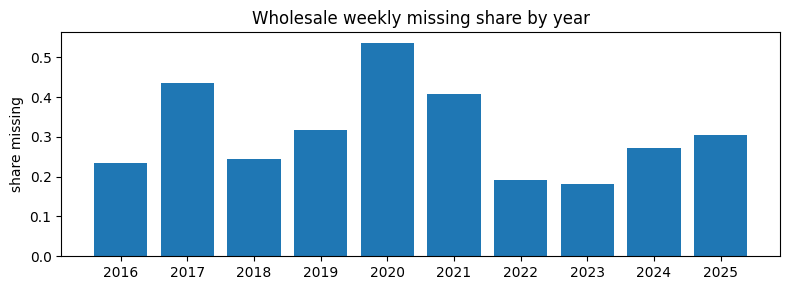

        sheet  year  missing_share
Wholesale - W  2020         0.5358
Wholesale - W  2021         0.4070
2020 and 2021 are the high bars. Do not fill them.
Earlier wholesale-weekly missing share: 2020 about 0.536, 2021 about 0.407.
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/audit/missing_by_year.csv /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/wholesale_weekly_missing_by_year.png


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

xlsx = DRIVE / "00_upload" / "Vegetable Prices.xlsx"
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
WEEKS = [f"W{i}" for i in range(1, 53)]

def load(sheet):
    df = pd.read_excel(xlsx, sheet_name=sheet, header=3)
    year_col = "YEAR" if "YEAR" in df.columns else "Year"
    df = df.rename(columns={year_col: "year"})
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    df = df.dropna(subset=["year"])
    df = df[~df.astype(str).apply(lambda row: row.str.contains("Source:", case=False).any(), axis=1)]
    return df

frames = {
    "Retail - W": (load("Retail - W"), WEEKS),
    "Wholesale - W": (load("Wholesale - W"), WEEKS),
    "Retail - M": (load("Retail - M"), MONTHS),
    "Wholesale - M": (load("Wholesale - M"), MONTHS),
}
summary = []
by_year_rows = []
for name, (df, cols) in frames.items():
    values = df[cols].apply(pd.to_numeric, errors="coerce")
    summary.append({"sheet": name, "rows": len(df), "missing_share": round(float(values.isna().to_numpy().mean()), 4)})
    long = values.copy()
    long["year"] = df["year"].astype(int).to_numpy()
    melted = long.melt(id_vars="year", value_vars=cols, value_name="price")
    grouped = melted.groupby("year")["price"].apply(lambda s: round(float(s.isna().mean()), 4))
    for year, share in grouped.items():
        by_year_rows.append({"sheet": name, "year": int(year), "missing_share": share})
    item_col = "ITEM" if "ITEM" in df.columns else "Varaity"
    locations = sorted(df["Location"].dropna().astype(str).unique())
    print(name, "n_locations", len(locations), "n_items", df[item_col].nunique())
    print(" items", sorted(df[item_col].dropna().astype(str).unique()))

print(pd.DataFrame(summary).to_string(index=False))
print("Earlier audit, for comparison only: retail weekly ~0.255, wholesale weekly ~0.307, retail monthly ~0.163, wholesale monthly ~0.325.")

whole_w = frames["Wholesale - W"][0]
locations = whole_w["Location"].dropna().astype(str)
pairs = ["kandy", "Kandy", "rathnapura", "Rathnapura", "N'Eliya", "Nuwara Eliya", "Jafna", "Jaffna", "Anuradapura", "Anuradhapura", "Tabuttegama", "Tabuththegama"]
print("spelling counts on Wholesale - W")
for name in pairs:
    print(f"  {name}: {int(locations.eq(name).sum())}")

by_year = pd.DataFrame(by_year_rows)
whole = by_year[by_year["sheet"].eq("Wholesale - W")]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(whole["year"].astype(str), whole["missing_share"])
ax.set_title("Wholesale weekly missing share by year")
ax.set_ylabel("share missing")
fig.tight_layout()
plot = DRIVE / "01_from_notebook1" / "plots" / "wholesale_weekly_missing_by_year.png"
fig.savefig(plot, dpi=120)
plt.show()
print(whole[whole["year"].isin([2020, 2021])].to_string(index=False))
print("2020 and 2021 are the high bars. Do not fill them.")
print("Earlier wholesale-weekly missing share: 2020 about 0.536, 2021 about 0.407.")

out = DRIVE / "01_from_notebook1" / "audit" / "missing_by_year.csv"
by_year.to_csv(out, index=False)
print("saved", out, plot)

## Cell 5 — Why these crops and these markets

---

CANONICAL COVERAGE CHECK
crops missing after canonicalisation []
markets missing after canonicalisation []

FINAL THREE CROPS — COVERAGE
    crop        market  rows  observed_pct
  CARROT      Dambulla    10         94.04
  CARROT       Colombo    10         92.88
  CARROT       Meegoda    10         91.54
  CARROT  Nuwara Eliya    10         90.96
  CARROT         Kandy    10         93.46
  CARROT   Keppetipola    10         79.62
  CARROT Thambuttegama    10         83.65
   LEEKS      Dambulla    10         94.04
   LEEKS       Colombo    10         92.88
   LEEKS       Meegoda    10         91.54
   LEEKS  Nuwara Eliya    10         90.96
   LEEKS         Kandy    10         93.46
   LEEKS   Keppetipola    10         80.00
   LEEKS Thambuttegama    10         83.65
TOMATOES      Dambulla    10         94.04
TOMATOES       Colombo    10         92.88
TOMATOES       Meegoda    10         91.54
TOMATOES  Nuwara Eliya    10         90.58
TOMATOES         Kandy    10         93.46
TOM

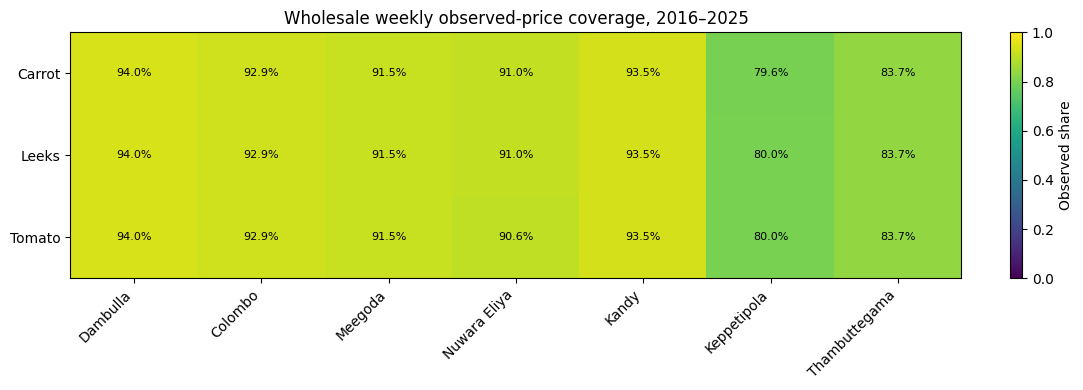


MODELLING SCOPE
Final crops: ['Carrot', 'Leeks', 'Tomato']
Score markets: ['Dambulla', 'Colombo', 'Meegoda', 'Nuwara Eliya']
Additional tree-training markets: ['Kandy', 'Keppetipola', 'Thambuttegama']
Big onion stays outside the final three because local/imported series and unit/coverage issues complicate the label.
✅ CELL 5 COMPLETE


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Cell 5 — Why these crops and these markets
# Corrected version: capitalization/spelling variants are
# canonicalised for the audit only.
# ============================================================

xlsx = DRIVE / "00_upload" / "Vegetable Prices.xlsx"
WEEKS = [f"W{i}" for i in range(1, 53)]

CROPS = [
    "CARROT", "LEEKS", "TOMATOES", "CABBAGE", "GREEN CHILLIES",
    "BIG ONIONS LOCAL", "BIG ONIONS IMPORTED",
]
MARKETS = [
    "Dambulla", "Colombo", "Meegoda", "Nuwara Eliya",
    "Kandy", "Keppetipola", "Thambuttegama",
]
SCORE_MARKETS = ["Dambulla", "Colombo", "Meegoda", "Nuwara Eliya"]
TRAIN_POOL_MARKETS = ["Kandy", "Keppetipola", "Thambuttegama"]
FINAL_CROPS = ["CARROT", "LEEKS", "TOMATOES"]

df = pd.read_excel(xlsx, sheet_name="Wholesale - W", header=3)
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df.dropna(subset=["Year"]).copy()
df["Year"] = df["Year"].astype(int)

def canonical_crop(value):
    if pd.isna(value):
        return None
    upper = " ".join(str(value).strip().upper().split())
    aliases = {
        "TOMATO": "TOMATOES",
        "TOMATOES": "TOMATOES",
        "BIG ONIONS LOCAL": "BIG ONIONS LOCAL",
        "BIG ONIONS IMPORTED": "BIG ONIONS IMPORTED",
    }
    return aliases.get(upper, upper)

def canonical_market(value):
    if pd.isna(value):
        return None
    text = str(value).strip()
    key = text.casefold()
    aliases = {
        "dambulla": "Dambulla",
        "colombo": "Colombo",
        "meegoda": "Meegoda",
        "nuwara eliya": "Nuwara Eliya",
        "n'eliya": "Nuwara Eliya",
        "kandy": "Kandy",
        "keppetipola": "Keppetipola",
        "tabuttegama": "Thambuttegama",
        "tabuththegama": "Thambuttegama",
        "thambuttegama": "Thambuttegama",
        "rathnapura": "Rathnapura",
        "ratnapura": "Rathnapura",
        "jaffna": "Jaffna",
        "jafna": "Jaffna",
        "anuradapura": "Anuradhapura",
        "anuradhapura": "Anuradhapura",
    }
    return aliases.get(key, text)

df["crop_canonical"] = df["Varaity"].apply(canonical_crop)
df["market_canonical"] = df["Location"].apply(canonical_market)

present_crops = set(df["crop_canonical"].dropna())
present_markets = set(df["market_canonical"].dropna())

print("======================================================")
print("CANONICAL COVERAGE CHECK")
print("======================================================")
print("crops missing after canonicalisation", [c for c in CROPS if c not in present_crops])
print("markets missing after canonicalisation", [m for m in MARKETS if m not in present_markets])

rows = []
for crop in CROPS:
    for market in MARKETS:
        part = df[
            df["crop_canonical"].eq(crop)
            & df["market_canonical"].eq(market)
        ].copy()
        if part.empty:
            rows.append({
                "crop": crop, "market": market, "rows": 0, "cells": 0,
                "observed_cells": 0, "missing_cells": 0,
                "observed_share": np.nan, "observed_pct": np.nan,
            })
            continue
        values = part[WEEKS].apply(pd.to_numeric, errors="coerce")
        total_cells = int(values.size)
        observed_cells = int(values.notna().to_numpy().sum())
        missing_cells = int(values.isna().to_numpy().sum())
        share = float(values.notna().to_numpy().mean())
        rows.append({
            "crop": crop,
            "market": market,
            "rows": len(part),
            "cells": total_cells,
            "observed_cells": observed_cells,
            "missing_cells": missing_cells,
            "observed_share": round(share, 4),
            "observed_pct": round(share * 100, 2),
        })

coverage = pd.DataFrame(rows)
focus = coverage[coverage["crop"].isin(FINAL_CROPS)].copy()

print("\nFINAL THREE CROPS — COVERAGE")
print(focus[["crop", "market", "rows", "observed_pct"]].to_string(index=False))

crop_summary = focus.groupby("crop", as_index=False).agg(
    mean_observed_pct=("observed_pct", "mean"),
    min_observed_pct=("observed_pct", "min"),
    max_observed_pct=("observed_pct", "max"),
)
market_summary = focus.groupby("market", as_index=False).agg(
    mean_observed_pct=("observed_pct", "mean"),
    min_observed_pct=("observed_pct", "min"),
    max_observed_pct=("observed_pct", "max"),
)

pivot = focus.pivot(index="crop", columns="market", values="observed_share").reindex(
    index=FINAL_CROPS, columns=MARKETS
)
fig, ax = plt.subplots(figsize=(11, 4))
image = ax.imshow(pivot.to_numpy(dtype=float), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(["Carrot", "Leeks", "Tomato"])
ax.set_title("Wholesale weekly observed-price coverage, 2016–2025")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        value = pivot.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value * 100:.1f}%", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, fraction=0.03, label="Observed share")
fig.tight_layout()

plot = DRIVE / "01_from_notebook1" / "plots" / "coverage_heatmap.png"
fig.savefig(plot, dpi=120, bbox_inches="tight")
plt.show()

audit_dir = DRIVE / "01_from_notebook1" / "audit"
coverage.to_csv(audit_dir / "coverage_focus.csv", index=False)
crop_summary.to_csv(audit_dir / "coverage_by_crop.csv", index=False)
market_summary.to_csv(audit_dir / "coverage_by_market.csv", index=False)

print("\nMODELLING SCOPE")
print("Final crops:", ["Carrot", "Leeks", "Tomato"])
print("Score markets:", SCORE_MARKETS)
print("Additional tree-training markets:", TRAIN_POOL_MARKETS)
print("Big onion stays outside the final three because local/imported series and unit/coverage issues complicate the label.")
print("✅ CELL 5 COMPLETE")


## Cell 6 — What W1 means — rebuilt months vs the monthly sheet

---

In [5]:
import pandas as pd

xlsx = DRIVE / "00_upload" / "Vegetable Prices.xlsx"
FOCUS = ["CARROT", "LEEKS", "TOMATOES", "CABBAGE", "GREEN CHILLIES"]
WEEKS = [f"W{i}" for i in range(1, 53)]
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]

def harti_week_start(year, week):
    """First Monday on or after 1 January, then week-1 times 7 days. Not an ISO week."""
    year = pd.Series(year).astype(int)
    week = pd.Series(week).astype(int)
    jan1 = pd.to_datetime(year.astype(str) + "-01-01")
    first_monday = jan1 + pd.to_timedelta((7 - jan1.dt.weekday) % 7, unit="D")
    return first_monday + pd.to_timedelta((week - 1) * 7, unit="D")

weekly = pd.read_excel(xlsx, sheet_name="Retail - W", header=3)
weekly = weekly.rename(columns={"Year": "year"})
weekly["year"] = pd.to_numeric(weekly["year"], errors="coerce")
weekly = weekly.dropna(subset=["year"])
weekly = weekly[weekly["Varaity"].isin(FOCUS) & weekly["year"].between(2016, 2025)]
long = weekly.melt(id_vars=["year", "Location", "Varaity"], value_vars=WEEKS, var_name="week_name", value_name="price")
long["week"] = long["week_name"].str[1:].astype(int)
long["price"] = pd.to_numeric(long["price"], errors="coerce")
long = long.dropna(subset=["price"])
long["monday"] = harti_week_start(long["year"], long["week"])
long["month"] = pd.to_datetime(long["monday"]).dt.month
rebuilt = long.groupby(["Location", "Varaity", "year", "month"], as_index=False)["price"].mean()

monthly = pd.read_excel(xlsx, sheet_name="Retail - M", header=3)
monthly = monthly.rename(columns={"YEAR": "year"})
monthly["year"] = pd.to_numeric(monthly["year"], errors="coerce")
monthly = monthly.dropna(subset=["year"])
monthly = monthly[monthly["Varaity"].isin(FOCUS) & monthly["year"].between(2016, 2025)]
mlong = monthly.melt(id_vars=["year", "Location", "Varaity"], value_vars=MONTHS, var_name="mon", value_name="published")
mlong["month"] = mlong["mon"].map({name: i + 1 for i, name in enumerate(MONTHS)})
mlong["published"] = pd.to_numeric(mlong["published"], errors="coerce")
mlong = mlong.dropna(subset=["published"])
pairs = rebuilt.merge(mlong, on=["Location", "Varaity", "year", "month"], how="inner")
ape = (pairs["price"] - pairs["published"]).abs() / pairs["published"].abs().clip(lower=1e-6)
exact = float((ape < 0.001).mean())
print("pairs", len(pairs), " earlier check 13759")
print("exact_share", round(exact, 3), " earlier check 0.963")
print("median_abs_error", float((pairs["price"] - pairs["published"]).abs().median()))
print("five mismatches")
print(pairs.loc[ape >= 0.001, ["Location", "Varaity", "year", "month", "price", "published"]].head(5).to_string(index=False))

rows = []
for year in range(2015, 2026):
    w1 = harti_week_start([year], [1]).iloc[0]
    w53 = harti_week_start([year], [53]).iloc[0]
    rows.append({
        "year": year,
        "week1_monday": str(pd.Timestamp(w1).date()),
        "week53_monday": str(pd.Timestamp(w53).date()),
        "week53_inside_year": bool(pd.Timestamp(w53).year == year),
    })
week53 = pd.DataFrame(rows)
print(week53.to_string(index=False))
print("Week 53 falls inside the year in 2018 and 2024.")

retail_raw = pd.read_excel(xlsx, sheet_name="Retail - W", header=3)
extra = [c for c in retail_raw.columns if str(c).startswith("Unnamed")]
if extra:
    extra_n = pd.to_numeric(retail_raw[extra[0]], errors="coerce")
    print("extra retail column non-null", int(extra_n.notna().sum()), "years", sorted(retail_raw.loc[extra_n.notna(), "Year"].dropna().unique().tolist()))
else:
    print("no extra unnamed retail column")

audit = DRIVE / "01_from_notebook1" / "audit"
pairs.head(20).to_csv(audit / "week_rule_check.csv", index=False)
week53.to_csv(audit / "week53_years.csv", index=False)
print("PASS week rule printed. Do not claim 100%.")

pairs 13759  earlier check 13759
exact_share 0.963  earlier check 0.963
median_abs_error 0.0
five mismatches
Location Varaity   year  month      price  published
  Ampara CABBAGE 2018.0     12 173.000000 168.800000
  Ampara CABBAGE 2023.0     11 406.666667 356.666667
  Ampara  CARROT 2018.0     12 280.000000 261.600000
  Ampara  CARROT 2023.0     11 478.333333 458.333333
  Ampara  CARROT 2024.0     12 281.666667 305.333333
 year week1_monday week53_monday  week53_inside_year
 2015   2015-01-05    2016-01-04               False
 2016   2016-01-04    2017-01-02               False
 2017   2017-01-02    2018-01-01               False
 2018   2018-01-01    2018-12-31                True
 2019   2019-01-07    2020-01-06               False
 2020   2020-01-06    2021-01-04               False
 2021   2021-01-04    2022-01-03               False
 2022   2022-01-03    2023-01-02               False
 2023   2023-01-02    2024-01-01               False
 2024   2024-01-01    2024-12-30           

## Cell 7 — Bad cells — zeros, the letter o, spikes, and the 50 kg bag

The long file already applied these rules. Cell 9 reads that file. This cell only shows the raw problems and the rule table.

---

Retail - W zero cells 0
Wholesale - W zero cells 0
Retail - M zero cells 58
  year Location          Varaity period  raw
2019.0  Colombo BIG ONIONS Local    JAN  0.0
2019.0  Colombo         DRUMSTIC    JAN  0.0
2020.0  Colombo BIG ONIONS Local    JAN  0.0
2020.0  Colombo         DRUMSTIC    JAN  0.0
2019.0  Colombo BIG ONIONS Local    FEB  0.0
2020.0  Colombo BIG ONIONS Local    FEB  0.0
2020.0  Colombo         DRUMSTIC    FEB  0.0
2018.0  Colombo BIG ONIONS Local    MAR  0.0
2018.0  Colombo         DRUMSTIC    MAR  0.0
2019.0  Colombo BIG ONIONS Local    MAR  0.0
Wholesale - M zero cells 0
wholesale weekly cells above 5000
 year       Location  Varaity period  numeric
 2023 Thissamaharama BEETROOT    W48  96468.0
 2024         Matara BRINJALS    W52 216500.0
Kandy January 2016 BIG ONIONS [3225.0]
Kandy January 2016 CARROT [253.75]
                                                    problem                        rule                                                                where

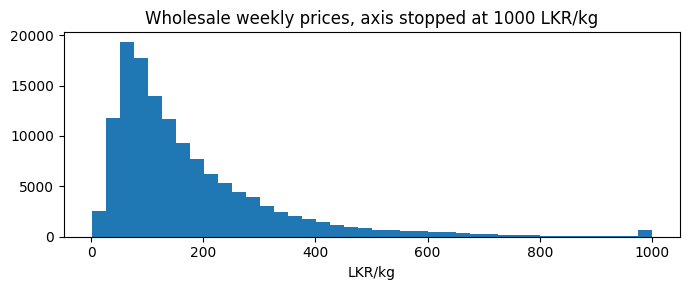

saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/audit/quality_examples.csv
PASS cleaning rules printed. This cell does not change the CSV.


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

xlsx = DRIVE / "00_upload" / "Vegetable Prices.xlsx"
WEEKS = [f"W{i}" for i in range(1, 53)]
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]

def load(sheet):
    frame = pd.read_excel(xlsx, sheet_name=sheet, header=3)
    year_col = "YEAR" if "YEAR" in frame.columns else "Year"
    frame = frame.rename(columns={year_col: "year"})
    frame["year"] = pd.to_numeric(frame["year"], errors="coerce")
    return frame.dropna(subset=["year"])

examples = []
for sheet, cols in {
    "Retail - W": WEEKS,
    "Wholesale - W": WEEKS,
    "Retail - M": MONTHS,
    "Wholesale - M": MONTHS,
}.items():
    frame = load(sheet)
    item_col = "ITEM" if "ITEM" in frame.columns else "Varaity"
    long = frame.melt(id_vars=["year", "Location", item_col], value_vars=cols, var_name="period", value_name="raw")
    numeric = pd.to_numeric(long["raw"], errors="coerce")
    zeros = long.loc[numeric.eq(0)]
    print(sheet, "zero cells", len(zeros))
    if len(zeros):
        print(zeros.head(10).to_string(index=False))
        examples.append(zeros.head(10).assign(sheet=sheet, issue="zero"))

whole = load("Wholesale - W")
long_w = whole.melt(id_vars=["year", "Location", "Varaity"], value_vars=WEEKS, var_name="period", value_name="raw")
long_w["numeric"] = pd.to_numeric(long_w["raw"], errors="coerce")
huge = long_w.loc[long_w["numeric"] > 5000, ["year", "Location", "Varaity", "period", "numeric"]]
print("wholesale weekly cells above 5000")
print(huge.to_string(index=False))
examples.append(huge.assign(sheet="Wholesale - W", issue="above_5000"))

whole_m = load("Wholesale - M")
kandy = whole_m[whole_m["Location"].astype(str).str.lower().eq("kandy") & whole_m["year"].eq(2016)]
item_col = "ITEM" if "ITEM" in kandy.columns else "Varaity"
onion = kandy[kandy[item_col].astype(str).str.upper().eq("BIG ONIONS")]
carrot = kandy[kandy[item_col].astype(str).str.upper().eq("CARROT")]
print("Kandy January 2016 BIG ONIONS", onion["JAN"].tolist())
print("Kandy January 2016 CARROT", carrot["JAN"].tolist())

rules = pd.DataFrame([
    ("missing price", "leave it missing", "never fill with 0 and never interpolate 2020-2021"),
    ("zero or negative", "treat as missing", "flag name in the long file: zero_as_missing"),
    ("text such as 'o'", "drop from the cleaned price", "flag name: non_numeric_dropped; price_raw keeps the text"),
    ("onion wholesale about 25x to 80x national retail", "divide by 50", "only big_onion, big_onion_local, big_onion_imported; flag per_50kg_bag_converted"),
    ("onion wholesale about 1/80 to 1/25 of national retail", "multiply by 50", "flag divided_by_50_corrected"),
    ("cleaned value above 25x or below 1/25 of national retail", "blank the cleaned price", "flag extreme_outlier_dropped; price_raw is kept"),
    ("log price more than log(3) from the centred 5-period median", "keep the value and flag it", "flag spike_suspect_kept"),
    ("carrot, leeks, tomato", "already LKR/kg", "do not divide those three crops by 50"),
], columns=["problem", "rule", "where it shows up"])
print(rules.to_string(index=False))

values = pd.to_numeric(whole[WEEKS].stack(), errors="coerce").dropna()
print("wholesale weekly numeric cells above 1000", int((values > 1000).sum()))
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(values.clip(upper=1000), bins=40)
ax.set_title("Wholesale weekly prices, axis stopped at 1000 LKR/kg")
ax.set_xlabel("LKR/kg")
fig.tight_layout()
plot = DRIVE / "01_from_notebook1" / "plots" / "wholesale_weekly_price_hist.png"
fig.savefig(plot, dpi=120)
plt.show()

out = DRIVE / "01_from_notebook1" / "audit" / "quality_examples.csv"
pd.concat(examples, ignore_index=True).to_csv(out, index=False)
rules.to_csv(DRIVE / "01_from_notebook1" / "audit" / "cleaning_rules.csv", index=False)
print("saved", out)
print("PASS cleaning rules printed. This cell does not change the CSV.")

## Cell 8 — Decisions locked before modeling

---

In [7]:
import pandas as pd

decisions = pd.DataFrame([
    ("where it runs", "Colab notebook cells. The project package is not imported."),
    ("label", "wholesale weekly LKR/kg from Wholesale - W, column price_lkr_per_kg"),
    ("crops", "carrot, leeks, tomato"),
    ("score markets", "Dambulla, Colombo, Meegoda, Nuwara Eliya"),
    ("train pool", "Kandy, Keppetipola, Thambuttegama"),
    ("horizons", "1, 2, 4, 8, 12 weeks"),
    ("split", "forecast Mondays through 2022-12-31 / 2023 / 2024-2025. No shuffle."),
    ("shock", "2024-01-01 through 2024-03-31, reported separately"),
    ("tree target", "log(target_price / last_observed_price), then last_price * exp(pred)"),
    ("SARIMAX", "(1, 1, 1) x (1, 0, 0, 52). statsforecast is not installed."),
    ("quantiles", "0.05, 0.50, 0.95. Seed 42. Fixed defaults, not Optuna."),
    ("set A", "price lags and season"),
    ("set B", "A + origin weather + diesel + USD/LKR + inflation + finished-season extent"),
    ("Experiment C", "not run; cultivation_progress_ratio stays all null"),
    ("weather", "HARTI week from supply districts in weather_weekly_open_meteo.csv"),
    ("monthly sheets", "calendar check only"),
    ("retail", "margin chart only, not the score"),
    ("local big onion", "excluded, far too incomplete"),
    ("2020-2021", "left missing"),
], columns=["decision", "reason"])
print(decisions.to_string(index=False))
path = DRIVE / "01_from_notebook1" / "audit" / "decisions.csv"
decisions.to_csv(path, index=False)
print("saved", path)

       decision                                                                     reason
  where it runs                 Colab notebook cells. The project package is not imported.
          label        wholesale weekly LKR/kg from Wholesale - W, column price_lkr_per_kg
          crops                                                      carrot, leeks, tomato
  score markets                                   Dambulla, Colombo, Meegoda, Nuwara Eliya
     train pool                                          Kandy, Keppetipola, Thambuttegama
       horizons                                                       1, 2, 4, 8, 12 weeks
          split        forecast Mondays through 2022-12-31 / 2023 / 2024-2025. No shuffle.
          shock                         2024-01-01 through 2024-03-31, reported separately
    tree target       log(target_price / last_observed_price), then last_price * exp(pred)
        SARIMAX                 (1, 1, 1) x (1, 0, 0, 52). statsforecast is not installed.

## Cell 9 — Long price table — same workbook, one row per week

The location column in the long file is already the canonical spelling, so `kandy` and `Kandy` are both `Kandy` there. The 9,770 figure is the earlier scoped extract. Print your count beside it.

---

In [8]:
import pandas as pd

path = DRIVE / "00_upload" / "harti_prices_weekly_long.csv"
weekly = pd.read_csv(path, low_memory=False)
print("shape", weekly.shape)
print("columns", weekly.columns.tolist())
print("year", int(weekly["year"].min()), int(weekly["year"].max()))
print("period_start", weekly["period_start"].min(), weekly["period_start"].max())
print(weekly["price_type"].value_counts().to_string())
print(weekly["quality_flag"].value_counts().to_string())
print("Earlier laptop file: 472213 rows; retail 338556; wholesale 133657; period_start 2015-01-05 to 2025-12-29.")
print("Earlier weekly flags: ok 471807; divided_by_50_corrected 305; spike_suspect_kept 89; extreme_outlier_dropped 11; non_numeric_dropped 1.")

xlsx = DRIVE / "00_upload" / "Vegetable Prices.xlsx"
excel = pd.read_excel(xlsx, sheet_name="Wholesale - W", header=3)

def show_example(location, excel_item, commodity, year, weeks):
    part = excel[
        excel["Location"].astype(str).eq(location)
        & excel["Varaity"].astype(str).str.upper().eq(excel_item)
        & pd.to_numeric(excel["Year"], errors="coerce").eq(year)
    ]
    csv_part = weekly[
        weekly["location"].eq(location)
        & weekly["commodity"].eq(commodity)
        & weekly["price_type"].eq("wholesale")
        & weekly["year"].eq(year)
        & weekly["period"].isin(weeks)
    ][["period", "price_raw", "price_lkr_per_kg", "quality_flag"]]
    rows = []
    for week in weeks:
        excel_value = part[f"W{week}"].iloc[0] if len(part) else None
        match = csv_part[csv_part["period"].eq(week)]
        rows.append({
            "location": location,
            "commodity": commodity,
            "year": year,
            "week": week,
            "excel": excel_value,
            "price_raw": None if match.empty else match["price_raw"].iloc[0],
            "price_lkr_per_kg": None if match.empty else match["price_lkr_per_kg"].iloc[0],
            "quality_flag": None if match.empty else match["quality_flag"].iloc[0],
        })
    print(pd.DataFrame(rows).to_string(index=False))

print("example 1: Dambulla carrot 2016 W1-W4")
show_example("Dambulla", "CARROT", "carrot", 2016, [1, 2, 3, 4])
print("example 2: Nuwara Eliya leeks 2016 W1")
show_example("Nuwara Eliya", "LEEKS", "leeks", 2016, [1])
print("example 3: Colombo tomato 2016 W1")
show_example("Colombo", "TOMATOES", "tomato", 2016, [1])

markets = ["Dambulla", "Colombo", "Meegoda", "Nuwara Eliya", "Kandy", "Keppetipola", "Thambuttegama"]
scoped = weekly[
    weekly["price_type"].eq("wholesale")
    & weekly["frequency"].eq("weekly")
    & weekly["commodity"].isin(["carrot", "leeks", "tomato"])
    & weekly["location"].isin(markets)
]
print("scoped wholesale rows", len(scoped), " earlier interim file about 9770")
print("locations", sorted(scoped["location"].unique()))
out = DRIVE / "01_from_notebook1" / "panel" / "scope_weekly.csv"
scoped.to_csv(out, index=False)
print("saved", out)
print("PASS three examples printed. The next cell builds the modelling panel from this CSV.")

shape (472213, 21)
columns ['source', 'sheet', 'price_type', 'frequency', 'year', 'period', 'period_label', 'period_start', 'period_end', 'location_raw', 'location', 'district', 'commodity_raw', 'commodity', 'price_raw', 'price_lkr_per_kg', 'unit', 'quality_flag', 'is_outlier_flag', 'ref_retail_median', 'ratio_to_national_retail']
year 2015 2025
period_start 2015-01-05 2025-12-29
price_type
retail       338556
wholesale    133657
quality_flag
ok                         471807
divided_by_50_corrected       305
spike_suspect_kept             89
extreme_outlier_dropped        11
non_numeric_dropped             1
Earlier laptop file: 472213 rows; retail 338556; wholesale 133657; period_start 2015-01-05 to 2025-12-29.
Earlier weekly flags: ok 471807; divided_by_50_corrected 305; spike_suspect_kept 89; extreme_outlier_dropped 11; non_numeric_dropped 1.
example 1: Dambulla carrot 2016 W1-W4
location commodity  year  week  excel price_raw  price_lkr_per_kg quality_flag
Dambulla    carrot  2016

## Cell 10 — What the wholesale price actually does

---

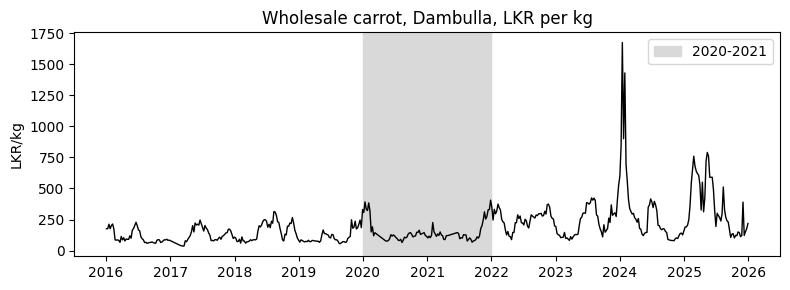

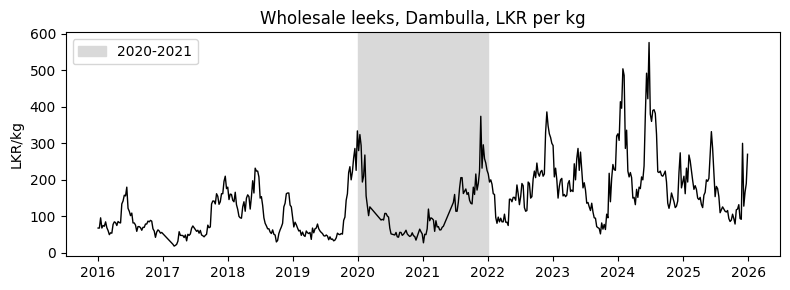

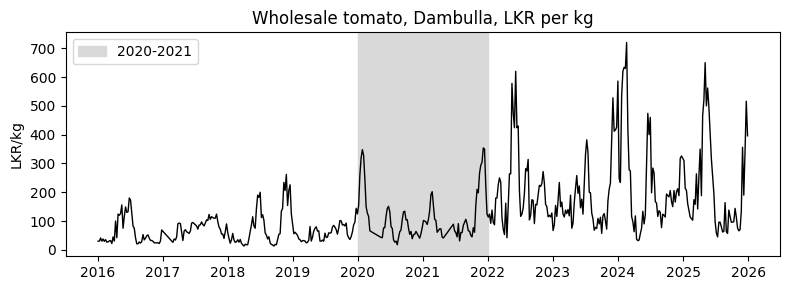

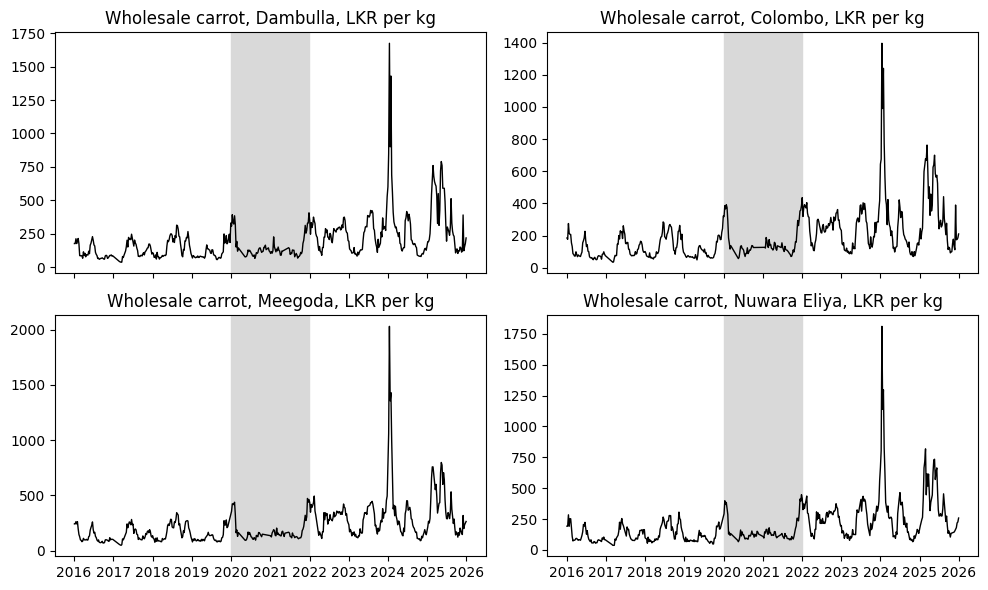

Dambulla carrot weeks with wholesale above retail 0 of 480


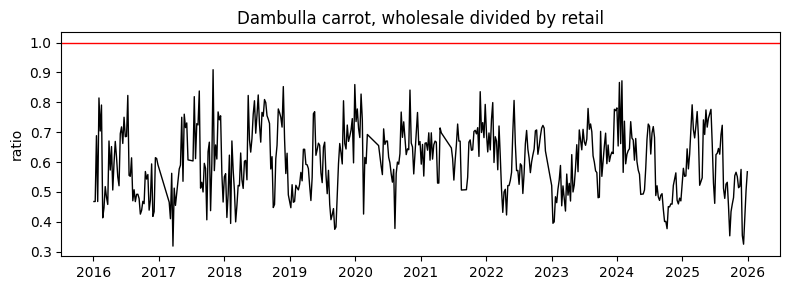

  crop       market  n_observed       min     median         max
carrot     Dambulla         489 36.000000 146.000000 1675.000000
carrot      Colombo         483 34.166667 149.090909 1395.833333
carrot      Meegoda         476 48.000000 171.000000 2030.000000
carrot Nuwara Eliya         473 37.000000 146.000000 1810.000000
 leeks     Dambulla         489 18.600000 128.000000  576.000000
 leeks      Colombo         483 19.583333 125.833333  507.000000
 leeks      Meegoda         476 32.000000 147.750000  592.000000
 leeks Nuwara Eliya         473 16.400000 117.000000  564.000000
tomato     Dambulla         489 13.000000  98.000000  720.000000
tomato      Colombo         483 20.000000 120.000000  772.000000
tomato      Meegoda         476 24.000000 126.333333  798.000000
tomato Nuwara Eliya         471 15.400000 108.000000  784.000000
PASS price charts. The grey band is missingness, not a filled price.


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

weekly = pd.read_csv(DRIVE / "00_upload" / "harti_prices_weekly_long.csv", low_memory=False)
weekly["period_start"] = pd.to_datetime(weekly["period_start"])
score = ["Dambulla", "Colombo", "Meegoda", "Nuwara Eliya"]
panel = weekly[
    weekly["price_type"].eq("wholesale")
    & weekly["commodity"].isin(["carrot", "leeks", "tomato"])
    & weekly["location"].isin(score)
].copy()
summaries = []
for crop in ["carrot", "leeks", "tomato"]:
    for market in score:
        part = panel[panel["commodity"].eq(crop) & panel["location"].eq(market)].sort_values("period_start")
        observed = part["price_lkr_per_kg"].notna()
        summaries.append({
            "crop": crop,
            "market": market,
            "n_observed": int(observed.sum()),
            "min": float(part.loc[observed, "price_lkr_per_kg"].min()) if observed.any() else None,
            "median": float(part.loc[observed, "price_lkr_per_kg"].median()) if observed.any() else None,
            "max": float(part.loc[observed, "price_lkr_per_kg"].max()) if observed.any() else None,
        })
        if market == "Dambulla":
            fig, ax = plt.subplots(figsize=(8, 3))
            ax.plot(part["period_start"], part["price_lkr_per_kg"], color="black", lw=1)
            ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="0.85", label="2020-2021")
            ax.set_title(f"Wholesale {crop}, {market}, LKR per kg")
            ax.set_ylabel("LKR/kg")
            ax.legend()
            fig.tight_layout()
            fig.savefig(DRIVE / "01_from_notebook1" / "plots" / f"price_{crop}_{market.replace(' ', '_').lower()}.png", dpi=120)
            plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
carrot = panel[panel["commodity"].eq("carrot")]
for ax, market in zip(axes.ravel(), score):
    part = carrot[carrot["location"].eq(market)].sort_values("period_start")
    ax.plot(part["period_start"], part["price_lkr_per_kg"], color="black", lw=1)
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="0.85")
    ax.set_title(f"Wholesale carrot, {market}, LKR per kg")
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "price_carrot_four_markets.png", dpi=120)
plt.show()

both = weekly[
    weekly["commodity"].eq("carrot")
    & weekly["location"].eq("Dambulla")
    & weekly["price_lkr_per_kg"].notna()
]
retail = both[both["price_type"].eq("retail")][["period_start", "price_lkr_per_kg"]].rename(columns={"price_lkr_per_kg": "retail"})
wholesale = both[both["price_type"].eq("wholesale")][["period_start", "price_lkr_per_kg"]].rename(columns={"price_lkr_per_kg": "wholesale"})
ratio = wholesale.merge(retail, on="period_start")
ratio["ratio"] = ratio["wholesale"] / ratio["retail"]
print("Dambulla carrot weeks with wholesale above retail", int((ratio["ratio"] > 1).sum()), "of", len(ratio))
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ratio["period_start"], ratio["ratio"], color="black", lw=1)
ax.axhline(1, color="red", lw=1)
ax.set_title("Dambulla carrot, wholesale divided by retail")
ax.set_ylabel("ratio")
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "carrot_dambulla_wholesale_over_retail.png", dpi=120)
plt.show()

summary = pd.DataFrame(summaries)
print(summary.to_string(index=False))
summary.to_csv(DRIVE / "01_from_notebook1" / "audit" / "series_summary.csv", index=False)
print("PASS price charts. The grey band is missingness, not a filled price.")

## Cell 11 — Attach origin weather and keep the market as the market

This cell pastes the origin table and the Yala/Maha windows as Python dictionaries. It does not load YAML and it does not import `htfe`. Dambulla is the market. For carrot, Nuwara Eliya and Badulla are the supply districts. Weather points for that row include Welimada and Bandarawela because they sit inside Badulla. They are not extra supply rows, and they are not Dambulla town rain.



`cultivation_intensity` is lagged extent divided by the median of the same season in 2015–2019. Experiment B’s forbidden list includes that column. It is saved on the panel and it is not a model input.

---

In [10]:
import bisect
import numpy as np
import pandas as pd

# Copied from src/htfe/data/maps/origin_map.yaml. assumption True means a research judgement.
ORIGIN_MAP = {
    "carrot": {
        "Nuwara Eliya": {"weather": ["nuwara_eliya"], "supply_districts": ["Nuwara Eliya"], "assumption": False, "note": "Producer market in the main carrot district."},
        "Dambulla": {"weather": ["nuwara_eliya", "badulla", "welimada", "bandarawela"], "supply_districts": ["Nuwara Eliya", "Badulla"], "assumption": True, "note": "Upcountry supply into the Dambulla wholesale hub."},
        "Colombo": {"weather": ["nuwara_eliya", "badulla", "welimada", "bandarawela"], "supply_districts": ["Nuwara Eliya", "Badulla"], "assumption": True, "note": "Consumer market fed by highland carrot."},
        "Meegoda": {"weather": ["nuwara_eliya", "badulla", "welimada", "bandarawela"], "supply_districts": ["Nuwara Eliya", "Badulla"], "assumption": True, "note": "Same highland shed as Colombo."},
        "Kandy": {"weather": ["kandy", "nuwara_eliya"], "supply_districts": ["Kandy", "Nuwara Eliya"], "assumption": True, "note": "Train-pool market. Kandy has its own DCS carrot extent."},
        "Keppetipola": {"weather": ["keppetipola", "badulla", "welimada"], "supply_districts": ["Badulla"], "assumption": True, "note": "Train-pool producer market in Badulla district."},
        "Thambuttegama": {"weather": ["dambulla"], "supply_districts": ["Anuradhapura"], "assumption": True, "note": "Train-pool. Nearest fetched weather point is Dambulla; supply is Anuradhapura."},
    },
    "leeks": {
        "Nuwara Eliya": {"weather": ["nuwara_eliya"], "supply_districts": ["Nuwara Eliya"], "assumption": False, "note": "Producer market."},
        "Dambulla": {"weather": ["nuwara_eliya", "badulla", "welimada", "bandarawela"], "supply_districts": ["Nuwara Eliya", "Badulla"], "assumption": True, "note": "Upcountry leeks into Dambulla."},
        "Colombo": {"weather": ["nuwara_eliya", "badulla"], "supply_districts": ["Nuwara Eliya", "Badulla"], "assumption": True, "note": "Consumer market."},
        "Meegoda": {"weather": ["nuwara_eliya", "badulla"], "supply_districts": ["Nuwara Eliya", "Badulla"], "assumption": True, "note": "Consumer market."},
        "Kandy": {"weather": ["kandy", "nuwara_eliya"], "supply_districts": ["Nuwara Eliya", "Kandy"], "assumption": True, "note": "Train-pool."},
        "Keppetipola": {"weather": ["keppetipola", "badulla"], "supply_districts": ["Badulla", "Nuwara Eliya"], "assumption": True, "note": "Train-pool."},
        "Thambuttegama": {"weather": ["dambulla"], "supply_districts": ["Nuwara Eliya"], "assumption": True, "note": "Train-pool. Leeks are not an Anuradhapura crop; origin stays upcountry."},
    },
    "tomato": {
        "Nuwara Eliya": {"weather": ["nuwara_eliya", "matale"], "supply_districts": ["Nuwara Eliya", "Matale"], "assumption": True, "note": "DCS shows Matale tomato as well as Nuwara Eliya."},
        "Dambulla": {"weather": ["matale", "nuwara_eliya", "badulla"], "supply_districts": ["Matale", "Nuwara Eliya", "Badulla"], "assumption": True, "note": "Dambulla is in Matale district."},
        "Colombo": {"weather": ["matale", "badulla", "nuwara_eliya"], "supply_districts": ["Matale", "Badulla", "Nuwara Eliya"], "assumption": True, "note": "Wider tomato shed than carrot."},
        "Meegoda": {"weather": ["matale", "badulla", "nuwara_eliya"], "supply_districts": ["Matale", "Badulla", "Nuwara Eliya"], "assumption": True, "note": "Wider tomato shed than carrot."},
        "Kandy": {"weather": ["kandy", "matale"], "supply_districts": ["Kandy", "Matale"], "assumption": True, "note": "Train-pool."},
        "Keppetipola": {"weather": ["keppetipola", "badulla"], "supply_districts": ["Badulla"], "assumption": True, "note": "Train-pool."},
        "Thambuttegama": {"weather": ["dambulla", "matale"], "supply_districts": ["Anuradhapura", "Matale"], "assumption": True, "note": "Train-pool. Tomato is grown more widely than carrot."},
    },
}

# Copied from src/htfe/data/maps/crop_calendar.yaml. Same window on each crop.
# Yala of year S is HARTI weeks 14-39 of S, finished only after week 39.
# Maha of year S is weeks 40-52/53 of S plus weeks 1-13 of S+1, finished only after week 13 of S+1.
SEASON_WINDOWS = {
    "Yala": {"start_week": 14, "end_week": 39, "finished_after_week": 39},
    "Maha": {"start_week": 40, "continues_through_week": 13, "finished_after_week": 13, "spans_into_next_year": True},
}
PLANTING_WINDOWS = {
    crop: {
        "Yala": {"planting_start_week": 14, "planting_end_week": 22},
        "Maha": {"planting_start_week": 40, "planting_end_week": 48},
    }
    for crop in ("carrot", "leeks", "tomato")
}
PROFILES = {
    "early": {"midpoint": 0.40, "steepness": 8},
    "typical": {"midpoint": 0.50, "steepness": 8},
    "late": {"midpoint": 0.60, "steepness": 8},
}
print("season windows", SEASON_WINDOWS)
print("planting windows", PLANTING_WINDOWS)
print("logistic profiles are in the calendar file and are not features", PROFILES)
print("Experiment C is not trained. These profiles do not fill cultivation_progress_ratio.")

# Copied from src/htfe/data/build/join_weather.py. Several points sit in one district.
WEATHER_DISTRICT = {
    "nuwara_eliya": "Nuwara Eliya",
    "badulla": "Badulla",
    "welimada": "Badulla",
    "bandarawela": "Badulla",
    "matale": "Matale",
    "kandy": "Kandy",
    "dambulla": "Matale",
    "keppetipola": "Badulla",
}
WEATHER_KEEP = [
    "precip_mm", "tmean_c", "tmax_c", "tmin_c", "et0_mm", "shortwave_mj_m2",
    "rh_mean_pct", "soil_moist_0_7cm_m3m3", "wet_days_1mm", "heavy_rain_days_50mm",
]

CARROT_DAMBULLA = ORIGIN_MAP["carrot"]["Dambulla"]
print("Dambulla carrot supply_districts", CARROT_DAMBULLA["supply_districts"])
print("Dambulla carrot weather points", CARROT_DAMBULLA["weather"])
print("assumption", CARROT_DAMBULLA["assumption"], CARROT_DAMBULLA["note"])
assert CARROT_DAMBULLA["supply_districts"] == ["Nuwara Eliya", "Badulla"]
assert "dambulla" not in CARROT_DAMBULLA["weather"]
for market in ("Colombo", "Meegoda"):
    points = ORIGIN_MAP["carrot"][market]["weather"]
    assert market.lower() not in points
print("Dambulla is the market. Nuwara Eliya and Badulla are the carrot supply districts.")
print("PASS origin weather is not the market town")

def last_finished_season(year, week):
    best = None
    for season_year in range(int(year) - 3, int(year) + 1):
        if year > season_year or (year == season_year and week > 39):
            key = (season_year, 39, "Yala", season_year, f"Yala_{season_year}")
            if best is None or key[:2] > best[:2]:
                best = key
        end_year = season_year + 1
        if year > end_year or (year == end_year and week > 13):
            key = (end_year, 13, "Maha", season_year, f"Maha_{season_year}")
            if best is None or key[:2] > best[:2]:
                best = key
    if best is None:
        return "Maha", int(year) - 2, f"Maha_{int(year) - 2}"
    return best[2], best[3], best[4]

def season_of_week(week):
    return "Yala" if 14 <= int(week) <= 39 else "Maha"

def current_season(year, week):
    year, week = int(year), int(week)
    if 14 <= week <= 39:
        return "Yala", year
    if week <= 13:
        return "Maha", year - 1
    return "Maha", year

def season_is_finished(season, season_year, year, week):
    end = (int(season_year), 39) if season == "Yala" else (int(season_year) + 1, 13)
    return (int(year), int(week)) > end

def season_immediately_before(season, season_year):
    if season == "Yala":
        return "Maha", int(season_year) - 1
    return "Yala", int(season_year)

def attach_finished_extent_features(panel, seasonal, origin_map):
    """Extent of seasons that have already finished. The open season is not an input."""
    out = panel.copy()
    lookup = {}
    known = seasonal.dropna(subset=["extent_ha"])
    for crop, district, year, season, extent in zip(known["crop"], known["district"], known["year"], known["season"], known["extent_ha"]):
        lookup[(str(crop).strip().lower(), str(district).strip().casefold(), int(year), str(season))] = float(extent)

    def sum_districts(crop, districts, year, season):
        total, seen = 0.0, False
        for district in districts:
            value = lookup.get((str(crop).strip().lower(), str(district).strip().casefold(), int(year), season))
            if value is None:
                continue
            total += value
            seen = True
        return total if seen else None

    year_min = int(seasonal["year"].min()) - 1
    year_max = int(seasonal["year"].max())
    timeline = []
    for season_year in range(year_min, year_max + 1):
        timeline.append(("Yala", season_year, season_year, 39))
        timeline.append(("Maha", season_year, season_year + 1, 13))
    timeline.sort(key=lambda item: (item[2], item[3]))
    ends = [(item[2], item[3]) for item in timeline]
    position = {(item[0], item[1]): index for index, item in enumerate(timeline)}
    cache = {}

    def series_for(crop, market):
        key = (str(crop), str(market))
        if key in cache:
            return cache[key]
        districts = (origin_map.get(crop) or {}).get(market, {}).get("supply_districts") or []
        values = [sum_districts(crop, districts, season_year, season) for season, season_year, _ey, _ew in timeline]
        cache[key] = values
        return values

    previous, same_year, historical, change = [], [], [], []
    names, years, labels = [], [], []
    for crop, market, year, week in zip(out["crop"], out["market"], out["year"], out["week"]):
        year, week = int(year), int(week)
        finished_name, finished_year, finished_label = last_finished_season(year, week)
        names.append(finished_name)
        years.append(finished_year)
        labels.append(finished_label)
        values = series_for(crop, market)
        index = bisect.bisect_left(ends, (year, week)) - 1
        if index < 0 or timeline[index][0] != finished_name or timeline[index][1] != finished_year:
            raise AssertionError(f"lagged season mismatch at {year} W{week}")
        latest = values[index]
        prior = values[index - 1] if index else None
        previous.append(np.nan if latest is None else float(latest))
        change.append(np.nan if latest is None or prior is None else float(latest) - float(prior))
        finished_values = [value for value in values[: index + 1] if value is not None]
        historical.append(sum(finished_values) / len(finished_values) if finished_values else np.nan)
        current_name, current_year = current_season(year, week)
        prior_same = (current_name, current_year - 1)
        same_value = None
        if season_is_finished(prior_same[0], prior_same[1], year, week):
            slot = position.get(prior_same)
            if slot is not None:
                same_value = values[slot]
        same_year.append(np.nan if same_value is None else float(same_value))
    out["supply_season_name"] = names
    out["supply_season_year"] = years
    out["supply_season_label"] = labels
    out["season"] = [season_of_week(week) for week in out["week"]]
    out["previous_season_extent"] = previous
    out["same_season_previous_year_extent"] = same_year
    out["historical_mean_season_extent"] = historical
    out["extent_change_vs_previous_season"] = change
    out["supply_extent_ha_lag1_season"] = previous
    return out

def weather_weights(points, crop, season, year, extent_lookup):
    if not points:
        return []
    counts = {}
    for point in points:
        district = WEATHER_DISTRICT.get(point, point)
        counts[district] = counts.get(district, 0) + 1
    raw = []
    for point in points:
        district = WEATHER_DISTRICT.get(point, point)
        value = extent_lookup.get((str(crop).lower(), district.casefold(), int(year), season))
        share = (value / counts[district]) if value is not None and counts[district] else np.nan
        raw.append((point, share))
    if not any(np.isfinite(weight) and weight > 0 for _, weight in raw):
        return [(point, 1.0) for point, _ in raw]
    return [(point, weight if np.isfinite(weight) and weight > 0 else 0.0) for point, weight in raw]

def harti_monday(year, week):
    jan1 = pd.Timestamp(year=int(year), month=1, day=1)
    first = jan1 + pd.Timedelta(days=(7 - jan1.weekday()) % 7)
    return first + pd.Timedelta(days=(int(week) - 1) * 7)

CROPS = ["carrot", "leeks", "tomato"]
ALL_MARKETS = ["Dambulla", "Colombo", "Meegoda", "Nuwara Eliya", "Kandy", "Keppetipola", "Thambuttegama"]
calendar = []
for year in range(2016, 2026):
    for week in range(1, 54):
        start = harti_monday(year, week)
        if start.year != year:
            continue
        calendar.append({"year": year, "week": week, "week_start": start})
weeks = pd.DataFrame(calendar)
series = pd.MultiIndex.from_product([CROPS, ALL_MARKETS], names=["crop", "market"]).to_frame(index=False)
grid = series.merge(weeks, how="cross")

raw = pd.read_csv(DRIVE / "00_upload" / "harti_prices_weekly_long.csv", low_memory=False)
scoped = raw[
    raw["price_type"].eq("wholesale")
    & raw["frequency"].eq("weekly")
    & raw["commodity"].isin(CROPS)
    & raw["location"].isin(ALL_MARKETS)
].copy()
scoped["week_start"] = pd.to_datetime(scoped["period_start"])
scoped["price"] = pd.to_numeric(scoped["price_lkr_per_kg"], errors="coerce")
scoped.loc[scoped["price"] <= 0, "price"] = np.nan
scoped = scoped.rename(columns={"commodity": "crop", "location": "market", "period": "week_num"})
scoped = scoped.sort_values(["crop", "market", "week_start"]).drop_duplicates(["crop", "market", "week_start"], keep="last")
print("scoped observed-file rows", len(scoped), " earlier interim about 9770")

panel = grid.merge(
    scoped[["crop", "market", "week_start", "price", "quality_flag", "is_outlier_flag"]],
    on=["crop", "market", "week_start"],
    how="left",
)
panel["price_type"] = "wholesale"
panel["quality_flag"] = panel["quality_flag"].fillna("missing")
panel["is_outlier_flag"] = panel["is_outlier_flag"].fillna(False).astype(bool)
panel["week_start"] = pd.to_datetime(panel["week_start"])
seasonal = pd.read_csv(DRIVE / "00_upload" / "dcs_highland_seasonal.csv")
panel = attach_finished_extent_features(panel, seasonal, ORIGIN_MAP)

extent_lookup = {}
known = seasonal.dropna(subset=["extent_ha"])
for crop, district, year, season, extent in zip(known["crop"], known["district"], known["year"], known["season"], known["extent_ha"]):
    extent_lookup[(str(crop).strip().lower(), str(district).strip().casefold(), int(year), str(season))] = float(extent)

weather = pd.read_csv(DRIVE / "00_upload" / "weather_weekly_open_meteo.csv")
weather["period_start"] = pd.to_datetime(weather["period_start"])
weather = weather.drop_duplicates(["location", "period_start"], keep="last")
weather_index = {(row.location, pd.Timestamp(row.period_start)): row for row in weather.itertuples(index=False)}
value_columns = {f"weather_{column}": [] for column in WEATHER_KEEP}
n_origins, complete_min = [], []
for crop, market, week_start, season_name, season_year in zip(
    panel["crop"], panel["market"], panel["week_start"], panel["supply_season_name"], panel["supply_season_year"]
):
    points = ORIGIN_MAP[crop][market]["weather"]
    weights = weather_weights(points, crop, season_name, int(season_year), extent_lookup)
    totals = {column: 0.0 for column in WEATHER_KEEP}
    used_weight = {column: 0.0 for column in WEATHER_KEEP}
    completes, used = [], 0
    for point, weight in weights:
        row = weather_index.get((point, pd.Timestamp(week_start)))
        if row is None:
            continue
        used += 1
        if pd.notna(row.complete):
            completes.append(float(bool(row.complete)))
        for column in WEATHER_KEEP:
            value = getattr(row, column)
            if pd.notna(value):
                totals[column] += float(value) * weight
                used_weight[column] += weight
    n_origins.append(used)
    complete_min.append(min(completes) if completes else np.nan)
    for column in WEATHER_KEEP:
        if used_weight[column] > 0:
            value_columns[f"weather_{column}"].append(totals[column] / used_weight[column])
        else:
            value_columns[f"weather_{column}"].append(np.nan)
for name, values in value_columns.items():
    panel[name] = values
panel["weather_n_origins"] = n_origins
panel["weather_complete_min"] = complete_min

def apply_missingness(frame):
    """Short holes of 1-2 weeks can fill price_feature only. Covid and 2017 collection gaps stay blank. price itself is never filled."""
    pieces = []
    for (_, _), group in frame.groupby(["crop", "market"], sort=False):
        group = group.sort_values("week_start").copy()
        observed = group["price"].notna().to_numpy()
        feature = group["price"].to_numpy(dtype=float).copy()
        run_length = np.zeros(len(group), dtype=int)
        disruption = np.array(["none"] * len(group), dtype=object)
        index = 0
        while index < len(group):
            if observed[index]:
                index += 1
                continue
            end = index
            while end < len(group) and not observed[end]:
                end += 1
            length = end - index
            gap = group.iloc[index:end]
            starts = pd.to_datetime(gap["week_start"])
            flag = None
            if length >= 3 and ((starts.dt.year == 2017) & (gap["week"].to_numpy() <= 12)).any():
                flag = "collection_gap_2017"
            elif length >= 3 and starts.dt.year.isin([2020, 2021]).any():
                flag = "covid"
            if flag:
                disruption[index:end] = flag
            for pos in range(index, end):
                run_length[pos] = pos - index + 1
            if flag is None and length <= 2:
                left = feature[index - 1] if index > 0 and np.isfinite(feature[index - 1]) else np.nan
                right = feature[end] if end < len(group) and np.isfinite(feature[end]) else np.nan
                for step, pos in enumerate(range(index, end), start=1):
                    if np.isfinite(left) and np.isfinite(right):
                        feature[pos] = left + (right - left) * step / (length + 1)
                    elif np.isfinite(left):
                        feature[pos] = left
                    elif np.isfinite(right):
                        feature[pos] = right
            index = end
        group["missing_run_length"] = run_length
        group["disruption_flag"] = disruption
        group["price_feature"] = feature
        group["is_observed"] = group["price"].notna()
        group["is_imputed"] = (~group["is_observed"]) & np.isfinite(feature)
        pieces.append(group)
    return pd.concat(pieces, ignore_index=True)

panel = apply_missingness(panel)
base = panel.loc[
    panel["supply_season_year"].between(2015, 2019),
    ["crop", "market", "supply_season_name", "supply_season_year", "supply_extent_ha_lag1_season"],
].drop_duplicates(["crop", "market", "supply_season_name", "supply_season_year"])
benchmark = base.groupby(["crop", "market", "supply_season_name"])["supply_extent_ha_lag1_season"].median().rename("benchmark_ha")
panel = panel.merge(benchmark.reset_index(), on=["crop", "market", "supply_season_name"], how="left")
panel["cultivation_intensity"] = panel["supply_extent_ha_lag1_season"] / panel["benchmark_ha"].replace(0, np.nan)
panel["commitment_source"] = "historical_dcs_proxy"
panel = panel.drop(columns=["benchmark_ha"])
panel = panel.sort_values(["crop", "market", "week_start"]).reset_index(drop=True)

if not bool(panel["week_start"].dt.dayofweek.eq(0).all()):
    raise AssertionError("week_start must be Monday")
covid = panel["disruption_flag"].eq("covid")
if bool(panel.loc[covid, "is_imputed"].any()):
    raise AssertionError("a 2020-2021 gap was interpolated")
example = panel[panel["crop"].eq("carrot") & panel["market"].eq("Dambulla")].head(3)
print(example[["crop", "market", "week_start", "price", "weather_precip_mm", "previous_season_extent"]].to_string(index=False))
print("rows", len(panel), "crops", sorted(panel["crop"].unique()), "markets", sorted(panel["market"].unique()))
print("week_start", panel["week_start"].min().date(), panel["week_start"].max().date())
print("price non-null share", round(float(panel["price"].notna().mean()), 3))
print("covid rows", int(covid.sum()), "imputed short gaps", int(panel["is_imputed"].sum()))
print("PASS 2020-2021 gaps were not interpolated. price_feature fills only a 1-2 week hole that is not a disruption.")
print("cultivation_intensity is on the panel for description. It is not a feature in A or B.")

toy_seasonal = pd.DataFrame([
    {"crop": "carrot", "district": "Nuwara Eliya", "year": 2018, "season": "Yala", "extent_ha": 100},
    {"crop": "carrot", "district": "Badulla", "year": 2018, "season": "Yala", "extent_ha": 50},
    {"crop": "carrot", "district": "Nuwara Eliya", "year": 2018, "season": "Maha", "extent_ha": 80},
    {"crop": "carrot", "district": "Badulla", "year": 2018, "season": "Maha", "extent_ha": 40},
    {"crop": "carrot", "district": "Nuwara Eliya", "year": 2019, "season": "Yala", "extent_ha": 110},
    {"crop": "carrot", "district": "Badulla", "year": 2019, "season": "Yala", "extent_ha": 40},
    {"crop": "carrot", "district": "Nuwara Eliya", "year": 2019, "season": "Maha", "extent_ha": 90},
    {"crop": "carrot", "district": "Badulla", "year": 2019, "season": "Maha", "extent_ha": 30},
    {"crop": "carrot", "district": "Nuwara Eliya", "year": 2020, "season": "Yala", "extent_ha": 999},
    {"crop": "carrot", "district": "Badulla", "year": 2020, "season": "Yala", "extent_ha": 999},
])
toy = pd.DataFrame([
    {"crop": "carrot", "market": "Dambulla", "year": 2020, "week": 10},
    {"crop": "carrot", "market": "Dambulla", "year": 2020, "week": 20},
    {"crop": "carrot", "market": "Dambulla", "year": 2019, "week": 39},
    {"crop": "carrot", "market": "Dambulla", "year": 2019, "week": 40},
])
checked = attach_finished_extent_features(toy, toy_seasonal, {"carrot": {"Dambulla": {"supply_districts": ["Nuwara Eliya", "Badulla"]}}}).set_index("week")
assert float(checked.loc[10, "previous_season_extent"]) == 150
assert float(checked.loc[20, "previous_season_extent"]) == 120
assert float(checked.loc[20, "extent_change_vs_previous_season"]) == -30
assert float(checked.loc[39, "previous_season_extent"]) == 120
assert float(checked.loc[40, "previous_season_extent"]) == 150
print("PASS open-season extent toy: 2020 week 20 does not use the 999 ha Yala 2020 figure")

out = DRIVE / "01_from_notebook1" / "panel" / "analysis_ready_panel.parquet"
panel.to_parquet(out, index=False)
import json
(DRIVE / "01_from_notebook1" / "panel" / "origin_map.json").write_text(json.dumps(ORIGIN_MAP, indent=2), encoding="utf-8")
print("saved", out, "rows", len(panel))

season windows {'Yala': {'start_week': 14, 'end_week': 39, 'finished_after_week': 39}, 'Maha': {'start_week': 40, 'continues_through_week': 13, 'finished_after_week': 13, 'spans_into_next_year': True}}
planting windows {'carrot': {'Yala': {'planting_start_week': 14, 'planting_end_week': 22}, 'Maha': {'planting_start_week': 40, 'planting_end_week': 48}}, 'leeks': {'Yala': {'planting_start_week': 14, 'planting_end_week': 22}, 'Maha': {'planting_start_week': 40, 'planting_end_week': 48}}, 'tomato': {'Yala': {'planting_start_week': 14, 'planting_end_week': 22}, 'Maha': {'planting_start_week': 40, 'planting_end_week': 48}}}
logistic profiles are in the calendar file and are not features {'early': {'midpoint': 0.4, 'steepness': 8}, 'typical': {'midpoint': 0.5, 'steepness': 8}, 'late': {'midpoint': 0.6, 'steepness': 8}}
Experiment C is not trained. These profiles do not fill cultivation_progress_ratio.
Dambulla carrot supply_districts ['Nuwara Eliya', 'Badulla']
Dambulla carrot weather points

/tmp/ipykernel_933/1091025433.py:255: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  panel["is_outlier_flag"] = panel["is_outlier_flag"].fillna(False).astype(bool)


  crop   market week_start  price  weather_precip_mm  previous_season_extent
carrot Dambulla 2016-01-04  176.0          22.342287                  1303.0
carrot Dambulla 2016-01-11  176.0           0.837068                  1303.0
carrot Dambulla 2016-01-18  212.0          14.685649                  1303.0
rows 10962 crops ['carrot', 'leeks', 'tomato'] markets ['Colombo', 'Dambulla', 'Kandy', 'Keppetipola', 'Meegoda', 'Nuwara Eliya', 'Thambuttegama']
week_start 2016-01-04 2025-12-29
price non-null share 0.891
covid rows 465 imputed short gaps 184
PASS 2020-2021 gaps were not interpolated. price_feature fills only a 1-2 week hole that is not a disruption.
cultivation_intensity is on the panel for description. It is not a feature in A or B.
PASS open-season extent toy: 2020 week 20 does not use the 999 ha Yala 2020 figure
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/panel/analysis_ready_panel.parquet rows 10962


## Cell 12 — One row is one forecast, and the future price is only a label

One row is crop × market × forecast Monday × horizon. The future wholesale price is the label. Lags and weather use `shift(1)` inside the crop-market series, so the Monday does not see its own week. Run cell 11 first in this session.



---

In [11]:
import numpy as np
import pandas as pd

if "panel" not in globals():
    panel = pd.read_parquet(DRIVE / "01_from_notebook1" / "panel" / "analysis_ready_panel.parquet")
panel["week_start"] = pd.to_datetime(panel["week_start"])
HORIZONS = (1, 2, 4, 8, 12)
PRICE_LAGS = (1, 2, 4, 8, 52)

def week_within_season(week, season):
    week = int(week)
    if season == "Yala":
        return week - 13
    if week >= 40:
        return week - 39
    return week + 14

pieces = []
for (_, _), group in panel.groupby(["crop", "market"], sort=False):
    group = group.sort_values("week_start").copy()
    observed = pd.to_numeric(group["price"], errors="coerce").where(group["is_observed"])
    group["last_observed_price_lkr_kg"] = observed.shift(1).ffill()
    for lag in PRICE_LAGS:
        group[f"price_lag_{lag}w"] = observed.shift(lag)
    group["price_mean_4w"] = observed.shift(1).rolling(4, min_periods=2).mean()
    group["price_mean_8w"] = observed.shift(1).rolling(8, min_periods=4).mean()
    baseline = group["price_lag_4w"]
    group["price_change_4w_pct"] = (group["price_lag_1w"] - baseline) / baseline.replace(0, np.nan) * 100
    rain = pd.to_numeric(group["weather_precip_mm"], errors="coerce")
    temp = pd.to_numeric(group["weather_tmean_c"], errors="coerce")
    group["origin_rainfall_1w_mm"] = rain.shift(1)
    group["origin_rainfall_sum_4w_mm"] = rain.shift(1).rolling(4, min_periods=3).sum()
    group["origin_rainfall_sum_8w_mm"] = rain.shift(1).rolling(8, min_periods=6).sum()
    group["origin_mean_temp_4w_c"] = temp.shift(1).rolling(4, min_periods=3).mean()
    for horizon in HORIZONS:
        group[f"target_week_h{horizon}"] = group["week_start"].shift(-horizon)
        group[f"target_price_h{horizon}"] = observed.shift(-horizon)
        group[f"target_observed_h{horizon}"] = group["is_observed"].shift(-horizon)
        group[f"target_weeknum_h{horizon}"] = group["week"].shift(-horizon)
    pieces.append(group)
weekly = pd.concat(pieces, ignore_index=True)

def rain_anomaly(frame):
    work = frame[["crop", "market", "year", "week", "origin_rainfall_sum_4w_mm"]].copy()
    anomaly = pd.Series(np.nan, index=frame.index, dtype="float64")
    for year in sorted(work["year"].dropna().unique()):
        prior = work[work["year"] < year].dropna(subset=["origin_rainfall_sum_4w_mm"])
        if prior.empty:
            continue
        norm = prior.groupby(["crop", "market", "week"])["origin_rainfall_sum_4w_mm"].median()
        counts = prior.groupby(["crop", "market", "week"]).size()
        current = work["year"].eq(year)
        keys = list(zip(work.loc[current, "crop"], work.loc[current, "market"], work.loc[current, "week"]))
        baseline = pd.Series([norm.get(key, np.nan) for key in keys], index=work.index[current], dtype="float64")
        enough = pd.Series([counts.get(key, 0) >= 3 for key in keys], index=work.index[current])
        anomaly.loc[current] = (work.loc[current, "origin_rainfall_sum_4w_mm"] - baseline).where(enough)
    return anomaly

weekly["origin_rainfall_anomaly_4w_mm"] = rain_anomaly(weekly)

frames = []
for horizon in HORIZONS:
    part = weekly.copy()
    part["horizon_weeks"] = horizon
    part["target_week"] = part[f"target_week_h{horizon}"]
    part["target_price_lkr_kg"] = part[f"target_price_h{horizon}"]
    part["target_is_observed"] = part[f"target_observed_h{horizon}"].fillna(False).astype(bool)
    part["target_week_of_year"] = part[f"target_weeknum_h{horizon}"]
    frames.append(part)
table = pd.concat(frames, ignore_index=True)
table = table[table["target_week"].notna()].copy()
table["target_price_lkr_kg"] = table["target_price_lkr_kg"].where(table["target_is_observed"])
table["crop_id"] = table["crop"].astype(str).str.lower()
table["market_id"] = table["market"].map(lambda value: str(value).strip().lower().replace(" ", "_"))
table["forecast_date"] = pd.to_datetime(table["week_start"])
table["forecast_issue_week"] = table["forecast_date"]
table["forecast_horizon_weeks"] = table["horizon_weeks"].astype(int)
table["price_type"] = "wholesale"
table["price_unit"] = "LKR/kg"
table["source_name"] = "HARTI"
table["source_record_id"] = table["crop_id"] + "|" + table["market_id"] + "|" + table["forecast_date"].dt.strftime("%Y-%m-%d")
table["observation_date"] = table["forecast_date"]
table["price_available_at"] = table["forecast_date"] - pd.Timedelta(days=1)
table["forecast_week_of_year"] = table["week"].astype("int64")
table["season_transition"] = table["week"].isin([12, 13, 14, 15, 38, 39, 40, 41]).astype(int)
table["week_within_season"] = [week_within_season(week, season) for week, season in zip(table["week"], table["season"])]
table["supply_origin_mapping_version"] = "origin_map_yaml_v1"
table["price_missing_flag"] = ~table["is_observed"].astype(bool)
table["weather_missing_flag"] = table["origin_rainfall_sum_4w_mm"].isna()

macros = pd.read_csv(DRIVE / "00_upload" / "macros_published.csv", parse_dates=["available_date"])
macros["available_date"] = pd.to_datetime(macros["available_date"])
left = pd.DataFrame({"forecast_date": pd.to_datetime(table["forecast_date"]), "_row": np.arange(len(table))})
left = left.sort_values("forecast_date")
rename = {
    "diesel_lkr_per_litre": "diesel_price_lkr_litre",
    "usd_lkr": "usd_lkr_rate",
    "inflation_yoy": "inflation_rate_pct",
}
for source, target in rename.items():
    right = macros[["available_date", source]].dropna().sort_values("available_date").rename(columns={source: "_value"})
    merged = pd.merge_asof(left, right, left_on="forecast_date", right_on="available_date", direction="backward")
    leaked = merged["available_date"].notna() & merged["available_date"].gt(merged["forecast_date"])
    if bool(leaked.any()):
        raise AssertionError(f"{source} joined a value published after the forecast Monday")
    table[target] = pd.to_numeric(merged.sort_values("_row")["_value"], errors="coerce").to_numpy()
print("inflation_available_date_rule values", sorted(macros["inflation_available_date_rule"].dropna().astype(str).unique()))

for column in [
    "origin_target_hectares", "origin_achieved_hectares", "cultivation_progress_ratio",
    "achieved_hectares_change", "cultivation_report_age_days", "cultivation_report_month",
    "cultivation_source_name",
]:
    table[column] = pd.NA
table["cultivation_target_exceeded"] = pd.Series(pd.NA, index=table.index, dtype="object")
table["cultivation_available_at"] = pd.NaT
table["cultivation_scenario"] = pd.Series(pd.NA, index=table.index, dtype="object")
lagged_extent = (
    table["previous_season_extent"].notna()
    | table["same_season_previous_year_extent"].notna()
    | table["historical_mean_season_extent"].notna()
    | table["extent_change_vs_previous_season"].notna()
)
table["cultivation_source"] = np.where(lagged_extent, "lagged_seasonal_extent", "none")
table["cultivation_is_synthetic"] = False
table["cultivation_missing_flag"] = table["cultivation_progress_ratio"].isna()
table["diesel_missing_flag"] = table["diesel_price_lkr_litre"].isna()
table["usd_missing_flag"] = table["usd_lkr_rate"].isna()
table["inflation_missing_flag"] = table["inflation_rate_pct"].isna()

issue = pd.to_datetime(table["forecast_issue_week"])
table["split"] = "other"
table.loc[issue <= "2022-12-31", "split"] = "train"
table.loc[issue.between("2023-01-01", "2023-12-31"), "split"] = "calibrate"
table.loc[issue.between("2024-01-01", "2025-12-31"), "split"] = "test"
table["is_shock"] = issue.between("2024-01-01", "2024-03-31")

if not bool((pd.to_datetime(table["target_week"]) - issue).dt.days.eq(table["forecast_horizon_weeks"] * 7).all()):
    raise AssertionError("target_week is not horizon weeks after the issue Monday")
if int(table["cultivation_progress_ratio"].notna().sum()) != 0:
    raise AssertionError("Base A/B training table must not contain Experiment C progress values")

columns = [
    "crop_id", "market_id", "forecast_date", "forecast_issue_week", "horizon_weeks", "forecast_horizon_weeks",
    "target_week", "target_price_lkr_kg", "target_is_observed", "target_week_of_year", "last_observed_price_lkr_kg",
    "price_lag_1w", "price_lag_2w", "price_lag_4w", "price_lag_8w", "price_lag_52w",
    "price_mean_4w", "price_mean_8w", "price_change_4w_pct",
    "season", "season_transition", "forecast_week_of_year", "week_within_season",
    "origin_rainfall_1w_mm", "origin_rainfall_sum_4w_mm", "origin_rainfall_sum_8w_mm",
    "origin_mean_temp_4w_c", "origin_rainfall_anomaly_4w_mm",
    "diesel_price_lkr_litre", "usd_lkr_rate", "inflation_rate_pct",
    "origin_target_hectares", "origin_achieved_hectares", "cultivation_progress_ratio", "cultivation_target_exceeded",
    "previous_season_extent", "same_season_previous_year_extent", "historical_mean_season_extent", "extent_change_vs_previous_season",
    "cultivation_source", "cultivation_is_synthetic", "cultivation_scenario", "achieved_hectares_change",
    "cultivation_report_age_days", "cultivation_report_month", "cultivation_available_at",
    "observation_date", "price_available_at", "source_name", "source_record_id", "cultivation_source_name",
    "price_type", "price_unit", "supply_origin_mapping_version",
    "price_missing_flag", "weather_missing_flag", "cultivation_missing_flag",
    "diesel_missing_flag", "usd_missing_flag", "inflation_missing_flag", "split", "is_shock",
]
table = table[columns].sort_values(["crop_id", "market_id", "forecast_date", "horizon_weeks"]).reset_index(drop=True)
print("rows", len(table), "cols", table.shape[1])
print("Earlier laptop training table was about 54243 rows. A difference is explained, not forced.")
print("That count includes rows whose future price was never published. It is not the number of rows the model fits.")
print(table["split"].value_counts().to_string())
print("progress non-null", int(table["cultivation_progress_ratio"].notna().sum()))
for name in [
    "target_price_lkr_kg", "price_lag_1w", "origin_rainfall_sum_4w_mm",
    "diesel_price_lkr_litre", "usd_lkr_rate", "inflation_rate_pct", "previous_season_extent",
]:
    print(name, "non-null share", round(float(table[name].notna().mean()), 3))
sample = table[
    table["crop_id"].eq("carrot") & table["market_id"].eq("dambulla") & table["forecast_horizon_weeks"].eq(4)
].head(5)
print(sample[["forecast_issue_week", "target_week", "last_observed_price_lkr_kg", "target_price_lkr_kg", "origin_rainfall_1w_mm"]].to_string(index=False))
out = DRIVE / "01_from_notebook1" / "panel" / "training_table.parquet"
table.to_parquet(out, index=False)
table.head(20).to_csv(DRIVE / "01_from_notebook1" / "panel" / "training_table_head.csv", index=False)
print("saved", out)
print("PASS base A/B training table: Experiment C progress is intentionally not attached here.")

/tmp/ipykernel_933/2293441319.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  part["target_is_observed"] = part[f"target_observed_h{horizon}"].fillna(False).astype(bool)
/tmp/ipykernel_933/2293441319.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  part["target_is_observed"] = part[f"target_observed_h{horizon}"].fillna(False).astype(bool)
/tmp/ipykernel_933/2293441319.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. T

inflation_available_date_rule values ['reference_month_end_plus_21_days']
rows 54243 cols 62
Earlier laptop training table was about 54243 rows. A difference is explained, not forced.
That count includes rows whose future price was never published. It is not the number of rows the model fits.
split
train        38325
test         10458
calibrate     5460
progress non-null 0
target_price_lkr_kg non-null share 0.89
price_lag_1w non-null share 0.889
origin_rainfall_sum_4w_mm non-null share 0.994
diesel_price_lkr_litre non-null share 1.0
usd_lkr_rate non-null share 1.0
inflation_rate_pct non-null share 1.0
previous_season_extent non-null share 0.978
forecast_issue_week target_week  last_observed_price_lkr_kg  target_price_lkr_kg  origin_rainfall_1w_mm
         2016-01-04  2016-02-01                         NaN                202.0                    NaN
         2016-01-11  2016-02-08                       176.0                214.0              22.342287
         2016-01-18  2016-02-15   

## Cell C1 — Audit the real DOA cultivation-progress file

**New only for Experiment C.** The six original A/B source files are unchanged.

Expected Drive file:

`MyDrive/DS322-member2/00_upload/doa_cultivation_progress.csv`

The source CSV may contain both national and district rows, but the **scored Experiment C uses national rows only**. District rows are preserved for audit/descriptive evidence.

Required real fields are publication/as-of dates, crop, seasonal target hectares, achieved/cultivated hectares, and source traceability. The notebook calculates `achieved / target`; it never invents progress values.


In [12]:
import json
import re
import numpy as np
import pandas as pd

print("======================================================")
print("EXPERIMENT C — REAL DOA CULTIVATION DATA AUDIT")
print("======================================================")

# ============================================================
# 1. Paths
# ============================================================

C_DIR = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
)

C_DIR.mkdir(
    parents=True,
    exist_ok=True
)

C_STATUS_PATH = (
    C_DIR
    / "status.json"
)

C_INPUT_PATH = (
    DRIVE
    / "00_upload"
    / "doa_cultivation_progress.csv"
)

C_INPUT_AVAILABLE = C_INPUT_PATH.is_file()
C_READY = False

# ============================================================
# 2. If real C file does not exist
# ============================================================

if not C_INPUT_AVAILABLE:

    status = {
        "status": "waiting_for_real_doa_csv",
        "input_file": str(C_INPUT_PATH),
        "experiment_c_trained": False,
        "reason": (
            "Real DOA cultivation-progress CSV not uploaded. "
            "A/B remain valid; no synthetic C is created."
        ),
    }

    C_STATUS_PATH.write_text(
        json.dumps(
            status,
            indent=2
        ),
        encoding="utf-8"
    )

    print(
        "C input not found:",
        C_INPUT_PATH
    )

    print(
        "A/B continue unchanged. "
        "C will be skipped honestly."
    )

# ============================================================
# 3. Real C file exists
# ============================================================

else:

    progress = pd.read_csv(
        C_INPUT_PATH
    )

    print(
        "Loaded source rows:",
        len(progress)
    )

    # ========================================================
    # 4. Required columns
    # ========================================================

    required = [
        "available_date",
        "observation_date",
        "season",
        "crop",
        "target_ha",
        "achieved_ha",
        "source_report",
    ]

    missing = [
        col
        for col in required
        if col not in progress.columns
    ]

    if missing:

        raise SystemExit(
            "Experiment C CSV is malformed. "
            f"Missing columns: {missing}"
        )

    # ========================================================
    # 5. Optional columns
    # ========================================================

    optional_columns = {
        "district": "NATIONAL",
        "source_page": "",
        "scope_level": "",
        "notes": "",
    }

    for column, default in optional_columns.items():

        if column not in progress.columns:
            progress[column] = default

    # ========================================================
    # 6. Parse dates
    # ========================================================

    for col in [
        "available_date",
        "observation_date",
    ]:

        progress[col] = pd.to_datetime(
            progress[col],
            format="mixed",
            errors="raise"
        ).dt.normalize()

    # ========================================================
    # 7. Normalize crop names
    # ========================================================

    def norm_crop(value):

        key = (
            str(value)
            .strip()
            .lower()
        )

        aliases = {
            "carrot": "carrot",
            "carrots": "carrot",

            "leek": "leeks",
            "leeks": "leeks",

            "tomato": "tomato",
            "tomatoes": "tomato",
        }

        return aliases.get(
            key,
            key
        )

    progress[
        "crop"
    ] = progress[
        "crop"
    ].map(
        norm_crop
    )

    # --------------------------------------------------------
    # Keep only final research crops
    # --------------------------------------------------------

    progress = progress[
        progress[
            "crop"
        ].isin(
            [
                "carrot",
                "leeks",
                "tomato",
            ]
        )
    ].copy()

    if progress.empty:

        raise SystemExit(
            "No carrot, leeks or tomato rows "
            "remain in the DOA CSV."
        )

    # ========================================================
    # 8. Normalize district and scope
    # ========================================================

    progress[
        "district"
    ] = (
        progress[
            "district"
        ]
        .fillna(
            "NATIONAL"
        )
        .astype(str)
        .str.strip()
    )

    progress[
        "scope_level"
    ] = (
        progress[
            "scope_level"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    blank_scope = (
        progress[
            "scope_level"
        ].eq("")
    )

    progress.loc[
        blank_scope,
        "scope_level"
    ] = np.where(
        progress.loc[
            blank_scope,
            "district"
        ]
        .str.casefold()
        .eq(
            "national"
        ),
        "national",
        "district"
    )

    # ========================================================
    # 9. Numeric conversion
    # ========================================================

    for col in [
        "target_ha",
        "achieved_ha",
    ]:

        progress[col] = pd.to_numeric(
            progress[col],
            errors="coerce"
        )

    # ========================================================
    # 10. Check non-numeric hectare values
    # ========================================================

    bad_numeric = progress[
        progress[
            [
                "target_ha",
                "achieved_ha",
            ]
        ]
        .isna()
        .any(
            axis=1
        )
    ].copy()

    if len(
        bad_numeric
    ):

        print("\n")
        print(
            "======================================================"
        )
        print(
            "INVALID NON-NUMERIC HECTARE ROWS"
        )
        print(
            "======================================================"
        )

        print(
            bad_numeric[
                [
                    "available_date",
                    "crop",
                    "district",
                    "scope_level",
                    "target_ha",
                    "achieved_ha",
                    "source_report",
                    "source_page",
                ]
            ]
            .head(
                50
            )
            .to_string(
                index=False
            )
        )

        raise SystemExit(
            "Some target_ha / achieved_ha values "
            "are not numeric. Fix those source rows."
        )

    # ========================================================
    # 11. Negative achieved hectares are invalid
    # ========================================================

    negative_achieved = progress[
        progress[
            "achieved_ha"
        ] < 0
    ].copy()

    if len(
        negative_achieved
    ):

        print(
            negative_achieved[
                [
                    "available_date",
                    "crop",
                    "district",
                    "target_ha",
                    "achieved_ha",
                    "source_report",
                ]
            ]
            .to_string(
                index=False
            )
        )

        raise SystemExit(
            "achieved_ha cannot be negative."
        )

    # ========================================================
    # 12. IMPORTANT:
    #     target_ha <= 0 stays in audit,
    #     but is not valid for a progress ratio
    # ========================================================

    zero_or_negative_target = progress[
        progress[
            "target_ha"
        ] <= 0
    ].copy()

    print("\n")
    print(
        "======================================================"
    )
    print(
        "ZERO / NON-POSITIVE TARGET ROWS"
    )
    print(
        "======================================================"
    )

    print(
        "Rows with target_ha <= 0:",
        len(
            zero_or_negative_target
        )
    )

    if len(
        zero_or_negative_target
    ):

        print(
            zero_or_negative_target[
                [
                    "available_date",
                    "observation_date",
                    "season",
                    "crop",
                    "district",
                    "scope_level",
                    "target_ha",
                    "achieved_ha",
                    "source_report",
                    "source_page",
                ]
            ]
            .to_string(
                index=False
            )
        )

        print(
            "\nThese official values are preserved."
        )

        print(
            "They are NOT changed and are NOT "
            "used to calculate a progress ratio."
        )

    # ========================================================
    # 13. CREATE valid_progress_row FIRST
    #     This fixes your KeyError
    # ========================================================

    progress[
        "valid_progress_row"
    ] = (
        progress[
            "target_ha"
        ].notna()
        &
        progress[
            "achieved_ha"
        ].notna()
        &
        (
            progress[
                "target_ha"
            ] > 0
        )
        &
        (
            progress[
                "achieved_ha"
            ] >= 0
        )
    )

    # ========================================================
    # 14. Calculate progress ratio safely
    # ========================================================

    progress[
        "cultivation_progress_ratio"
    ] = np.where(
        progress[
            "valid_progress_row"
        ],

        progress[
            "achieved_ha"
        ]
        /
        progress[
            "target_ha"
        ],

        np.nan
    )

    # ========================================================
    # 15. Target exceeded flag
    # ========================================================

    progress[
        "target_exceeded"
    ] = np.where(
        progress[
            "cultivation_progress_ratio"
        ].notna(),

        (
            progress[
                "cultivation_progress_ratio"
            ] > 1.0
        ).astype(
            int
        ),

        np.nan
    )

    # ========================================================
    # 16. Official source-season identity
    # ========================================================

    def season_family(value):
        text = str(value).casefold()
        if "maha" in text:
            return "Maha"
        if "yala" in text:
            return "Yala"
        return np.nan

    def official_season_id(value):
        """
        Parse the official source label itself.
        Examples:
          Yala 2018 -> Yala 2018
          Maha 2024/25 -> Maha 2024
          Maha 2024/2025 -> Maha 2024
        """
        text = str(value).strip()
        family = season_family(text)

        if pd.isna(family):
            return np.nan

        match = re.search(
            r"(?<!\d)((?:19|20)\d{2})(?!\d)",
            text,
        )

        if match is None:
            return np.nan

        return f"{family} {int(match.group(1))}"

    parser_examples = {
        "Yala 2018": "Yala 2018",
        "Maha 2024/25": "Maha 2024",
        "Maha 2024/2025": "Maha 2024",
    }

    for raw_label, expected in parser_examples.items():
        parsed = official_season_id(raw_label)
        if parsed != expected:
            raise AssertionError(
                f"Official season parser failed for {raw_label!r}: "
                f"got {parsed!r}, expected {expected!r}"
            )

    print("PASS official season-label parser self-test")

    progress["season_family"] = progress["season"].map(
        season_family
    )
    progress["official_season_id"] = progress["season"].map(
        official_season_id
    )

    unknown_season = progress[
        progress["official_season_id"].isna()
    ].copy()

    if len(unknown_season):
        print(
            unknown_season[
                [
                    "available_date",
                    "observation_date",
                    "season",
                    "crop",
                    "source_report",
                ]
            ]
            .head(100)
            .to_string(index=False)
        )
        raise SystemExit(
            "Experiment C requires an official Maha/Yala source "
            "label with a four-digit season start year. "
            "Fix the source CSV instead of inferring it."
        )

    print(
        "Official source season IDs:",
        sorted(
            progress[
                "official_season_id"
            ]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        ),
    )

    # ========================================================
    # 17. Date sanity check
    # ========================================================

    date_warning = (
        progress[
            "available_date"
        ]
        <
        progress[
            "observation_date"
        ]
    )

    if date_warning.any():

        print("\n")
        print(
            "WARNING: publication date earlier than "
            "observation date on",
            int(
                date_warning.sum()
            ),
            "rows."
        )

        print(
            progress.loc[
                date_warning,
                [
                    "available_date",
                    "observation_date",
                    "crop",
                    "district",
                    "source_report",
                ]
            ]
            .to_string(
                index=False
            )
        )

    # ========================================================
    # 18. NOW filter valid national rows
    #     This is AFTER valid_progress_row is created
    # ========================================================

    national = progress[
        (
            progress[
                "scope_level"
            ].eq(
                "national"
            )
            |
            progress[
                "district"
            ]
            .astype(str)
            .str.casefold()
            .eq(
                "national"
            )
        )
        &
        progress[
            "valid_progress_row"
        ].eq(
            True
        )
        &
        progress[
            "cultivation_progress_ratio"
        ].notna()
    ].copy()

    # ========================================================
    # 19. District rows remain audit-only
    # ========================================================

    district = progress[
        progress[
            "scope_level"
        ].eq(
            "district"
        )
    ].copy()

    # ========================================================
    # 20. Main summary
    # ========================================================

    print("\n")
    print(
        "======================================================"
    )
    print(
        "REAL DOA PROGRESS SUMMARY"
    )
    print(
        "======================================================"
    )

    print(
        "All source rows:",
        len(
            progress
        )
    )

    print(
        "Valid progress rows:",
        int(
            progress[
                "valid_progress_row"
            ].sum()
        )
    )

    print(
        "Rows kept for audit without valid ratio:",
        int(
            (
                ~progress[
                    "valid_progress_row"
                ]
            ).sum()
        )
    )

    print(
        "National valid rows used by C:",
        len(
            national
        )
    )

    print(
        "District rows audit-only:",
        len(
            district
        )
    )

    print(
        "Date range:",
        progress[
            "available_date"
        ].min().date(),
        "to",
        progress[
            "available_date"
        ].max().date()
    )

    print(
        "Crops:",
        sorted(
            progress[
                "crop"
            ].unique()
        )
    )

    print(
        "Scope levels:",
        progress[
            "scope_level"
        ]
        .value_counts(
            dropna=False
        )
        .to_dict()
    )

    print(
        "Source reports:",
        int(
            progress[
                "source_report"
            ].nunique()
        )
    )

    print(
        "Ratios > 1.0:",
        int(
            (
                national[
                    "cultivation_progress_ratio"
                ] > 1.0
            ).sum()
        )
    )

    # ========================================================
    # 21. General coverage
    # ========================================================

    coverage = (
        progress
        .assign(
            year=
                progress[
                    "available_date"
                ].dt.year
        )
        .groupby(
            [
                "year",
                "crop",
            ],
            as_index=False
        )
        .agg(
            report_dates=(
                "available_date",
                "nunique"
            ),

            rows=(
                "crop",
                "size"
            ),

            valid_progress_rows=(
                "valid_progress_row",
                "sum"
            ),

            first_available=(
                "available_date",
                "min"
            ),

            last_available=(
                "available_date",
                "max"
            ),
        )
    )

    print("\n")
    print(
        "======================================================"
    )
    print(
        "REAL PROGRESS COVERAGE"
    )
    print(
        "======================================================"
    )

    print(
        coverage.to_string(
            index=False
        )
    )

    # ========================================================
    # 22. National coverage actually used by C
    # ========================================================

    national_coverage = (
        national
        .assign(
            year=
                national[
                    "available_date"
                ].dt.year
        )
        .groupby(
            [
                "year",
                "crop",
            ],
            as_index=False
        )
        .agg(
            report_dates=(
                "available_date",
                "nunique"
            ),

            rows=(
                "crop",
                "size"
            ),

            first_available=(
                "available_date",
                "min"
            ),

            last_available=(
                "available_date",
                "max"
            ),
        )
    )

    print("\n")
    print(
        "======================================================"
    )
    print(
        "NATIONAL COVERAGE USED BY C"
    )
    print(
        "======================================================"
    )

    if national_coverage.empty:

        print(
            "No valid national progress rows."
        )

    else:

        print(
            national_coverage.to_string(
                index=False
            )
        )

    # ========================================================
    # 23. National report dates by year
    # ========================================================

    print("\n")
    print(
        "======================================================"
    )
    print(
        "NATIONAL REPORT DATES BY YEAR"
    )
    print(
        "======================================================"
    )

    if not national.empty:

        national_dates = (
            national
            .assign(
                year=
                    national[
                        "available_date"
                    ].dt.year
            )
            .groupby(
                "year"
            )[
                "available_date"
            ]
            .apply(
                lambda values:
                    sorted(
                        {
                            pd.Timestamp(
                                x
                            ).strftime(
                                "%Y-%m-%d"
                            )
                            for x in values
                        }
                    )
            )
        )

        for year, dates in national_dates.items():

            print(
                year,
                dates
            )

    # ========================================================
    # 24. Save audited files
    # ========================================================

    audit_dir = (
        DRIVE
        / "01_from_notebook1"
        / "audit"
    )

    audit_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    audited_path = (
        audit_dir
        / "doa_cultivation_progress_audited.csv"
    )

    progress.to_csv(
        audited_path,
        index=False
    )

    coverage.to_csv(
        audit_dir
        / "doa_cultivation_progress_coverage.csv",
        index=False
    )

    national_coverage.to_csv(
        audit_dir
        / "doa_cultivation_progress_national_coverage.csv",
        index=False
    )

    zero_or_negative_target.to_csv(
        audit_dir
        / "doa_zero_target_rows.csv",
        index=False
    )

    # ========================================================
    # 25. Status
    # ========================================================

    C_INPUT_AVAILABLE = True

    status = {
        "status": "real_doa_csv_audited",
        "experiment_c_trained": False,
        "spatial_scope": "national",
        "district_rows_used_for_scoring": False,
        "source_rows": int(
            len(progress)
        ),
        "valid_progress_rows": int(
            progress[
                "valid_progress_row"
            ].sum()
        ),
        "national_valid_rows": int(
            len(national)
        ),
        "zero_or_nonpositive_target_rows": int(
            len(
                zero_or_negative_target
            )
        ),
        "no_synthetic_values": True,
    }

    C_STATUS_PATH.write_text(
        json.dumps(
            status,
            indent=2
        ),
        encoding="utf-8"
    )

    # ========================================================
    # 26. Final limits
    # ========================================================

    print("\n")
    print(
        "======================================================"
    )
    print(
        "KNOWN LIMITS TO REPORT"
    )
    print(
        "======================================================"
    )

    print(
        "- Scored Experiment C uses NATIONAL "
        "cultivation progress only."
    )

    print(
        "- 2023 national coverage is limited "
        "to the reports available in the uploaded dataset."
    )

    print(
        "- 2019 national coverage is limited."
    )

    print(
        "- District rows are audit-only and "
        "are not used in scored Experiment C."
    )

    print(
        "- Rows with target_ha <= 0 are preserved "
        "as official values but are excluded from "
        "the progress ratio."
    )

    print(
        "- Weeks without a valid same-season "
        "national report stay outside C."
    )

    print("\n")
    print(
        "saved",
        audited_path
    )

    print(
        "saved",
        C_STATUS_PATH
    )

    print("\n")
    print(
        "✅ C1 COMPLETE — real values only; "
        "valid_progress_row created before national filtering"
    )

EXPERIMENT C — REAL DOA CULTIVATION DATA AUDIT
Loaded source rows: 172


ZERO / NON-POSITIVE TARGET ROWS
Rows with target_ha <= 0: 70
available_date observation_date    season   crop     district scope_level  target_ha  achieved_ha                             source_report  source_page
    2018-07-15       2018-06-30 Yala 2018 carrot       Ampara    district          0            0   Crop Forecast Yala 2018, 15th July 2018            7
    2018-07-15       2018-06-30 Yala 2018  leeks       Ampara    district          0            0   Crop Forecast Yala 2018, 15th July 2018            7
    2018-07-15       2018-06-30 Yala 2018 carrot Anuradhapura    district          0            0   Crop Forecast Yala 2018, 15th July 2018            7
    2018-07-15       2018-06-30 Yala 2018  leeks Anuradhapura    district          0            0   Crop Forecast Yala 2018, 15th July 2018            7
    2018-07-15       2018-06-30 Yala 2018 carrot   Batticaloa    district          0            0   C

## Cell C2 — Official-source-season as-of cultivation signal

The DOA source label/year is authoritative for the cultivation report season. Publication and observation dates do not silently relabel the source.

A report is used only when its crop and official season match the operational season of the forecast Monday and `available_date <= forecast Monday`. Any disagreement between the source season label and the observation-date-derived season is saved as an audit artifact. No synthetic cultivation values or arbitrary age cutoff are used.


In [13]:
import numpy as np
import pandas as pd

print("======================================================")
print("EXPERIMENT C — NATIONAL EXACT-SEASON AS-OF SIGNAL")
print("======================================================")

C_ASOF_READY = False

AUDITED_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "audit"
    / "doa_cultivation_progress_audited.csv"
)

TRAINING_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "panel"
    / "training_table.parquet"
)

ASOF_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "panel"
    / "doa_progress_asof_market_week.parquet"
)

if not C_INPUT_AVAILABLE:
    print("SKIP C2 — real DOA cultivation CSV is not available.")

elif not AUDITED_PATH.is_file():
    raise SystemExit(
        "❌ Audited DOA file is missing. Run the corrected C1 cell first."
    )

elif not TRAINING_PATH.is_file():
    raise SystemExit(
        "❌ training_table.parquet is missing. Run the earlier panel cells first."
    )

else:
    # ========================================================
    # Load data
    # ========================================================

    table_c_base = pd.read_parquet(TRAINING_PATH)
    table_c_base["forecast_date"] = pd.to_datetime(
        table_c_base["forecast_date"],
        format="mixed",
        errors="raise",
    ).dt.normalize()

    progress = pd.read_csv(AUDITED_PATH)

    for col in ["available_date", "observation_date"]:
        progress[col] = pd.to_datetime(
            progress[col],
            format="mixed",
            errors="raise",
        ).dt.normalize()

    for col in ["target_ha", "achieved_ha"]:
        progress[col] = pd.to_numeric(
            progress[col],
            errors="coerce",
        )

    # ========================================================
    # Defensive validity reconstruction
    # ========================================================

    progress["valid_progress_row"] = (
        progress["target_ha"].notna()
        & progress["achieved_ha"].notna()
        & progress["target_ha"].gt(0)
        & progress["achieved_ha"].ge(0)
    )

    progress["cultivation_progress_ratio"] = np.where(
        progress["valid_progress_row"],
        progress["achieved_ha"] / progress["target_ha"],
        np.nan,
    )

    progress["target_exceeded"] = np.where(
        progress["cultivation_progress_ratio"].notna(),
        (progress["cultivation_progress_ratio"] > 1.0).astype(int),
        np.nan,
    )

    # ========================================================
    # Normalize crop and scope
    # ========================================================

    def norm_crop(value):
        key = str(value).strip().lower()
        return {
            "carrot": "carrot",
            "carrots": "carrot",
            "leek": "leeks",
            "leeks": "leeks",
            "tomato": "tomato",
            "tomatoes": "tomato",
        }.get(key, key)

    progress["crop"] = progress["crop"].map(norm_crop)

    progress["district"] = (
        progress["district"]
        .fillna("NATIONAL")
        .astype(str)
        .str.strip()
    )

    progress["scope_level"] = (
        progress["scope_level"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ========================================================
    # Official report season + operational forecast season
    # ========================================================

    if "official_season_id" not in progress.columns:
        raise SystemExit(
            "Run the updated C1 cell first; official_season_id is missing."
        )

    def operational_issue_season_id_from_date(value):
        ts = pd.Timestamp(value)
        month = int(ts.month)
        year = int(ts.year)

        if month in (10, 11, 12):
            return f"Maha {year}"
        if month in (1, 2, 3):
            return f"Maha {year - 1}"
        return f"Yala {year}"

    # Source identity is authoritative.
    progress["exact_season_id"] = (
        progress["official_season_id"].astype("string")
    )
    progress["exact_season_family"] = (
        progress["exact_season_id"]
        .astype(str)
        .str.split()
        .str[0]
    )

    # Observation-date disagreement is audited, not silently corrected.
    progress["observation_date_operational_season_id"] = (
        progress["observation_date"].map(
            operational_issue_season_id_from_date
        )
    )

    source_date_mismatch = (
        progress["exact_season_id"].notna()
        & progress[
            "observation_date_operational_season_id"
        ].notna()
        & progress["exact_season_id"].ne(
            progress[
                "observation_date_operational_season_id"
            ]
        )
    )

    mismatch_path = (
        DRIVE
        / "01_from_notebook1"
        / "audit"
        / "doa_source_vs_observation_season_mismatch.csv"
    )

    progress.loc[
        source_date_mismatch,
        [
            "available_date",
            "observation_date",
            "season",
            "official_season_id",
            "observation_date_operational_season_id",
            "crop",
            "district",
            "source_report",
        ],
    ].to_csv(
        mismatch_path,
        index=False,
    )

    print(
        "Official source/date season audit mismatches:",
        int(source_date_mismatch.sum()),
    )
    print("saved", mismatch_path)

    # ========================================================
    # National-only scored source
    # ========================================================

    national = progress[
        (
            progress["scope_level"].eq("national")
            | progress["district"].str.casefold().eq("national")
        )
        & progress["valid_progress_row"]
        & progress["cultivation_progress_ratio"].notna()
        & progress["exact_season_id"].notna()
    ].copy()

    if national.empty:
        raise SystemExit(
            "❌ No valid national cultivation-progress rows remain."
        )

    print("National valid source rows:", len(national))
    print(
        "National exact seasons:",
        sorted(national["exact_season_id"].unique().tolist()),
    )

    # ========================================================
    # Duplicate/conflict audit
    # ========================================================

    duplicate_key = [
        "crop",
        "available_date",
        "exact_season_id",
    ]

    duplicate_groups = (
        national.groupby(
            duplicate_key,
            dropna=False,
        )
        .agg(
            row_count=("crop", "size"),
            target_values=("target_ha", "nunique"),
            achieved_values=("achieved_ha", "nunique"),
        )
        .reset_index()
    )

    conflicts = duplicate_groups[
        (duplicate_groups["row_count"] > 1)
        & (
            (duplicate_groups["target_values"] > 1)
            | (duplicate_groups["achieved_values"] > 1)
        )
    ]

    if len(conflicts):
        print(conflicts.to_string(index=False))
        raise SystemExit(
            "❌ Conflicting national rows exist for the same "
            "crop/report date/exact season."
        )

    national = (
        national.sort_values(duplicate_key)
        .drop_duplicates(
            subset=duplicate_key,
            keep="first",
        )
        .copy()
    )

    # ========================================================
    # Locked issue-year design
    # ========================================================

    C_ALLOWED_ISSUE_YEARS = {
        2018,
        2019,
        2022,
        2023,
        2024,
        2025,
    }

    C_EXCLUDED_ISSUE_YEARS = {
        2016,
        2017,
        2020,
        2021,
    }

    # ========================================================
    # Unique crop-market-forecast weeks
    # ========================================================

    issue = (
        table_c_base[
            [
                "crop_id",
                "market_id",
                "forecast_date",
            ]
        ]
        .drop_duplicates()
        .copy()
    )

    issue["crop"] = (
        issue["crop_id"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(norm_crop)
    )

    issue["issue_year"] = issue["forecast_date"].dt.year

    issue["exact_season_id"] = issue["forecast_date"].map(
        operational_issue_season_id_from_date
    )

    issue["c_year_allowed"] = issue["issue_year"].isin(
        C_ALLOWED_ISSUE_YEARS
    )

    # ========================================================
    # As-of attachment
    #
    # Latest report that:
    # - has same crop,
    # - has same exact season,
    # - was published by forecast Monday.
    #
    # No arbitrary age expiry is used.
    # ========================================================

    rows = []

    for item in issue.itertuples(index=False):
        crop = str(item.crop)
        forecast_date = pd.Timestamp(item.forecast_date)
        exact_season_id = str(item.exact_season_id)

        if not bool(item.c_year_allowed):
            rows.append({
                "crop_id": item.crop_id,
                "market_id": item.market_id,
                "forecast_date": forecast_date,
                "cultivation_report_date": pd.NaT,
                "cultivation_observation_date": pd.NaT,
                "cultivation_exact_season_id": exact_season_id,
                "cultivation_target_ha_real": np.nan,
                "cultivation_achieved_ha_real": np.nan,
                "cultivation_progress_ratio_real": np.nan,
                "cultivation_target_exceeded_real": np.nan,
                "cultivation_report_age_days": np.nan,
                "cultivation_source_scope": "excluded_issue_year",
                "cultivation_source_report": None,
                "c_issue_year_allowed": False,
            })
            continue

        candidate = national[
            national["crop"].eq(crop)
            & national["exact_season_id"].eq(exact_season_id)
            & national["available_date"].le(forecast_date)
        ].copy()

        if candidate.empty:
            rows.append({
                "crop_id": item.crop_id,
                "market_id": item.market_id,
                "forecast_date": forecast_date,
                "cultivation_report_date": pd.NaT,
                "cultivation_observation_date": pd.NaT,
                "cultivation_exact_season_id": exact_season_id,
                "cultivation_target_ha_real": np.nan,
                "cultivation_achieved_ha_real": np.nan,
                "cultivation_progress_ratio_real": np.nan,
                "cultivation_target_exceeded_real": np.nan,
                "cultivation_report_age_days": np.nan,
                "cultivation_source_scope": "no_report_available",
                "cultivation_source_report": None,
                "c_issue_year_allowed": True,
            })
            continue

        latest_date = candidate["available_date"].max()

        snap = candidate[
            candidate["available_date"].eq(latest_date)
        ].copy()

        if len(snap) != 1:
            raise SystemExit(
                f"❌ Expected one national snapshot for "
                f"{crop}, {exact_season_id}, {latest_date.date()}, "
                f"found {len(snap)}."
            )

        source_row = snap.iloc[0]

        target = float(source_row["target_ha"])
        achieved = float(source_row["achieved_ha"])
        ratio = float(source_row["cultivation_progress_ratio"])

        age = int(
            (
                forecast_date
                - latest_date
            ).days
        )

        rows.append({
            "crop_id": item.crop_id,
            "market_id": item.market_id,
            "forecast_date": forecast_date,
            "cultivation_report_date": latest_date,
            "cultivation_observation_date": source_row["observation_date"],
            "cultivation_exact_season_id": exact_season_id,
            "cultivation_target_ha_real": target,
            "cultivation_achieved_ha_real": achieved,
            "cultivation_progress_ratio_real": ratio,
            "cultivation_target_exceeded_real": int(ratio > 1.0),
            "cultivation_report_age_days": age,
            "cultivation_source_scope": "national",
            "cultivation_source_report": str(
                source_row["source_report"]
            ),
            "c_issue_year_allowed": True,
        })

    asof = pd.DataFrame(rows)

    # ========================================================
    # Leakage and season checks
    # ========================================================

    future = (
        asof["cultivation_report_date"].notna()
        & asof["cultivation_report_date"].gt(
            asof["forecast_date"]
        )
    )

    if future.any():
        raise SystemExit(
            "❌ Future DOA report leaked into a forecast row."
        )

    valid_signal = asof[
        "cultivation_progress_ratio_real"
    ].notna()

    exact_match_check = (
        asof.loc[
            valid_signal,
            "forecast_date",
        ].map(
            operational_issue_season_id_from_date
        )
        ==
        asof.loc[
            valid_signal,
            "cultivation_exact_season_id",
        ]
    )

    if not exact_match_check.all():
        raise SystemExit(
            "❌ A cultivation report was attached outside its exact season."
        )

    asof["issue_year"] = asof["forecast_date"].dt.year

    bad_excluded = asof[
        asof["issue_year"].isin(
            C_EXCLUDED_ISSUE_YEARS
        )
        & asof[
            "cultivation_progress_ratio_real"
        ].notna()
    ]

    if len(bad_excluded):
        raise SystemExit(
            "❌ An excluded C issue year received a cultivation value."
        )

    print("✅ PASS: no future-report leakage")
    print("✅ PASS: every real C row matches the exact cultivation season")
    print(
        "✅ PASS: 2016, 2017, 2020 and 2021 remain outside scored C"
    )

    # ========================================================
    # Coverage summaries
    # ========================================================

    print("\nAS-OF NATIONAL SIGNAL SUMMARY")
    print(
        "Unique crop-market-issue rows:",
        len(asof),
    )
    print(
        "Rows with real NATIONAL signal:",
        int(valid_signal.sum()),
    )
    print(
        "Overall coverage %:",
        round(
            float(valid_signal.mean() * 100),
            2,
        ),
    )

    print(
        "Source status counts:",
        asof[
            "cultivation_source_scope"
        ]
        .value_counts(
            dropna=False
        )
        .to_dict(),
    )

    yearly = (
        asof.groupby(
            "issue_year",
            as_index=False,
        )
        .agg(
            rows=("crop_id", "size"),
            rows_with_progress=(
                "cultivation_progress_ratio_real",
                lambda x: int(x.notna().sum()),
            ),
        )
    )

    yearly["coverage_pct"] = (
        yearly["rows_with_progress"]
        / yearly["rows"]
        * 100
    ).round(2)

    print("\nC COVERAGE BY FORECAST ISSUE YEAR")
    print(yearly.to_string(index=False))

    season_coverage = (
        asof[
            asof[
                "cultivation_progress_ratio_real"
            ].notna()
        ]
        .groupby(
            "cultivation_exact_season_id",
            as_index=False,
        )
        .agg(
            rows_with_progress=(
                "crop_id",
                "size",
            ),
            report_dates=(
                "cultivation_report_date",
                "nunique",
            ),
        )
    )

    print("\nC COVERAGE BY EXACT SEASON")
    print(
        season_coverage.to_string(index=False)
        if len(season_coverage)
        else "No real C rows."
    )

    # ========================================================
    # Save
    # ========================================================

    asof.to_parquet(
        ASOF_PATH,
        index=False,
    )

    yearly.to_csv(
        DRIVE
        / "01_from_notebook1"
        / "audit"
        / "doa_progress_asof_year_coverage.csv",
        index=False,
    )

    season_coverage.to_csv(
        DRIVE
        / "01_from_notebook1"
        / "audit"
        / "doa_progress_asof_exact_season_coverage.csv",
        index=False,
    )

    C_ASOF_READY = bool(
        valid_signal.any()
    )

    print("\nsaved", ASOF_PATH)
    print("C_ASOF_READY =", C_ASOF_READY)

    print("\nEXPERIMENT C METHOD")
    print("- NATIONAL cultivation progress only")
    print("- available_date <= forecast Monday")
    print("- official DOA source season-year must match the forecast row operational season")
    print("- latest known report persists only while that same official season is operational")
    print("- no arbitrary report-age cutoff")
    print("- 2016, 2017, 2020, 2021 are excluded from scored C")
    print("- district rows remain audit-only")

    print(
        "\n✅ C2 COMPLETE — exact-season national as-of signal created"
    )


EXPERIMENT C — NATIONAL EXACT-SEASON AS-OF SIGNAL
Official source/date season audit mismatches: 0
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/audit/doa_source_vs_observation_season_mismatch.csv
National valid source rows: 72
National exact seasons: ['Maha 2017', 'Maha 2019', 'Maha 2021', 'Maha 2022', 'Maha 2024', 'Yala 2018', 'Yala 2022', 'Yala 2023', 'Yala 2024', 'Yala 2025']
✅ PASS: no future-report leakage
✅ PASS: every real C row matches the exact cultivation season
✅ PASS: 2016, 2017, 2020 and 2021 remain outside scored C

AS-OF NATIONAL SIGNAL SUMMARY
Unique crop-market-issue rows: 10941
Rows with real NATIONAL signal: 2688
Overall coverage %: 24.57
Source status counts: {'excluded_issue_year': 4368, 'no_report_available': 3885, 'national': 2688}

C COVERAGE BY FORECAST ISSUE YEAR
 issue_year  rows  rows_with_progress  coverage_pct
       2016  1092                   0          0.00
       2017  1092                   0          0.00
       2018  1113            

## Cell C3 — Attach national progress and verify the locked C split

This cell attaches the exact-season national cultivation signal to the existing forecast table and reproduces the same target-observation/leakage eligibility rules used by training.

C is ready only when each locked horizon (1, 2, 4, 8, 12 weeks) has genuine real-progress observations in:
- training,
- 2023 calibration,
- 2024–2025 test.

No arbitrary 50/20/20 row threshold is used. The actual sample counts are printed and saved.

The **exact eligible rows** from this readiness check are saved and passed unchanged to both B* and C.


In [14]:
import json
import pandas as pd

print("======================================================")
print("EXPERIMENT C — READINESS CHECK")
print("======================================================")

C_READY = False

TRAINING_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "panel"
    / "training_table.parquet"
)

ASOF_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "panel"
    / "doa_progress_asof_market_week.parquet"
)

C_TABLE_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "panel"
    / "training_table_with_real_progress.parquet"
)

C_ELIGIBLE_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
    / "c_eligible_table.parquet"
)

READINESS_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "audit"
    / "c_readiness_counts.csv"
)

if not C_ASOF_READY:
    print(
        "SKIP C3 — no real national as-of cultivation signal is available."
    )

else:
    table = pd.read_parquet(TRAINING_PATH)

    for col in [
        "forecast_date",
        "forecast_issue_week",
        "target_week",
    ]:
        table[col] = pd.to_datetime(
            table[col],
            format="mixed",
            errors="raise",
        ).dt.normalize()

    asof = pd.read_parquet(ASOF_PATH)
    asof["forecast_date"] = pd.to_datetime(
        asof["forecast_date"],
        format="mixed",
        errors="raise",
    ).dt.normalize()

    for col in [
        "cultivation_report_date",
        "cultivation_observation_date",
    ]:
        asof[col] = pd.to_datetime(
            asof[col],
            format="mixed",
            errors="coerce",
        ).dt.normalize()

    required_asof = [
        "crop_id",
        "market_id",
        "forecast_date",
        "cultivation_report_date",
        "cultivation_observation_date",
        "cultivation_exact_season_id",
        "cultivation_target_ha_real",
        "cultivation_achieved_ha_real",
        "cultivation_progress_ratio_real",
        "cultivation_target_exceeded_real",
        "cultivation_report_age_days",
        "cultivation_source_scope",
        "cultivation_source_report",
        "c_issue_year_allowed",
    ]

    missing_asof = [
        col
        for col in required_asof
        if col not in asof.columns
    ]

    if missing_asof:
        raise SystemExit(
            "❌ C2 output is missing columns: "
            f"{missing_asof}"
        )

    duplicate_asof = asof.duplicated(
        subset=[
            "crop_id",
            "market_id",
            "forecast_date",
        ],
        keep=False,
    )

    if duplicate_asof.any():
        raise SystemExit(
            "❌ C2 output has duplicate crop-market-date rows."
        )

    print("✅ PASS: C2 keys are unique")

    attach = required_asof.copy()

    c_table = table.merge(
        asof[attach],
        on=[
            "crop_id",
            "market_id",
            "forecast_date",
        ],
        how="left",
        validate="many_to_one",
    )

    c_table["c_progress_available"] = (
        c_table[
            "cultivation_progress_ratio_real"
        ].notna()
        & c_table[
            "cultivation_source_scope"
        ].eq("national")
    )

    c_table.to_parquet(
        C_TABLE_PATH,
        index=False,
    )

    # ========================================================
    # Same target eligibility used by later training
    # ========================================================

    issue = pd.to_datetime(
        c_table["forecast_issue_week"],
        format="mixed",
        errors="coerce",
    )

    target_week = pd.to_datetime(
        c_table["target_week"],
        format="mixed",
        errors="coerce",
    )

    keep = (
        c_table["c_progress_available"]
        & c_table[
            "last_observed_price_lkr_kg"
        ].notna()
        & c_table[
            "target_is_observed"
        ].astype(bool)
        & c_table[
            "target_price_lkr_kg"
        ].notna()
        & c_table[
            "last_observed_price_lkr_kg"
        ].gt(0)
        & c_table[
            "target_price_lkr_kg"
        ].gt(0)
        & issue.notna()
        & target_week.notna()
    )

    TRAIN_END = pd.Timestamp("2022-12-31")
    CAL_END = pd.Timestamp("2023-12-31")

    leak_train = (
        c_table["split"].eq("train")
        & target_week.gt(TRAIN_END)
    )

    leak_cal = (
        c_table["split"].eq("calibrate")
        & target_week.gt(CAL_END)
    )

    eligible_c = c_table.loc[
        keep
        & ~leak_train
        & ~leak_cal
    ].copy()

    if len(eligible_c):
        eligible_c[
            "c_issue_year"
        ] = pd.to_datetime(
            eligible_c[
                "forecast_issue_week"
            ]
        ).dt.year

    # ========================================================
    # Scope/year checks
    # ========================================================

    if len(
        eligible_c[
            ~eligible_c[
                "cultivation_source_scope"
            ].eq("national")
        ]
    ):
        raise SystemExit(
            "❌ Non-national cultivation rows entered scored C."
        )

    EXCLUDED_C_YEARS = {
        2016,
        2017,
        2020,
        2021,
    }

    bad_years = eligible_c[
        eligible_c[
            "c_issue_year"
        ].isin(EXCLUDED_C_YEARS)
    ]

    if len(bad_years):
        raise SystemExit(
            "❌ 2016/2017/2020/2021 entered Experiment C."
        )

    years_used = sorted(
        eligible_c[
            "c_issue_year"
        ]
        .dropna()
        .astype(int)
        .unique()
        .tolist()
    )

    print(
        "✅ PASS: scored C rows are national only"
    )
    print(
        "✅ PASS: excluded issue years remain outside C"
    )
    print(
        "C issue years actually used:",
        years_used,
    )

    # ========================================================
    # Counts by horizon/split
    # ========================================================

    counts = (
        eligible_c.groupby(
            [
                "forecast_horizon_weeks",
                "split",
            ],
            as_index=False,
        )
        .size()
        .rename(
            columns={
                "size": "rows",
            }
        )
    )

    print("\nELIGIBLE REAL-C ROWS")
    print(
        counts.to_string(index=False)
        if len(counts)
        else "No eligible rows."
    )

    required_horizons = [
        1,
        2,
        4,
        8,
        12,
    ]

    if counts.empty:
        pivot = pd.DataFrame(
            0,
            index=required_horizons,
            columns=[
                "train",
                "calibrate",
                "test",
            ],
        )

    else:
        pivot = counts.pivot(
            index="forecast_horizon_weeks",
            columns="split",
            values="rows",
        ).fillna(0)

        for col in [
            "train",
            "calibrate",
            "test",
        ]:
            if col not in pivot.columns:
                pivot[col] = 0

        pivot = (
            pivot.reindex(
                required_horizons,
                fill_value=0,
            )[
                [
                    "train",
                    "calibrate",
                    "test",
                ]
            ]
            .astype(int)
        )

    print("\nREADINESS BY HORIZON")
    print(pivot.to_string())

    C_READY = bool(
        (pivot["train"] > 0).all()
        and (pivot["calibrate"] > 0).all()
        and (pivot["test"] > 0).all()
    )

    # ========================================================
    # Exact eligible sample used by BOTH B* and C
    # ========================================================

    eligible_c.to_parquet(
        C_ELIGIBLE_PATH,
        index=False,
    )

    counts.to_csv(
        READINESS_PATH,
        index=False,
    )

    status = {
        "status": (
            "ready_to_train"
            if C_READY
            else "not_ready_for_locked_split"
        ),
        "experiment_c_trained": False,
        "spatial_scope": "national",
        "district_rows_used_for_scoring": False,
        "real_progress_rows_attached": int(
            c_table[
                "c_progress_available"
            ].sum()
        ),
        "eligible_rows": int(
            len(eligible_c)
        ),
        "issue_years_used": [
            int(year)
            for year in years_used
        ],
        "excluded_issue_years": [
            2016,
            2017,
            2020,
            2021,
        ],
        "required_horizons": [
            1,
            2,
            4,
            8,
            12,
        ],
        "readiness_rule": (
            "Every locked horizon must contain at least one "
            "real national-progress eligible row in train, "
            "2023 calibration, and 2024-2025 test."
        ),
        "exact_season_matching": True,
        "season_identity_source": "official DOA source season label/year",
        "report_age_cutoff_days": None,
        "no_synthetic_values": True,
    }

    C_STATUS_PATH.write_text(
        json.dumps(
            status,
            indent=2,
        ),
        encoding="utf-8",
    )

    print("\nC_READY =", C_READY)

    if C_READY:
        print(
            "✅ Real NATIONAL cultivation progress spans "
            "the locked train/calibration/test design."
        )
        print(
            "✅ Exact eligible rows were saved for BOTH B* and C."
        )
    else:
        print(
            "⚠️ C does not have real observations in every "
            "required horizon/split combination."
        )
        print(
            "Do not manufacture missing cultivation values."
        )

    print("saved", C_TABLE_PATH)
    print("saved", C_ELIGIBLE_PATH)
    print("saved", READINESS_PATH)
    print("saved", C_STATUS_PATH)
    print("✅ C3 COMPLETE")


EXPERIMENT C — READINESS CHECK
✅ PASS: C2 keys are unique
✅ PASS: scored C rows are national only
✅ PASS: excluded issue years remain outside C
C issue years actually used: [2018, 2019, 2022, 2023, 2024, 2025]

ELIGIBLE REAL-C ROWS
 forecast_horizon_weeks     split  rows
                      1 calibrate   684
                      1      test   798
                      1     train  1089
                      2 calibrate   684
                      2      test   792
                      2     train  1077
                      4 calibrate   684
                      4      test   786
                      4     train  1041
                      8 calibrate   690
                      8      test   777
                      8     train   999
                     12 calibrate   690
                     12      test   783
                     12     train   957

READINESS BY HORIZON
split                   train  calibrate  test
forecast_horizon_weeks                        
1           

## Cell 13 — Checks that the model cannot see the future

Linger on this cell in the viva. Every line should say PASS. If one says FAIL, stop. Do not start training.



Say this in the viva: the label is a later Monday. The inputs are shifted back by at least one week. Macros use the last `available_date` on or before the forecast Monday. Extent uses a season that has already finished. The progress toy proves a future report stays unseen, and the training column is still empty.

---

In [15]:
import numpy as np
import pandas as pd

table = pd.read_parquet(DRIVE / "01_from_notebook1" / "panel" / "training_table.parquet")
panel = pd.read_parquet(DRIVE / "01_from_notebook1" / "panel" / "analysis_ready_panel.parquet")
issue = pd.to_datetime(table["forecast_issue_week"])
target = pd.to_datetime(table["target_week"])
rows = []

def add(name, ok, detail):
    rows.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

horizon = pd.to_numeric(table["forecast_horizon_weeks"])
add("target_week is horizon x 7 days after the issue Monday", bool((target - issue).dt.days.eq(horizon * 7).all()), "")
add("both dates are Mondays", bool(issue.dt.dayofweek.eq(0).all() and target.dt.dayofweek.eq(0).all()), "")
train = table["split"].eq("train")
cal = table["split"].eq("calibrate")
test = table["split"].eq("test")
add("train issue week <= 2022-12-31", bool(issue[train].max() <= pd.Timestamp("2022-12-31")), str(issue[train].max().date()))
add("calibration issue weeks are 2023", bool(issue[cal].dt.year.eq(2023).all()), "")
add("test issue weeks are 2024 or 2025", bool(issue[test].dt.year.isin([2024, 2025]).all()), "")
leaky_train = int((train & target.gt("2022-12-31")).sum())
leaky_cal = int((cal & target.gt("2023-12-31")).sum())
add("train rows whose target week is after 2022-12-31 are dropped at fit time", True, f"count in the table {leaky_train}; the fit cell drops them")
add("calibration rows whose target week is after 2023-12-31 are dropped at fit time", True, f"count in the table {leaky_cal}; the fit cell drops them")

features_a = [
    "price_lag_1w", "price_lag_2w", "price_lag_4w", "price_lag_8w", "price_lag_52w",
    "price_mean_4w", "price_mean_8w", "price_change_4w_pct",
    "season", "season_transition", "forecast_week_of_year", "week_within_season",
]
features_b = features_a + [
    "origin_rainfall_1w_mm", "origin_rainfall_sum_4w_mm", "origin_rainfall_sum_8w_mm",
    "origin_mean_temp_4w_c", "origin_rainfall_anomaly_4w_mm",
    "diesel_price_lkr_litre", "usd_lkr_rate", "inflation_rate_pct",
    "previous_season_extent", "same_season_previous_year_extent",
    "historical_mean_season_extent", "extent_change_vs_previous_season",
]
banned = ["target_price_lkr_kg", "cultivation_progress_ratio", "cultivation_intensity", "origin_achieved_hectares", "origin_target_hectares"]
add("set A columns exist", all(name in table.columns for name in features_a), str(len(features_a)))
add("set B columns exist", all(name in table.columns for name in features_b), str(len(features_b)))
add("target price is not a feature", not any(name in features_b for name in banned), ", ".join(banned))
add("base A/B table excludes Experiment C feature", int(table["cultivation_progress_ratio"].notna().sum()) == 0, "real C is attached later in the separate Experiment C table")
add("base A/B cultivation-progress placeholder is null", int(table["cultivation_progress_ratio"].notna().sum()) == 0, "expected before C attachment")
ordered = table.sort_values("forecast_issue_week")
splits = ordered["split"].tolist()
jumps = sum(splits[i] != splits[i - 1] for i in range(1, len(splits)))
add("split is blocked in time, not shuffled", jumps < 20, f"label changes along issue order: {jumps}")

one = table.drop_duplicates(["crop_id", "market_id", "forecast_date"])[
    ["crop_id", "market_id", "forecast_date", "origin_rainfall_1w_mm"]
].copy()
rain = panel.sort_values(["crop", "market", "week_start"]).copy()
rain["expected_1w"] = rain.groupby(["crop", "market"], sort=False)["weather_precip_mm"].shift(1)
rain["crop_id"] = rain["crop"].str.lower()
rain["market_id"] = rain["market"].map(lambda value: str(value).strip().lower().replace(" ", "_"))
rain["forecast_date"] = pd.to_datetime(rain["week_start"])
merged = one.merge(rain[["crop_id", "market_id", "forecast_date", "expected_1w"]], on=["crop_id", "market_id", "forecast_date"], how="left")
actual = pd.to_numeric(merged["origin_rainfall_1w_mm"], errors="coerce")
expected = pd.to_numeric(merged["expected_1w"], errors="coerce")
close = (actual.isna() & expected.isna()) | (actual - expected).abs().lt(1e-6)
add("origin_rainfall_1w_mm is the previous complete week", bool(close.all()), f"mismatches {int((~close).sum())}")

macros = pd.read_csv(DRIVE / "00_upload" / "macros_published.csv", parse_dates=["available_date"])
monday = pd.Timestamp("2024-03-04")
diesel = macros.dropna(subset=["diesel_lkr_per_litre"]).sort_values("available_date")
last = diesel[diesel["available_date"] <= monday].iloc[-1]
got = table.loc[pd.to_datetime(table["forecast_date"]).eq(monday), "diesel_price_lkr_litre"]
add(
    "diesel on 2024-03-04 is the last available_date on or before that Monday",
    (not got.empty) and abs(float(got.iloc[0]) - float(last["diesel_lkr_per_litre"])) < 1e-6,
    f"table {None if got.empty else float(got.iloc[0])} file {float(last['diesel_lkr_per_litre'])}",
)

# In-memory cultivation toy. Nothing is written onto the training table.
# A report dated 30 April is invisible on 1 April. A ratio above 1 is kept.
reports = pd.DataFrame({
    "available_date": pd.to_datetime(["2024-04-30", "2024-05-31", "2024-06-30"]),
    "achieved": [65, 120, 210],
    "target": [150, 150, 150],
})
mondays = pd.DataFrame({"week_start": pd.to_datetime(["2024-04-01", "2024-05-06", "2024-06-03", "2024-07-08"])})
joined = pd.merge_asof(mondays, reports, left_on="week_start", right_on="available_date", direction="backward")
joined["ratio"] = joined["achieved"] / joined["target"]
add("1 April does not see the 30 April report", bool(pd.isna(joined.loc[0, "ratio"])), "")
add("6 May sees April only, 65/150", abs(float(joined.loc[1, "ratio"]) - 65 / 150) < 1e-9, str(joined.loc[1, "ratio"]))
add("8 July keeps a ratio above 1", abs(float(joined.loc[3, "ratio"]) - 210 / 150) < 1e-9, str(joined.loc[3, "ratio"]))
add("toy check did not alter the base A/B table", int(table["cultivation_progress_ratio"].notna().sum()) == 0, "real C remains isolated to the Experiment C table")

seasonal = pd.read_csv(DRIVE / "00_upload" / "dcs_highland_seasonal.csv")
open_yala = seasonal[
    seasonal["crop"].eq("carrot")
    & seasonal["year"].eq(2020)
    & seasonal["season"].eq("Yala")
    & seasonal["district"].isin(["Nuwara Eliya", "Badulla"])
]
open_sum = float(open_yala["extent_ha"].sum())
lag_row = panel[
    panel["crop"].eq("carrot") & panel["market"].eq("Dambulla") & panel["year"].eq(2020) & panel["week"].eq(20)
]
lag_value = float(lag_row["previous_season_extent"].iloc[0])
add(
    "2020 week 20 carrot Dambulla does not use that year's unfinished Yala extent",
    abs(lag_value - open_sum) > 1,
    f"lagged extent {lag_value} unfinished Yala 2020 sum {open_sum}",
)

report = pd.DataFrame(rows)
print(report.to_string(index=False))
if (report["result"] == "FAIL").any():
    raise SystemExit("leakage check failed")
path = DRIVE / "01_from_notebook1" / "audit" / "leakage_checks.csv"
report.to_csv(path, index=False)
print("saved", path)
print("PASS leakage")

                                                                         check result                                                                                                                   detail
                        target_week is horizon x 7 days after the issue Monday   PASS                                                                                                                         
                                                        both dates are Mondays   PASS                                                                                                                         
                                                train issue week <= 2022-12-31   PASS                                                                                                               2022-12-26
                                              calibration issue weeks are 2023   PASS                                                                                       

## Cell 14 — Save the panel before the long training run

---

In [16]:
from pathlib import Path

panel_path = DRIVE / "01_from_notebook1" / "panel" / "analysis_ready_panel.parquet"
table_path = DRIVE / "01_from_notebook1" / "panel" / "training_table.parquet"
leak_path = DRIVE / "01_from_notebook1" / "audit" / "leakage_checks.csv"
for path in (panel_path, table_path, leak_path):
    if not path.is_file():
        raise SystemExit(f"missing checkpoint file: {path}")
    print(path.relative_to(DRIVE), path.stat().st_size)
note = DRIVE / "01_from_notebook1" / "notes" / "checkpoint.txt"
note.write_text(
    "Panel and training table are in 01_from_notebook1/panel.\n"
    "If the session dies during SARIMAX, start a CPU runtime, run cell 2, then run cell 15.\n"
    "Cell 15 reloads the parquet. It does not need the Excel file again.\n",
    encoding="utf-8",
)
print("saved", note)
print("PASS checkpoint")

01_from_notebook1/panel/analysis_ready_panel.parquet 642516
01_from_notebook1/panel/training_table.parquet 1610733
01_from_notebook1/audit/leakage_checks.csv 1529
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/notes/checkpoint.txt
PASS checkpoint


## Cell 15 — Experiment A — lags and season, plus SARIMAX

Feature set A only. SARIMAX is fit on each score-market series. LightGBM and XGBoost use the fixed settings recorded in Cell 2.

The tree-model chronology is deliberately separated:

- **selector training:** eligible target weeks through 2021-12-31;
- **internal early-stopping validation:** eligible target weeks in 2022;
- **final tree refit:** all eligible training rows through 2022-12-31 using the selected tree count;
- **CQR calibration:** untouched 2023 observations only;
- **held-out test:** 2024–2025 only.

The 2023 conformal-calibration block is therefore never used to choose the number of boosting iterations.

SARIMAX state uses forward-fill only after the first available state. Missing 2020–2021 prices are never turned into scored targets. The scored `y_true` is always a real observed target price.

The tree-model bundles save the final fitted estimator, feature columns, selected tree count and the training-selection protocol. Each tree-model directory also contains `training_protocol.json`.


Experiment A features ['price_lag_1w', 'price_lag_2w', 'price_lag_4w', 'price_lag_8w', 'price_lag_52w', 'price_mean_4w', 'price_mean_8w', 'price_change_4w_pct', 'season', 'season_transition', 'forecast_week_of_year', 'week_within_season']
fixed LightGBM {'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'n_jobs': 1, 'verbosity': -1, 'random_state': 42}
fixed XGBoost {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'early_stopping_rounds': 50, 'n_jobs': 1, 'random_state': 42}
Optuna is not used in this cell.
Tree-count selection uses 2022 only; 2023 is reserved for CQR calibration.
SARIMAX carrot__Colombo train weeks 365
  saved partial SARIMAX rows 753
SARIMAX carrot__Dambulla train weeks 365
  saved partial SARIMAX rows 1496
SARIMAX carrot__Meegoda train weeks 365
  saved partial SARIMAX rows 2234
SARIMAX carrot__Nuwara Eliya tra

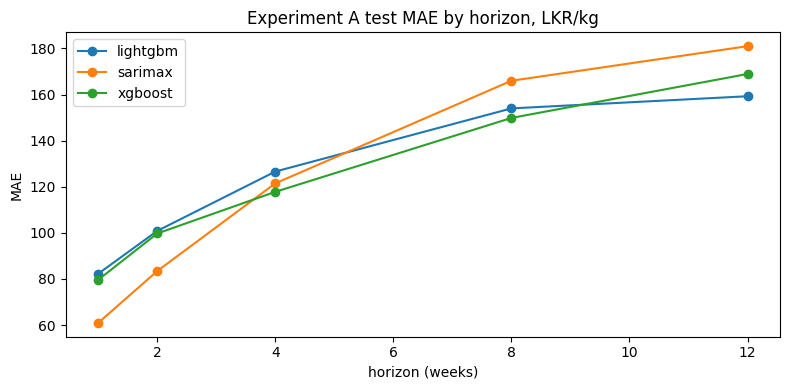

saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/experiment_a/predictions.csv
PASS Experiment A. These MAE values are this run.


In [17]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from statsmodels.tsa.statespace.sarimax import SARIMAX

table = pd.read_parquet(DRIVE / "01_from_notebook1" / "panel" / "training_table.parquet")
panel = pd.read_parquet(DRIVE / "01_from_notebook1" / "panel" / "analysis_ready_panel.parquet")
for frame in (table, panel):
    if "forecast_issue_week" in frame.columns:
        frame["forecast_issue_week"] = pd.to_datetime(frame["forecast_issue_week"])
panel["week_start"] = pd.to_datetime(panel["week_start"])

LGB_FIXED = {
    "n_estimators": 500, "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 20,
    "subsample": 0.8, "colsample_bytree": 0.8, "n_jobs": 1, "verbosity": -1, "random_state": 42,
}
XGB_FIXED = {
    "n_estimators": 500, "learning_rate": 0.05, "max_depth": 6, "subsample": 0.8,
    "colsample_bytree": 0.8, "tree_method": "hist", "early_stopping_rounds": 50,
    "n_jobs": 1, "random_state": 42,
}
FEATURES_A = [
    "price_lag_1w", "price_lag_2w", "price_lag_4w", "price_lag_8w", "price_lag_52w",
    "price_mean_4w", "price_mean_8w", "price_change_4w_pct",
    "season", "season_transition", "forecast_week_of_year", "week_within_season",
]
HORIZONS = (1, 2, 4, 8, 12)
EVAL_MARKETS = ["Dambulla", "Colombo", "Meegoda", "Nuwara Eliya"]
EVAL_IDS = {market.lower().replace(" ", "_") for market in EVAL_MARKETS}
MARKET_NAME = {market.lower().replace(" ", "_"): market for market in EVAL_MARKETS}
QUANTILES = ((0.05, "q05"), (0.50, "q50"), (0.95, "q95"))
print("Experiment A features", FEATURES_A)
print("fixed LightGBM", LGB_FIXED)
print("fixed XGBoost", XGB_FIXED)
print("Optuna is not used in this cell.")
print("Tree-count selection uses 2022 only; 2023 is reserved for CQR calibration.")

def eligible(frame, horizon):
    target_week = pd.to_datetime(frame["target_week"])
    issue = pd.to_datetime(frame["forecast_issue_week"])
    keep = (
        frame["forecast_horizon_weeks"].eq(horizon)
        & frame["last_observed_price_lkr_kg"].notna()
        & frame["target_is_observed"].astype(bool)
        & frame["target_price_lkr_kg"].notna()
        & frame["last_observed_price_lkr_kg"].gt(0)
        & frame["target_price_lkr_kg"].gt(0)
        & issue.notna()
    )
    leak_train = frame["split"].eq("train") & target_week.gt("2022-12-31")
    leak_cal = frame["split"].eq("calibrate") & target_week.gt("2023-12-31")
    subset = frame.loc[keep & ~leak_train & ~leak_cal].copy()
    subset["y_logret"] = np.log(subset["target_price_lkr_kg"] / subset["last_observed_price_lkr_kg"])
    return subset

def design_matrix(frame, columns):
    work = frame.copy()
    work["crop_id"] = pd.Categorical(work["crop_id"])
    work["market_id"] = pd.Categorical(work["market_id"])
    work["season"] = pd.Categorical(work["season"], categories=["Maha", "Yala"])
    numeric = [name for name in columns if name != "season"]
    pieces = [work[numeric].apply(pd.to_numeric, errors="coerce")]
    names = list(numeric)
    for name in ("crop_id", "market_id", "season"):
        codes = work[name].cat.codes.astype(float)
        pieces.append(codes.where(codes >= 0).rename(name))
        names.append(name)
    return pd.concat(pieces, axis=1), names

def score_frame(score, point, low, high, model, feature_set):
    market = score["market_id"].map(MARKET_NAME).fillna(score["market_id"])
    return pd.DataFrame({
        "unique_id": score["crop_id"].astype(str) + "__" + market.astype(str),
        "crop": score["crop_id"].astype(str),
        "market": market.astype(str),
        "forecast_issue_week": pd.to_datetime(score["forecast_issue_week"]),
        "target_week": pd.to_datetime(score["target_week"]),
        "horizon": score["forecast_horizon_weeks"].astype(int),
        "y_true": score["target_price_lkr_kg"].astype(float),
        "y_pred": point,
        "y_pred_q05": low,
        "y_pred_q95": high,
        "model": model,
        "split": score["split"].astype(str),
        "is_shock": score["is_shock"].astype(bool),
        "season": score["season"].astype(str),
        "target_form": "price",
        "feature_set": feature_set,
    })

def block_metrics(y_true, y_pred, low, high):
    error = y_pred - y_true
    ape = np.abs(error) / np.clip(y_true, 1e-6, None)
    out = {
        "n_scored": int(len(y_true)),
        "mae": round(float(np.mean(np.abs(error))), 2) if len(y_true) else None,
        "rmse": round(float(np.sqrt(np.mean(error ** 2))), 2) if len(y_true) else None,
        "mape": round(float(np.mean(ape) * 100), 2) if len(y_true) else None,
    }
    if np.isfinite(low).any() and np.isfinite(high).any():
        residual = y_true - y_pred
        out["pinball"] = round(float(np.mean(np.where(residual >= 0, 0.5 * residual, -0.5 * residual))), 2)
        out["picp"] = round(float(np.nanmean((y_true >= low) & (y_true <= high)) * 100), 2)
        out["interval_width"] = round(float(np.nanmean(high - low)), 2)
    else:
        out["pinball"] = None
        out["picp"] = None
        out["interval_width"] = None
    return out

def metrics_table(predictions):
    test = predictions[predictions["split"].eq("test")]
    rows = []
    for (model, horizon), group in test.groupby(["model", "horizon"], sort=True):
        rows.append({"model": model, "horizon": int(horizon), "slice": "test", "target_form": "price", **block_metrics(group["y_true"].to_numpy(), group["y_pred"].to_numpy(), group["y_pred_q05"].to_numpy(), group["y_pred_q95"].to_numpy())})
        shock = group[group["is_shock"].astype(bool)]
        if not shock.empty:
            rows.append({"model": model, "horizon": int(horizon), "slice": "shock_2024q1", "target_form": "price", **block_metrics(shock["y_true"].to_numpy(), shock["y_pred"].to_numpy(), shock["y_pred_q05"].to_numpy(), shock["y_pred_q95"].to_numpy())})
    return pd.DataFrame(rows)

def _internal_tree_selection_masks(subset):
    """
    Create a chronological model-selection split entirely inside the
    pre-2023 training period.

    2023 is reserved for conformal calibration and is not touched here.
    """
    target_week = pd.to_datetime(
        subset["target_week"],
        format="mixed",
        errors="raise",
    ).dt.normalize()

    train_rows = subset["split"].eq("train")

    selector_train = (
        train_rows
        & target_week.le(
            pd.Timestamp("2021-12-31")
        )
    )

    selector_validation = (
        train_rows
        & target_week.ge(
            pd.Timestamp("2022-01-01")
        )
        & target_week.le(
            pd.Timestamp("2022-12-31")
        )
    )

    final_train = train_rows.copy()
    calibration = subset["split"].eq("calibrate")
    test = subset["split"].eq("test")

    if (
        selector_train
        & selector_validation
    ).any():
        raise RuntimeError(
            "Internal selector train and validation rows overlap."
        )

    if (
        selector_validation
        & calibration
    ).any():
        raise RuntimeError(
            "2023 calibration rows entered early-stopping validation."
        )

    if (
        final_train
        & calibration
    ).any():
        raise RuntimeError(
            "Calibration rows entered final tree fitting."
        )

    if (
        final_train
        & test
    ).any():
        raise RuntimeError(
            "Held-out test rows entered final tree fitting."
        )

    if int(selector_train.sum()) < 50:
        raise RuntimeError(
            "Not enough rows before 2022 for selector training."
        )

    if int(selector_validation.sum()) < 20:
        raise RuntimeError(
            "Not enough 2022 rows for internal early stopping."
        )

    if int(final_train.sum()) < 50:
        raise RuntimeError(
            "Not enough rows for final pre-2023 model fitting."
        )

    if int(calibration.sum()) < 20:
        raise RuntimeError(
            "Not enough untouched 2023 rows for CQR calibration."
        )

    selector_train_max = target_week[
        selector_train
    ].max()

    selector_validation_min = target_week[
        selector_validation
    ].min()

    if (
        pd.notna(selector_train_max)
        and pd.notna(selector_validation_min)
        and selector_train_max
        >= selector_validation_min
    ):
        raise RuntimeError(
            "Internal model-selection split is not chronological."
        )

    return {
        "selector_train": selector_train.to_numpy(),
        "selector_validation": selector_validation.to_numpy(),
        "final_train": final_train.to_numpy(),
        "calibration": calibration.to_numpy(),
        "test": test.to_numpy(),
        "selector_train_max_target": selector_train_max,
        "selector_validation_min_target": selector_validation_min,
        "selector_validation_max_target": target_week[
            selector_validation
        ].max(),
        "final_train_max_target": target_week[
            final_train
        ].max(),
    }


def fit_trees(
    frame,
    columns,
    feature_set,
    model_dir,
):
    """
    Select the boosting iteration count on 2022 only, then refit the
    saved estimator on every eligible pre-2023 training row.

    The 2023 block remains untouched until conformal calibration.
    """
    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    parts = []
    live = []
    protocol_records = []

    for horizon in HORIZONS:
        print(
            f"fitting {feature_set} horizon {horizon}",
            flush=True,
        )

        subset = eligible(
            frame,
            horizon,
        )

        matrix, names = design_matrix(
            subset,
            columns,
        )

        y = subset[
            "y_logret"
        ].to_numpy(
            dtype=float
        )

        masks = _internal_tree_selection_masks(
            subset
        )

        selector_train_pos = np.flatnonzero(
            masks["selector_train"]
        )
        selector_validation_pos = np.flatnonzero(
            masks["selector_validation"]
        )
        final_train_pos = np.flatnonzero(
            masks["final_train"]
        )

        x_selector_train = matrix.iloc[
            selector_train_pos
        ]
        y_selector_train = y[
            masks["selector_train"]
        ]

        x_selector_validation = matrix.iloc[
            selector_validation_pos
        ]
        y_selector_validation = y[
            masks["selector_validation"]
        ]

        x_final_train = matrix.iloc[
            final_train_pos
        ]
        y_final_train = y[
            masks["final_train"]
        ]

        score_mask = (
            subset["market_id"].isin(
                EVAL_IDS
            )
            & subset["split"].isin(
                [
                    "calibrate",
                    "test",
                ]
            )
        )

        score = subset.loc[
            score_mask
        ].copy()

        x_score = matrix.loc[
            score_mask
        ]

        origin = score[
            "last_observed_price_lkr_kg"
        ].to_numpy(
            dtype=float
        )

        print(
            "  selector train",
            len(x_selector_train),
            "| selector validation 2022",
            len(x_selector_validation),
            "| final pre-2023 fit",
            len(x_final_train),
            "| untouched calibration 2023",
            int(
                masks["calibration"].sum()
            ),
            flush=True,
        )

        fitted = {}

        for alpha, label in QUANTILES:
            # --------------------------------------------------
            # LightGBM iteration selection on 2022.
            # --------------------------------------------------

            selector_lgb = lgb.LGBMRegressor(
                objective="quantile",
                alpha=alpha,
                **LGB_FIXED,
            )

            selector_lgb.fit(
                x_selector_train,
                y_selector_train,
                eval_set=[
                    (
                        x_selector_validation,
                        y_selector_validation,
                    )
                ],
                callbacks=[
                    lgb.early_stopping(
                        50,
                        verbose=False,
                    ),
                    lgb.log_evaluation(0),
                ],
            )

            lgb_best_iteration = getattr(
                selector_lgb,
                "best_iteration_",
                None,
            )

            if (
                lgb_best_iteration is None
                or int(lgb_best_iteration) < 1
            ):
                lgb_best_iteration = int(
                    LGB_FIXED[
                        "n_estimators"
                    ]
                )
            else:
                lgb_best_iteration = int(
                    lgb_best_iteration
                )

            final_lgb_params = dict(
                LGB_FIXED
            )
            final_lgb_params[
                "n_estimators"
            ] = lgb_best_iteration

            lgb_model = lgb.LGBMRegressor(
                objective="quantile",
                alpha=alpha,
                **final_lgb_params,
            )

            lgb_model.fit(
                x_final_train,
                y_final_train,
            )

            # --------------------------------------------------
            # XGBoost iteration selection on 2022.
            # XGBoost best_iteration is zero based.
            # --------------------------------------------------

            selector_xgb = xgb.XGBRegressor(
                objective="reg:quantileerror",
                quantile_alpha=alpha,
                **XGB_FIXED,
            )

            selector_xgb.fit(
                x_selector_train,
                y_selector_train,
                eval_set=[
                    (
                        x_selector_validation,
                        y_selector_validation,
                    )
                ],
                verbose=False,
            )

            xgb_best_zero_based = getattr(
                selector_xgb,
                "best_iteration",
                None,
            )

            if xgb_best_zero_based is None:
                xgb_best_iteration = int(
                    XGB_FIXED[
                        "n_estimators"
                    ]
                )
            else:
                xgb_best_iteration = int(
                    xgb_best_zero_based
                ) + 1

            final_xgb_params = {
                key: value
                for key, value in XGB_FIXED.items()
                if key
                != "early_stopping_rounds"
            }

            final_xgb_params[
                "n_estimators"
            ] = xgb_best_iteration

            xgb_model = xgb.XGBRegressor(
                objective="reg:quantileerror",
                quantile_alpha=alpha,
                **final_xgb_params,
            )

            xgb_model.fit(
                x_final_train,
                y_final_train,
                verbose=False,
            )

            selection_record = {
                "feature_set": feature_set,
                "horizon": int(horizon),
                "quantile": float(alpha),
                "label": label,
                "selector_train_target_end": (
                    None
                    if pd.isna(
                        masks[
                            "selector_train_max_target"
                        ]
                    )
                    else pd.Timestamp(
                        masks[
                            "selector_train_max_target"
                        ]
                    ).strftime(
                        "%Y-%m-%d"
                    )
                ),
                "selector_validation_target_start": (
                    None
                    if pd.isna(
                        masks[
                            "selector_validation_min_target"
                        ]
                    )
                    else pd.Timestamp(
                        masks[
                            "selector_validation_min_target"
                        ]
                    ).strftime(
                        "%Y-%m-%d"
                    )
                ),
                "selector_validation_target_end": (
                    None
                    if pd.isna(
                        masks[
                            "selector_validation_max_target"
                        ]
                    )
                    else pd.Timestamp(
                        masks[
                            "selector_validation_max_target"
                        ]
                    ).strftime(
                        "%Y-%m-%d"
                    )
                ),
                "final_train_target_end": (
                    None
                    if pd.isna(
                        masks[
                            "final_train_max_target"
                        ]
                    )
                    else pd.Timestamp(
                        masks[
                            "final_train_max_target"
                        ]
                    ).strftime(
                        "%Y-%m-%d"
                    )
                ),
                "selector_train_rows": int(
                    masks[
                        "selector_train"
                    ].sum()
                ),
                "selector_validation_rows": int(
                    masks[
                        "selector_validation"
                    ].sum()
                ),
                "final_train_rows": int(
                    masks[
                        "final_train"
                    ].sum()
                ),
                "untouched_2023_calibration_rows": int(
                    masks[
                        "calibration"
                    ].sum()
                ),
                "held_out_test_rows": int(
                    masks[
                        "test"
                    ].sum()
                ),
                "lightgbm_selected_n_estimators": int(
                    lgb_best_iteration
                ),
                "xgboost_selected_n_estimators": int(
                    xgb_best_iteration
                ),
            }

            protocol_records.append(
                selection_record
            )

            joblib.dump(
                {
                    "model": lgb_model,
                    "columns": names,
                    "horizon": horizon,
                    "alpha": alpha,
                    "feature_set": feature_set,
                    "params": final_lgb_params,
                    "selection_protocol": selection_record,
                    "calibration_set_used_for_model_selection": False,
                },
                model_dir
                / (
                    f"lightgbm_{feature_set}_"
                    f"h{horizon}_{label}.joblib"
                ),
            )

            joblib.dump(
                {
                    "model": xgb_model,
                    "columns": names,
                    "horizon": horizon,
                    "alpha": alpha,
                    "feature_set": feature_set,
                    "params": final_xgb_params,
                    "selection_protocol": selection_record,
                    "calibration_set_used_for_model_selection": False,
                },
                model_dir
                / (
                    f"xgboost_{feature_set}_"
                    f"h{horizon}_{label}.joblib"
                ),
            )

            print(
                f"  h={horizon} {label} "
                f"LGB trees={lgb_best_iteration} "
                f"XGB trees={xgb_best_iteration}",
                flush=True,
            )

            fitted[
                (
                    "lightgbm",
                    label,
                )
            ] = np.maximum(
                origin
                * np.exp(
                    np.asarray(
                        lgb_model.predict(
                            x_score
                        ),
                        dtype=float,
                    )
                ),
                0.01,
            )

            fitted[
                (
                    "xgboost",
                    label,
                )
            ] = np.maximum(
                origin
                * np.exp(
                    np.asarray(
                        xgb_model.predict(
                            x_score
                        ),
                        dtype=float,
                    )
                ),
                0.01,
            )

        for model_name in (
            "lightgbm",
            "xgboost",
        ):
            parts.append(
                score_frame(
                    score,
                    fitted[
                        (
                            model_name,
                            "q50",
                        )
                    ],
                    fitted[
                        (
                            model_name,
                            "q05",
                        )
                    ],
                    fitted[
                        (
                            model_name,
                            "q95",
                        )
                    ],
                    model_name,
                    feature_set,
                )
            )

        if feature_set == "B":
            indexed = score.copy()
            indexed["_pos"] = np.arange(
                len(indexed)
            )

            last_rows = (
                indexed[
                    indexed[
                        "split"
                    ].eq("test")
                ]
                .sort_values(
                    "forecast_issue_week"
                )
                .groupby(
                    [
                        "crop_id",
                        "market_id",
                    ],
                    observed=True,
                )
                .tail(1)
            )

            for _, row in last_rows.iterrows():
                vector = {}

                for name in names:
                    value = x_score.iloc[
                        int(
                            row[
                                "_pos"
                            ]
                        )
                    ][name]

                    vector[name] = (
                        None
                        if pd.isna(
                            value
                        )
                        else float(
                            value
                        )
                    )

                live.append(
                    {
                        "crop": str(
                            row[
                                "crop_id"
                            ]
                        ),
                        "market": str(
                            row[
                                "market_id"
                            ]
                        ),
                        "market_name": MARKET_NAME[
                            str(
                                row[
                                    "market_id"
                                ]
                            )
                        ],
                        "horizon": int(
                            horizon
                        ),
                        "origin_price": float(
                            row[
                                "last_observed_price_lkr_kg"
                            ]
                        ),
                        "forecast_issue_week": pd.Timestamp(
                            row[
                                "forecast_issue_week"
                            ]
                        ).strftime(
                            "%Y-%m-%d"
                        ),
                        "target_week": pd.Timestamp(
                            row[
                                "target_week"
                            ]
                        ).strftime(
                            "%Y-%m-%d"
                        ),
                        "y_true": float(
                            row[
                                "target_price_lkr_kg"
                            ]
                        ),
                        "features": vector,
                    }
                )

    protocol = {
        "feature_set": feature_set,
        "selection_method": "chronological internal early stopping",
        "selector_train": "eligible training targets through 2021-12-31",
        "selector_validation": "eligible training targets in 2022",
        "final_refit": "all eligible training targets through 2022-12-31",
        "conformal_calibration": "2023 only; not used for model selection",
        "held_out_test": "2024-2025",
        "early_stopping_rounds": 50,
        "optuna_used": False,
        "records": protocol_records,
    }

    (
        model_dir
        / "training_protocol.json"
    ).write_text(
        json.dumps(
            protocol,
            indent=2,
        ),
        encoding="utf-8",
    )

    return (
        pd.concat(
            parts,
            ignore_index=True,
        ),
        live,
    )

def fit_sarimax(panel_frame):
    order, seasonal_order = (1, 1, 1), (1, 0, 0, 52)
    scoped = panel_frame[panel_frame["market"].isin(EVAL_MARKETS)].copy()
    scoped["unique_id"] = scoped["crop"] + "__" + scoped["market"]
    rows = []
    meta = {"order": list(order), "seasonal_order": list(seasonal_order), "note": "fixed order because statsforecast is not installed"}
    out_dir = DRIVE / "01_from_notebook1" / "experiment_a"
    out_dir.mkdir(parents=True, exist_ok=True)
    for unique_id, group in scoped.groupby("unique_id", sort=False):
        group = group.sort_values("week_start").reset_index(drop=True)
        first_valid = group["price_feature"].first_valid_index()
        if first_valid is None:
            print("skip", unique_id, "no usable price state")
            continue
        if int(first_valid) > 0:
            group = group.iloc[int(first_valid):].reset_index(drop=True)
        y_state = group["price_feature"].astype(float).ffill().to_numpy()
        if not np.isfinite(y_state).all():
            raise RuntimeError(f"SARIMAX state still contains missing values for {unique_id}")
        train_idx = np.where(group["week_start"] <= "2022-12-31")[0]
        if len(train_idx) < 80:
            print("skip", unique_id, "train weeks", len(train_idx))
            continue
        origin0 = int(train_idx[-1])
        print("SARIMAX", unique_id, "train weeks", len(train_idx), flush=True)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = SARIMAX(y_state[: origin0 + 1], order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=50)
        for origin in range(origin0, len(group) - 1):
            if origin > origin0:
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        result = result.append(y_state[origin: origin + 1], refit=False)
                except Exception:
                    break
            split = group.at[origin, "split"] if "split" in group.columns else None
            issue = pd.Timestamp(group.at[origin, "week_start"])
            if issue <= pd.Timestamp("2022-12-31"):
                split = "train"
            elif issue.year == 2023:
                split = "calibrate"
            elif issue.year in (2024, 2025):
                split = "test"
            else:
                split = "other"
            if split not in {"calibrate", "test"}:
                continue
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    forecast = np.asarray(result.get_forecast(max(HORIZONS)).predicted_mean, dtype=float)
            except Exception:
                continue
            for horizon in HORIZONS:
                target = origin + horizon
                if target >= len(group) or not bool(group.at[target, "is_observed"]):
                    continue
                y_true = float(group.at[target, "price"])
                if not np.isfinite(y_true) or y_true <= 0:
                    continue
                y_pred = float(forecast[horizon - 1])
                if not np.isfinite(y_pred):
                    continue
                rows.append({
                    "unique_id": unique_id,
                    "crop": group.at[origin, "crop"],
                    "market": group.at[origin, "market"],
                    "forecast_issue_week": issue,
                    "target_week": pd.Timestamp(group.at[target, "week_start"]),
                    "horizon": horizon,
                    "y_true": y_true,
                    "y_pred": max(y_pred, 0.01),
                    "y_pred_q05": np.nan,
                    "y_pred_q95": np.nan,
                    "model": "sarimax",
                    "split": split,
                    "is_shock": bool(issue >= pd.Timestamp("2024-01-01") and issue <= pd.Timestamp("2024-03-31")),
                    "season": group.at[origin, "season"],
                    "target_form": "price",
                    "feature_set": "A",
                })
        partial = pd.DataFrame(rows)
        partial.to_csv(out_dir / "sarimax_partial.csv", index=False)
        print("  saved partial SARIMAX rows", len(partial), flush=True)
    (out_dir / "sarimax_order.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return pd.DataFrame(rows), meta

sarimax_rows, sarimax_meta = fit_sarimax(panel)
print("SARIMAX rows", len(sarimax_rows), sarimax_meta)
tree_rows, _live_unused = fit_trees(table, FEATURES_A, "A", DRIVE / "01_from_notebook1" / "experiment_a" / "models")
predictions = pd.concat([tree_rows, sarimax_rows], ignore_index=True)
by_model = metrics_table(predictions)
out = DRIVE / "01_from_notebook1" / "experiment_a"
predictions.to_csv(out / "predictions.csv", index=False)
by_model.to_csv(out / "metrics_by_model_horizon.csv", index=False)
test = by_model[by_model["slice"].eq("test")]
print(test.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
for model, part in test.groupby("model"):
    part = part.sort_values("horizon")
    ax.plot(part["horizon"], part["mae"], marker="o", label=model)
ax.set_title("Experiment A test MAE by horizon, LKR/kg")
ax.set_xlabel("horizon (weeks)")
ax.set_ylabel("MAE")
ax.legend()
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "experiment_a_mae.png", dpi=120)
plt.show()
print("saved", out / "predictions.csv")
print("PASS Experiment A. These MAE values are this run.")

## Cell 16 — Experiment B — weather, macros, finished extent, and 2023 conformal qhat

Same three model families. Feature set B. SARIMAX is not fit again; the Experiment A SARIMAX rows are placed beside B. Conformal `qhat` is fit on 2023 issue weeks only.



---

Experiment B features ['price_lag_1w', 'price_lag_2w', 'price_lag_4w', 'price_lag_8w', 'price_lag_52w', 'price_mean_4w', 'price_mean_8w', 'price_change_4w_pct', 'season', 'season_transition', 'forecast_week_of_year', 'week_within_season', 'origin_rainfall_1w_mm', 'origin_rainfall_sum_4w_mm', 'origin_rainfall_sum_8w_mm', 'origin_mean_temp_4w_c', 'origin_rainfall_anomaly_4w_mm', 'diesel_price_lkr_litre', 'usd_lkr_rate', 'inflation_rate_pct', 'previous_season_extent', 'same_season_previous_year_extent', 'historical_mean_season_extent', 'extent_change_vs_previous_season']
fitting B horizon 1
  selector train 5463 | selector validation 2022 1089 | final pre-2023 fit 6552 | untouched calibration 2023 1062
  h=1 q05 LGB trees=65 XGB trees=126
  h=1 q50 LGB trees=33 XGB trees=17
  h=1 q95 LGB trees=1 XGB trees=19
fitting B horizon 2
  selector train 5442 | selector validation 2022 1089 | final pre-2023 fit 6531 | untouched calibration 2023 1041
  h=2 q05 LGB trees=85 XGB trees=131
  h=2 q50 LG

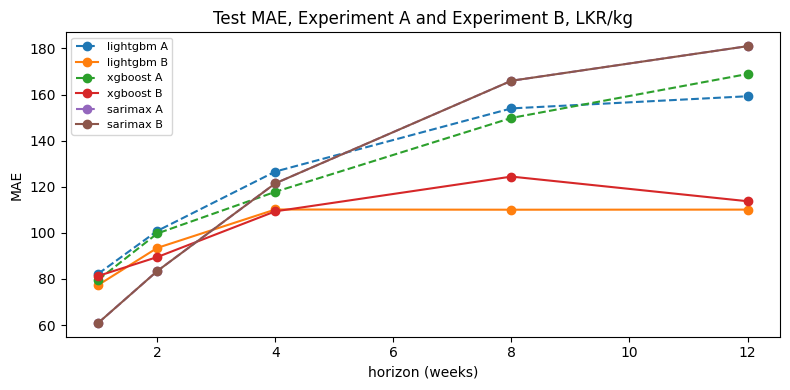

PASS Experiment B. Tree count was selected on 2022; qhat was fit on untouched 2023 only.
Experiment C is handled only in the real-cultivation section below. A/B results above are unchanged.


In [18]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "fit_trees" not in globals() or "table" not in globals() or "FEATURES_A" not in globals():
    raise SystemExit("Run cell 15 in this same session first. This cell fits Experiment B only and does not refit SARIMAX.")
FEATURES_B = FEATURES_A + [
    "origin_rainfall_1w_mm", "origin_rainfall_sum_4w_mm", "origin_rainfall_sum_8w_mm",
    "origin_mean_temp_4w_c", "origin_rainfall_anomaly_4w_mm",
    "diesel_price_lkr_litre", "usd_lkr_rate", "inflation_rate_pct",
    "previous_season_extent", "same_season_previous_year_extent",
    "historical_mean_season_extent", "extent_change_vs_previous_season",
]
print("Experiment B features", FEATURES_B)
assert "cultivation_progress_ratio" not in FEATURES_B
for name in ("diesel_price_lkr_litre", "usd_lkr_rate", "inflation_rate_pct"):
    if not bool(table[name].notna().any()):
        raise SystemExit(f"Experiment B is unavailable: {name} is all null")

tree_b, live = fit_trees(table, FEATURES_B, "B", DRIVE / "01_from_notebook1" / "experiment_b" / "models")
sarimax = pd.read_csv(DRIVE / "01_from_notebook1" / "experiment_a" / "predictions.csv")
sarimax = sarimax[sarimax["model"].eq("sarimax")].copy()
predictions_b = pd.concat([tree_b, sarimax], ignore_index=True)
predictions_a = pd.read_csv(DRIVE / "01_from_notebook1" / "experiment_a" / "predictions.csv")

def conformal_qhat(scores):
    scores = scores[np.isfinite(scores)]
    n = len(scores)

    if n == 0:
        return 0.0

    level = min(
        1.0,
        np.ceil((n + 1) * 0.90) / n,
    )

    return float(
        np.quantile(
            scores,
            level,
            method="higher",
        )
    )


def project_interval_around_median(q05, q50, q95):
    """
    Preserve the trained q50 point forecast while guaranteeing a
    logically ordered reported interval. Raw heads remain available
    for crossing diagnostics.
    """
    q05 = np.asarray(q05, dtype=float)
    q50 = np.asarray(q50, dtype=float)
    q95 = np.asarray(q95, dtype=float)

    lower = np.minimum.reduce([q05, q50, q95])
    upper = np.maximum.reduce([q05, q50, q95])

    return lower, q50, upper


def cqr_tables(predictions):
    rows = []
    qhats = {}

    for model in ("lightgbm", "xgboost"):
        qhats[model] = {}
        block = predictions[
            predictions["model"].eq(model)
        ]

        for horizon, group in block.groupby("horizon"):
            calibrate = group[
                group["split"].eq("calibrate")
            ]
            test = group[
                group["split"].eq("test")
            ]

            cal_lo, _, cal_hi = project_interval_around_median(
                calibrate["y_pred_q05"].to_numpy(float),
                calibrate["y_pred"].to_numpy(float),
                calibrate["y_pred_q95"].to_numpy(float),
            )

            test_lo, test_med, test_hi = project_interval_around_median(
                test["y_pred_q05"].to_numpy(float),
                test["y_pred"].to_numpy(float),
                test["y_pred_q95"].to_numpy(float),
            )

            y_cal = calibrate["y_true"].to_numpy(float)

            scores = np.maximum(
                cal_lo - y_cal,
                y_cal - cal_hi,
            )

            qhat = conformal_qhat(scores)
            qhats[model][str(int(horizon))] = round(qhat, 4)

            raw = block_metrics(
                test["y_true"].to_numpy(float),
                test_med,
                test_lo,
                test_hi,
            )

            calibrated = block_metrics(
                test["y_true"].to_numpy(float),
                test_med,
                test_lo - qhat,
                test_hi + qhat,
            )

            raw_q05 = test["y_pred_q05"].to_numpy(float)
            raw_q95 = test["y_pred_q95"].to_numpy(float)
            raw_cross = (
                (raw_q05 > test_med)
                | (test_med > raw_q95)
            )

            rows.append({
                "model": model,
                "horizon": int(horizon),
                "n_calibration": int(len(calibrate)),
                "n_test": int(len(test)),
                "qhat": round(qhat, 4),
                "pinball": raw["pinball"],
                "picp_raw": raw["picp"],
                "interval_width_raw": raw["interval_width"],
                "picp_cqr": calibrated["picp"],
                "interval_width_cqr": calibrated["interval_width"],
                "raw_quantile_crossing_count": int(raw_cross.sum()),
                "raw_quantile_crossing_rate_pct": float(
                    raw_cross.mean() * 100
                ),
                "reported_interval_ordered": True,
            })

    payload = {
        "method": "split_cqr_with_ordered_interval_projection",
        "alpha": 0.1,
        "quantile_ordering": {
            "raw_predictions_retained_for_diagnostic": True,
            "reported_interval_rule": (
                "lower=min(q05,q50,q95); median=q50 unchanged; "
                "upper=max(q05,q50,q95)"
            ),
            "point_forecast_changed": False,
        },
        "model_selection_validation": (
            "2022 target weeks inside the training period; "
            "2023 is not used for early stopping"
        ),
        "final_tree_fit": (
            "all eligible pre-2023 training rows after tree-count selection"
        ),
        "calibration": (
            "2023 issue weeks only; reserved exclusively for CQR"
        ),
        "test": (
            "2024-2025 issue weeks; ordered interval projected "
            "before CQR; q50 point forecasts unchanged"
        ),
        "qhat_by_model": qhats,
        "by_model_horizon": rows,
        "limit": (
            "Time-ordered prices are not exchangeable, so this is "
            "empirical calibration rather than a universal guarantee."
        ),
    }

    return pd.DataFrame(rows), payload

cqr_a_rows, cqr_a = cqr_tables(predictions_a)
cqr_b_rows, cqr_b = cqr_tables(predictions_b)
by_b = metrics_table(predictions_b)
extra = cqr_b_rows[["model", "horizon", "qhat", "picp_cqr", "interval_width_cqr", "n_calibration"]]
by_b = by_b.merge(extra, on=["model", "horizon"], how="left")
by_b.loc[~by_b["slice"].eq("test"), ["qhat", "picp_cqr", "interval_width_cqr", "n_calibration"]] = np.nan

def wide(predictions, cqr_rows, suffix):
    base = metrics_table(predictions)
    base = base[base["slice"].eq("test")][["model", "horizon", "mae", "rmse", "mape", "pinball", "picp", "interval_width"]]
    base = base.merge(cqr_rows[["model", "horizon", "picp_cqr", "interval_width_cqr", "qhat"]], on=["model", "horizon"], how="left")
    return base.rename(columns={column: f"{column}_{suffix}" for column in base.columns if column not in ("model", "horizon")})

compared = wide(predictions_a, cqr_a_rows, "a").merge(wide(predictions_b, cqr_b_rows, "b"), on=["model", "horizon"])
compared["mae_change_pct"] = ((compared["mae_b"] - compared["mae_a"]) / compared["mae_a"] * 100).round(2)
compared["rmse_change_pct"] = ((compared["rmse_b"] - compared["rmse_a"]) / compared["rmse_a"] * 100).round(2)
print(compared.to_string(index=False))
print("MAE percent is (B - A) / A x 100. A negative percent is a lower error for B. SARIMAX is the same rows in both experiments.")

out = DRIVE / "01_from_notebook1" / "experiment_b"
predictions_b.to_csv(out / "predictions.csv", index=False)
by_b.to_csv(out / "metrics_by_model_horizon.csv", index=False)
by_b.to_csv(out / "metrics_with_cqr.csv", index=False)
compared.to_csv(out / "a_vs_b.csv", index=False)
(out / "cqr.json").write_text(json.dumps(cqr_b, indent=2), encoding="utf-8")
(DRIVE / "01_from_notebook1" / "experiment_a" / "cqr.json").write_text(json.dumps(cqr_a, indent=2), encoding="utf-8")
(out / "live_vectors.json").write_text(json.dumps(live, indent=2), encoding="utf-8")
print("live vectors", len(live), "expected 12 series x 5 horizons = 60")

fig, ax = plt.subplots(figsize=(8, 4))
for model in ("lightgbm", "xgboost", "sarimax"):
    part = compared[compared["model"].eq(model)].sort_values("horizon")
    ax.plot(part["horizon"], part["mae_a"], marker="o", linestyle="--", label=f"{model} A")
    ax.plot(part["horizon"], part["mae_b"], marker="o", label=f"{model} B")
ax.set_title("Test MAE, Experiment A and Experiment B, LKR/kg")
ax.set_xlabel("horizon (weeks)")
ax.set_ylabel("MAE")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "experiment_b_vs_a_mae.png", dpi=120)
plt.show()
print("PASS Experiment B. Tree count was selected on 2022; qhat was fit on untouched 2023 only.")
print("Experiment C is handled only in the real-cultivation section below. A/B results above are unchanged.")

## Cell C4 — Verify the exact common sample for B* versus C

C3 already saved the exact real-progress rows that passed the locked target-observation and chronology rules.

This cell does **not** broaden that sample.

- **B\*** receives those exact rows with B features only.
- **C** receives those exact same rows with B features plus national cultivation progress.

This is the controlled ablation test required by the proposal.


In [19]:
import json
import pandas as pd

print("======================================================")
print("EXPERIMENT C — EXACT COMMON B* / C SAMPLE")
print("======================================================")

C_ELIGIBLE_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
    / "c_eligible_table.parquet"
)

status = (
    json.loads(
        C_STATUS_PATH.read_text()
    )
    if C_STATUS_PATH.is_file()
    else {}
)

C_READY = (
    status.get("status")
    == "ready_to_train"
)

if not C_READY:
    print(
        "SKIP C4 — status:",
        status.get(
            "status",
            "unknown",
        ),
    )

elif not C_ELIGIBLE_PATH.is_file():
    raise SystemExit(
        "❌ c_eligible_table.parquet is missing. Run C3 first."
    )

else:
    c_eligible = pd.read_parquet(
        C_ELIGIBLE_PATH
    )

    if not c_eligible[
        "c_progress_available"
    ].astype(bool).all():
        raise SystemExit(
            "❌ C eligible file contains rows without real progress."
        )

    if not c_eligible[
        "cultivation_source_scope"
    ].eq("national").all():
        raise SystemExit(
            "❌ C eligible file contains non-national rows."
        )

    counts = (
        c_eligible.groupby(
            [
                "split",
                "forecast_horizon_weeks",
            ],
            as_index=False,
        )
        .size()
        .rename(
            columns={
                "size": "rows",
            }
        )
    )

    print(
        counts.to_string(index=False)
    )

    print(
        "rows passed to BOTH B* and C:",
        len(c_eligible),
    )

    print(
        "✅ B* and C receive the exact same eligible rows; "
        "only the feature columns differ."
    )


EXPERIMENT C — EXACT COMMON B* / C SAMPLE
    split  forecast_horizon_weeks  rows
calibrate                       1   684
calibrate                       2   684
calibrate                       4   684
calibrate                       8   690
calibrate                      12   690
     test                       1   798
     test                       2   792
     test                       4   786
     test                       8   777
     test                      12   783
    train                       1  1089
    train                       2  1077
    train                       4  1041
    train                       8   999
    train                      12   957
rows passed to BOTH B* and C: 12531
✅ B* and C receive the exact same eligible rows; only the feature columns differ.


## Cell C5 — Train B* and national Experiment C on the exact common sample

This cell uses the same strict tree-training protocol as Experiments A and B:

- tree count selected by early stopping on the internal 2022 training slice;
- saved estimator refit on all eligible training rows through 2022;
- 2023 untouched until CQR calibration;
- 2024–2025 held out for testing.

**B\*** uses B features on the exact C-eligible rows.  
**C** uses the same rows plus real national cultivation progress.

The B* and C samples are identical; only the feature columns differ.


In [20]:
import json
import numpy as np
import pandas as pd

print("======================================================")
print("EXPERIMENT C — FIT B* AND C")
print("======================================================")

status = json.loads(C_STATUS_PATH.read_text()) if C_STATUS_PATH.is_file() else {}
C_READY = status.get("status") == "ready_to_train"

if not C_READY:
    print("SKIP C5 — C is not ready on the locked split.")
else:
    required_globals = ["fit_trees","eligible","design_matrix","FEATURES_B","EVAL_IDS","MARKET_NAME","HORIZONS"]
    missing_globals = [name for name in required_globals if name not in globals()]
    if missing_globals:
        raise SystemExit(f"Run Cells 15 and 16 first in this session. Missing: {missing_globals}")

    c_eligible = pd.read_parquet(C_ELIGIBLE_PATH)
    FEATURES_C = FEATURES_B + [
        "cultivation_progress_ratio_real",
        "cultivation_target_exceeded_real",
    ]
    print("B* features", FEATURES_B)
    print("C features", FEATURES_C)

    cdir = DRIVE / "01_from_notebook1" / "experiment_c"
    bstar_pred, _ = fit_trees(c_eligible, FEATURES_B, "B_star", cdir / "models_b_star")
    c_pred, _ = fit_trees(c_eligible, FEATURES_C, "C", cdir / "models")

    bstar_pred.to_csv(cdir / "predictions_b_star.csv", index=False)
    c_pred.to_csv(cdir / "predictions_c.csv", index=False)

    # Build saved C live vectors from the latest REAL-progress test row per score series.
    c_live = []
    for horizon in HORIZONS:
        subset = eligible(c_eligible, horizon)
        matrix, names = design_matrix(subset, FEATURES_C)
        score_mask = subset["market_id"].isin(EVAL_IDS) & subset["split"].eq("test")
        score = subset.loc[score_mask].copy()
        latest = (
            score.sort_values("forecast_issue_week")
            .groupby(["crop_id","market_id"], observed=True)
            .tail(1)
        )
        for idx, row in latest.iterrows():
            xrow = matrix.loc[idx]
            vector = {
                name: (None if pd.isna(xrow[name]) else float(xrow[name]))
                for name in names
            }
            c_live.append({
                "crop": str(row["crop_id"]),
                "market": str(row["market_id"]),
                "market_name": MARKET_NAME.get(str(row["market_id"]), str(row["market_id"])),
                "horizon": int(horizon),
                "origin_price": float(row["last_observed_price_lkr_kg"]),
                "forecast_issue_week": pd.Timestamp(row["forecast_issue_week"]).strftime("%Y-%m-%d"),
                "target_week": pd.Timestamp(row["target_week"]).strftime("%Y-%m-%d"),
                "y_true": float(row["target_price_lkr_kg"]),
                "real_progress_ratio": float(row["cultivation_progress_ratio_real"]),
                "real_target_exceeded": int(row["cultivation_target_exceeded_real"]),
                "cultivation_report_date": pd.Timestamp(row["cultivation_report_date"]).strftime("%Y-%m-%d"),
                "features": vector,
            })

    (cdir / "live_vectors.json").write_text(json.dumps(c_live, indent=2), encoding="utf-8")
    print("saved B* predictions", len(bstar_pred))
    print("saved C predictions", len(c_pred))
    print("saved C live vectors", len(c_live))
    print("✅ C5 COMPLETE")


EXPERIMENT C — FIT B* AND C
B* features ['price_lag_1w', 'price_lag_2w', 'price_lag_4w', 'price_lag_8w', 'price_lag_52w', 'price_mean_4w', 'price_mean_8w', 'price_change_4w_pct', 'season', 'season_transition', 'forecast_week_of_year', 'week_within_season', 'origin_rainfall_1w_mm', 'origin_rainfall_sum_4w_mm', 'origin_rainfall_sum_8w_mm', 'origin_mean_temp_4w_c', 'origin_rainfall_anomaly_4w_mm', 'diesel_price_lkr_litre', 'usd_lkr_rate', 'inflation_rate_pct', 'previous_season_extent', 'same_season_previous_year_extent', 'historical_mean_season_extent', 'extent_change_vs_previous_season']
C features ['price_lag_1w', 'price_lag_2w', 'price_lag_4w', 'price_lag_8w', 'price_lag_52w', 'price_mean_4w', 'price_mean_8w', 'price_change_4w_pct', 'season', 'season_transition', 'forecast_week_of_year', 'week_within_season', 'origin_rainfall_1w_mm', 'origin_rainfall_sum_4w_mm', 'origin_rainfall_sum_8w_mm', 'origin_mean_temp_4w_c', 'origin_rainfall_anomaly_4w_mm', 'diesel_price_lkr_litre', 'usd_lkr_rat

## Cell C6 — 2023 conformal calibration and the actual B* versus C novelty test

The same 2023 calibration rule is applied separately to B* and C. Test metrics remain 2024–2025. The main question is whether C has lower held-out error than B* **on identical observations**. This cell also reports proper pinball loss at q05/q50/q95 and their mean.


In [21]:
import json
import numpy as np
import pandas as pd

print("======================================================")
print("EXPERIMENT C — NOVELTY EVALUATION")
print("======================================================")

status = json.loads(C_STATUS_PATH.read_text()) if C_STATUS_PATH.is_file() else {}
C_READY = status.get("status") == "ready_to_train"

if not C_READY:
    print("SKIP C6 — C is not ready.")
else:
    cdir = DRIVE / "01_from_notebook1" / "experiment_c"
    bstar_pred = pd.read_csv(cdir / "predictions_b_star.csv")
    c_pred = pd.read_csv(cdir / "predictions_c.csv")

    bstar_cqr_rows, bstar_cqr = cqr_tables(bstar_pred)
    c_cqr_rows, c_cqr = cqr_tables(c_pred)

    (cdir / "cqr_b_star.json").write_text(json.dumps(bstar_cqr, indent=2), encoding="utf-8")
    (cdir / "cqr.json").write_text(json.dumps(c_cqr, indent=2), encoding="utf-8")

    def qloss(y, pred, q):
        r = y - pred
        return float(np.mean(np.maximum(q * r, (q - 1) * r)))

    def detailed(predictions, cqr_payload):
        rows = []

        for (model, horizon), g in predictions[
            predictions["split"].eq("test")
        ].groupby(["model", "horizon"]):
            y = g["y_true"].to_numpy(float)
            p50 = g["y_pred"].to_numpy(float)
            raw05 = g["y_pred_q05"].to_numpy(float)
            raw95 = g["y_pred_q95"].to_numpy(float)

            p05, _, p95 = project_interval_around_median(
                raw05,
                p50,
                raw95,
            )

            raw_cross = (
                (raw05 > p50)
                | (p50 > raw95)
            )

            err = p50 - y
            qhat = float(
                cqr_payload["qhat_by_model"][
                    model
                ][str(int(horizon))]
            )

            lo = p05 - qhat
            hi = p95 + qhat

            rows.append({
                "model": model,
                "horizon": int(horizon),
                "n_scored": int(len(g)),
                "mae": round(float(np.mean(np.abs(err))), 2),
                "rmse": round(
                    float(np.sqrt(np.mean(err ** 2))),
                    2,
                ),
                "mape": round(
                    float(
                        np.mean(
                            np.abs(err)
                            / np.clip(y, 1e-6, None)
                        )
                        * 100
                    ),
                    2,
                ),
                "pinball_q05": round(
                    qloss(y, p05, 0.05),
                    3,
                ),
                "pinball_q50": round(
                    qloss(y, p50, 0.50),
                    3,
                ),
                "pinball_q95": round(
                    qloss(y, p95, 0.95),
                    3,
                ),
                "pinball_mean_3q": round(
                    float(np.mean([
                        qloss(y, p05, 0.05),
                        qloss(y, p50, 0.50),
                        qloss(y, p95, 0.95),
                    ])),
                    3,
                ),
                "picp_raw": round(
                    float(
                        np.mean(
                            (y >= p05)
                            & (y <= p95)
                        )
                        * 100
                    ),
                    2,
                ),
                "interval_width_raw": round(
                    float(np.mean(p95 - p05)),
                    2,
                ),
                "raw_quantile_crossing_count": int(
                    raw_cross.sum()
                ),
                "raw_quantile_crossing_rate_pct": round(
                    float(raw_cross.mean() * 100),
                    4,
                ),
                "reported_interval_order_violation_count": int(
                    (
                        (p05 > p50)
                        | (p50 > p95)
                    ).sum()
                ),
                "qhat": round(qhat, 4),
                "picp_cqr": round(
                    float(
                        np.mean(
                            (y >= lo)
                            & (y <= hi)
                        )
                        * 100
                    ),
                    2,
                ),
                "interval_width_cqr": round(
                    float(np.mean(hi - lo)),
                    2,
                ),
            })

        return pd.DataFrame(rows)

    m_b = detailed(bstar_pred, bstar_cqr)
    m_c = detailed(c_pred, c_cqr)
    m_b.to_csv(cdir / "metrics_b_star.csv", index=False)
    m_c.to_csv(cdir / "metrics_c.csv", index=False)

    # identical-key assertion
    KEY = ["crop","market","forecast_issue_week","target_week","horizon","model"]
    kb = set(map(tuple, bstar_pred[bstar_pred["split"].eq("test")][KEY].itertuples(index=False, name=None)))
    kc = set(map(tuple, c_pred[c_pred["split"].eq("test")][KEY].itertuples(index=False, name=None)))
    if kb != kc:
        raise SystemExit(f"B* and C test keys differ: B*={len(kb)} C={len(kc)} intersection={len(kb & kc)}")
    print("PASS identical B* / C held-out keys:", len(kb))

    comparison = m_b.merge(m_c, on=["model","horizon"], suffixes=("_b_star","_c"))
    comparison["mae_change_pct"] = (
        (comparison["mae_c"] - comparison["mae_b_star"]) / comparison["mae_b_star"] * 100
    ).round(2)
    comparison["rmse_change_pct"] = (
        (comparison["rmse_c"] - comparison["rmse_b_star"]) / comparison["rmse_b_star"] * 100
    ).round(2)
    comparison["pinball_mean_change_pct"] = (
        (comparison["pinball_mean_3q_c"] - comparison["pinball_mean_3q_b_star"])
        / comparison["pinball_mean_3q_b_star"] * 100
    ).round(2)

    comparison.to_csv(cdir / "b_star_vs_c.csv", index=False)

    print("\nB* VS C — NEGATIVE ERROR CHANGE MEANS C IS BETTER")
    print(comparison.to_string(index=False))

    print("\nPRIMARY LIGHTGBM NOVELTY TABLE")
    print(
        comparison[comparison["model"].eq("lightgbm")][[
            "horizon","n_scored_b_star","mae_b_star","mae_c","mae_change_pct",
            "rmse_b_star","rmse_c","rmse_change_pct",
            "pinball_mean_3q_b_star","pinball_mean_3q_c","pinball_mean_change_pct",
            "picp_cqr_b_star","picp_cqr_c",
            "interval_width_cqr_b_star","interval_width_cqr_c",
        ]].to_string(index=False)
    )
    print("✅ C6 COMPLETE — this table is the empirical novelty test")


EXPERIMENT C — NOVELTY EVALUATION
PASS identical B* / C held-out keys: 4542

B* VS C — NEGATIVE ERROR CHANGE MEANS C IS BETTER
   model  horizon  n_scored_b_star  mae_b_star  rmse_b_star  mape_b_star  pinball_q05_b_star  pinball_q50_b_star  pinball_q95_b_star  pinball_mean_3q_b_star  picp_raw_b_star  interval_width_raw_b_star  raw_quantile_crossing_count_b_star  raw_quantile_crossing_rate_pct_b_star  reported_interval_order_violation_count_b_star  qhat_b_star  picp_cqr_b_star  interval_width_cqr_b_star  n_scored_c  mae_c  rmse_c  mape_c  pinball_q05_c  pinball_q50_c  pinball_q95_c  pinball_mean_3q_c  picp_raw_c  interval_width_raw_c  raw_quantile_crossing_count_c  raw_quantile_crossing_rate_pct_c  reported_interval_order_violation_count_c   qhat_c  picp_cqr_c  interval_width_cqr_c  mae_change_pct  rmse_change_pct  pinball_mean_change_pct
lightgbm        1              462       57.88        82.02        29.02               6.217              28.940              10.564                  

## Cell C7 — Novelty breakdown and plots

This cell shows where C helps or hurts by horizon, crop, and market. It does not hide a negative result. It also plots the real progress values used in the experiment.


EXPERIMENT C — BREAKDOWN


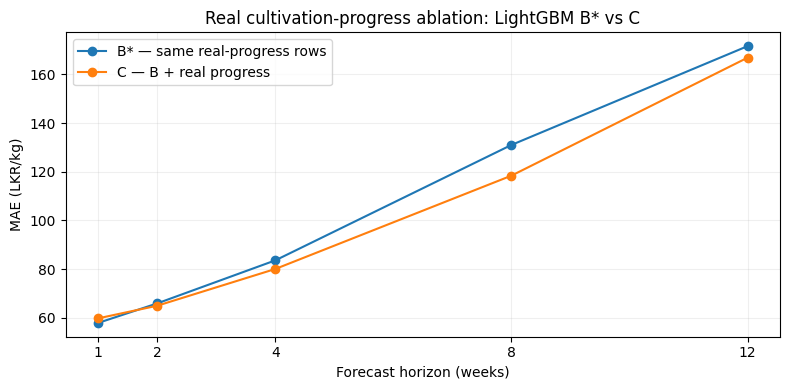

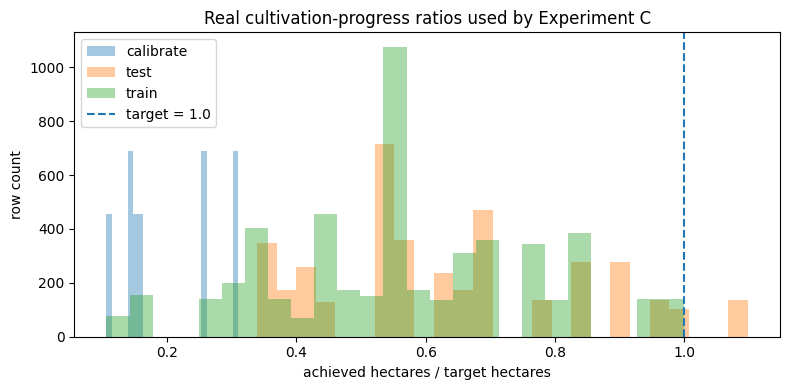


H4 BY CROP
  crop   n  mae_b_star  mae_c  mae_change_pct
carrot 151      102.98  98.49           -4.37
 leeks 151       50.27  46.77           -6.97
tomato 151       97.48  94.86           -2.69

H4 BY MARKET
      market   n  mae_b_star  mae_c  mae_change_pct
     Colombo 117       86.29  83.40           -3.35
    Dambulla 117       83.14  79.67           -4.18
     Meegoda 114       84.93  80.09           -5.70
Nuwara Eliya 105       79.57  76.64           -3.67
✅ C7 COMPLETE


In [22]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("======================================================")
print("EXPERIMENT C — BREAKDOWN")
print("======================================================")

status = json.loads(C_STATUS_PATH.read_text()) if C_STATUS_PATH.is_file() else {}
C_READY = status.get("status") == "ready_to_train"

if not C_READY:
    print("SKIP C7 — C is not ready.")
else:
    cdir = DRIVE / "01_from_notebook1" / "experiment_c"
    comp = pd.read_csv(cdir / "b_star_vs_c.csv")
    c_pred = pd.read_csv(cdir / "predictions_c.csv")
    b_pred = pd.read_csv(cdir / "predictions_b_star.csv")
    c_table = pd.read_parquet(C_ELIGIBLE_PATH)

    primary = comp[comp["model"].eq("lightgbm")].sort_values("horizon")
    fig, ax = plt.subplots(figsize=(8,4))
    ax.plot(primary["horizon"], primary["mae_b_star"], marker="o", label="B* — same real-progress rows")
    ax.plot(primary["horizon"], primary["mae_c"], marker="o", label="C — B + real progress")
    ax.set_title("Real cultivation-progress ablation: LightGBM B* vs C")
    ax.set_xlabel("Forecast horizon (weeks)")
    ax.set_ylabel("MAE (LKR/kg)")
    ax.set_xticks([1,2,4,8,12])
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "experiment_c_bstar_vs_c_mae.png", dpi=120)
    plt.show()

    fig, ax = plt.subplots(figsize=(8,4))
    for split, g in c_table.groupby("split"):
        vals = pd.to_numeric(g["cultivation_progress_ratio_real"], errors="coerce").dropna()
        if len(vals):
            ax.hist(vals, bins=25, alpha=0.4, label=split)
    ax.axvline(1.0, linestyle="--", label="target = 1.0")
    ax.set_title("Real cultivation-progress ratios used by Experiment C")
    ax.set_xlabel("achieved hectares / target hectares")
    ax.set_ylabel("row count")
    ax.legend()
    fig.tight_layout()
    fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "experiment_c_progress_distribution.png", dpi=120)
    plt.show()

    # H4 LightGBM by crop and market on exactly matched B*/C keys
    key = ["crop","market","forecast_issue_week","target_week","horizon"]
    b4 = b_pred[(b_pred["model"].eq("lightgbm")) & (b_pred["split"].eq("test")) & (b_pred["horizon"].eq(4))][key+["y_true","y_pred"]]
    c4 = c_pred[(c_pred["model"].eq("lightgbm")) & (c_pred["split"].eq("test")) & (c_pred["horizon"].eq(4))][key+["y_pred"]]
    pair = b4.merge(c4, on=key, suffixes=("_b_star","_c"), validate="one_to_one")
    pair["ae_b_star"] = (pair["y_pred_b_star"] - pair["y_true"]).abs()
    pair["ae_c"] = (pair["y_pred_c"] - pair["y_true"]).abs()

    crop_break = pair.groupby("crop", as_index=False).agg(
        n=("y_true","size"), mae_b_star=("ae_b_star","mean"), mae_c=("ae_c","mean")
    )
    market_break = pair.groupby("market", as_index=False).agg(
        n=("y_true","size"), mae_b_star=("ae_b_star","mean"), mae_c=("ae_c","mean")
    )
    for frame in (crop_break, market_break):
        frame["mae_change_pct"] = ((frame["mae_c"] - frame["mae_b_star"]) / frame["mae_b_star"] * 100).round(2)
        frame[["mae_b_star","mae_c"]] = frame[["mae_b_star","mae_c"]].round(2)

    crop_break.to_csv(cdir / "lightgbm_h4_by_crop.csv", index=False)
    market_break.to_csv(cdir / "lightgbm_h4_by_market.csv", index=False)

    print("\nH4 BY CROP")
    print(crop_break.to_string(index=False))
    print("\nH4 BY MARKET")
    print(market_break.to_string(index=False))
    print("✅ C7 COMPLETE")


## Cell C8 — Save Experiment C research status

The status file is the single source of truth for Notebook 2. It records whether C was trained from real data and the measured LightGBM B*→C changes. No claim is hard-coded.


In [23]:
import json
import pandas as pd

print("======================================================")
print("EXPERIMENT C — FINAL STATUS")
print("======================================================")

status = json.loads(C_STATUS_PATH.read_text()) if C_STATUS_PATH.is_file() else {"status":"unknown"}

if status.get("status") != "ready_to_train":
    status["experiment_c_trained"] = False
    status["final_status"] = "NOT_RUN"
    status["viva"] = (
        "Experiment C was not empirically trained because the real cultivation-progress source "
        "did not satisfy the locked chronological split. No synthetic accuracy result was substituted."
    )
else:
    cdir = DRIVE / "01_from_notebook1" / "experiment_c"
    comp = pd.read_csv(cdir / "b_star_vs_c.csv")
    light = comp[comp["model"].eq("lightgbm")].sort_values("horizon")
    changes = {
        str(int(r.horizon)): float(r.mae_change_pct)
        for r in light.itertuples()
    }
    status.update({
        "status": "trained_real_experiment_c",
        "final_status": "TRAINED",
        "experiment_c_trained": True,
        "feature_definition": "Experiment B features + real NATIONAL as-of cultivation_progress_ratio + target_exceeded",
        "spatial_scope": "national",
        "district_rows_used_for_scoring": False,
        "known_limits": [
            "2023 has only two national reports: 15 April and 15 May.",
            "2019 has only one national report: 15 December.",
            "District rows exist only for Yala 2018 carrot and leeks, so district Experiment C is not scored.",
            "Weeks without a valid exact-season national report are excluded from the C comparison.",
            "No arbitrary report-age cutoff is used; the latest known report persists only within its exact season."
        ],
        "comparison": "B* and C use the exact identical real-progress-eligible rows saved by C3",
        "exact_season_matching": True,
        "report_age_cutoff_days": None,
        "primary_model": "LightGBM quantile",
        "robustness_model": "XGBoost quantile",
        "calibration": "2023 only",
        "test": "2024-2025 only",
        "lightgbm_mae_change_pct_c_vs_b_star": changes,
        "interpretation": "Negative percentage = lower C MAE. Do not claim improvement where the measured value is positive.",
        "no_synthetic_values": True,
    })
    status["viva"] = (
        "Experiment C extends B with real periodically updated NATIONAL cultivation progress. "
        "Its added value is measured against B* on identical held-out observations."
    )

C_STATUS_PATH.write_text(json.dumps(status, indent=2), encoding="utf-8")
print(json.dumps(status, indent=2))
print("saved", C_STATUS_PATH)
print("✅ C8 COMPLETE")


EXPERIMENT C — FINAL STATUS
{
  "status": "trained_real_experiment_c",
  "experiment_c_trained": true,
  "spatial_scope": "national",
  "district_rows_used_for_scoring": false,
  "real_progress_rows_attached": 13440,
  "eligible_rows": 12531,
  "issue_years_used": [
    2018,
    2019,
    2022,
    2023,
    2024,
    2025
  ],
  "excluded_issue_years": [
    2016,
    2017,
    2020,
    2021
  ],
  "required_horizons": [
    1,
    2,
    4,
    8,
    12
  ],
  "readiness_rule": "Every locked horizon must contain at least one real national-progress eligible row in train, 2023 calibration, and 2024-2025 test.",
  "exact_season_matching": true,
  "season_identity_source": "official DOA source season label/year",
  "report_age_cutoff_days": null,
  "no_synthetic_values": true,
  "final_status": "TRAINED",
  "feature_definition": "Experiment B features + real NATIONAL as-of cultivation_progress_ratio + target_exceeded",
  "known_limits": [
    "2023 has only two national reports: 15 Ap

# Fair benchmark on identical held-out keys

This cell is the headline model-comparison check for the viva. It forces LightGBM B, XGBoost B, SARIMAX, and the last-value naive baseline to be scored on the **same crop × market × issue Monday × target Monday × horizon keys**.

It also reports a 52-week seasonal-naive baseline on the subset where that lag is genuinely available. This avoids claiming one model is better merely because it was scored on easier or different rows.

FAIR COMMON-KEY BENCHMARK
PASS temporal key relationship

HORIZON 1
lightgbm   raw keys = 1200
xgboost    raw keys = 1200
sarimax    raw keys = 1200
pairwise overlaps 1200 1200 1200
COMMON keys = 1200

HORIZON 2
lightgbm   raw keys = 1188
xgboost    raw keys = 1188
sarimax    raw keys = 1188
pairwise overlaps 1188 1188 1188
COMMON keys = 1188

HORIZON 4
lightgbm   raw keys = 1164
xgboost    raw keys = 1164
sarimax    raw keys = 1164
pairwise overlaps 1164 1164 1164
COMMON keys = 1164

HORIZON 8
lightgbm   raw keys = 1116
xgboost    raw keys = 1116
sarimax    raw keys = 1116
pairwise overlaps 1116 1116 1116
COMMON keys = 1116

HORIZON 12
lightgbm   raw keys = 1071
xgboost    raw keys = 1071
sarimax    raw keys = 1071
pairwise overlaps 1071 1071 1071
COMMON keys = 1071

IDENTICAL-KEY COUNT CHECK
model    lightgbm  naive_last  sarimax  xgboost
horizon                                        
1            1200        1200     1200     1200
2            1188        1188     1188     1188
4  

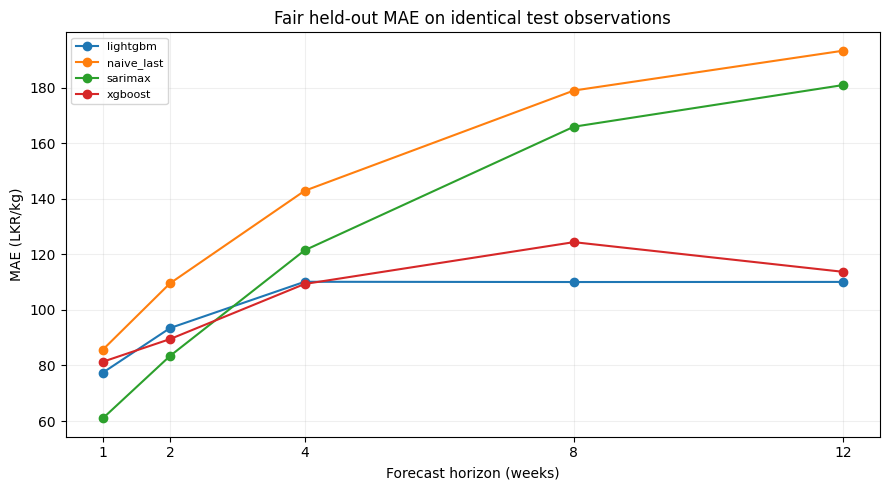

✅ FAIR BENCHMARK CELL COMPLETE


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("======================================================")
print("FAIR COMMON-KEY BENCHMARK")
print("======================================================")

pred = pd.read_csv(DRIVE / "01_from_notebook1" / "experiment_b" / "predictions.csv")
training = pd.read_parquet(DRIVE / "01_from_notebook1" / "panel" / "training_table.parquet")

for col in ["forecast_issue_week", "target_week"]:
    pred[col] = pd.to_datetime(pred[col], format="mixed", errors="raise").dt.normalize()
training["forecast_date"] = pd.to_datetime(training["forecast_date"], format="mixed", errors="raise").dt.normalize()

pred["horizon"] = pd.to_numeric(pred["horizon"], errors="raise").astype(int)
pred["model"] = pred["model"].astype(str).str.strip().str.lower()
pred["split"] = pred["split"].astype(str).str.strip().str.lower()

def normalize_text(series):
    return (
        series.astype(str).str.strip().str.lower()
        .str.replace(r"[\s\-]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
    )

pred["crop_key"] = normalize_text(pred["crop"])
pred["market_key"] = normalize_text(pred["market"])
training["crop_key"] = normalize_text(training["crop_id"])
training["market_key"] = normalize_text(training["market_id"])

expected_target = pred["forecast_issue_week"] + pd.to_timedelta(pred["horizon"] * 7, unit="D")
if not expected_target.eq(pred["target_week"]).all():
    bad = pred.loc[~expected_target.eq(pred["target_week"]),
                   ["model","crop","market","forecast_issue_week","target_week","horizon"]].head(20)
    print(bad.to_string(index=False))
    raise SystemExit("Prediction dates are not temporally comparable.")
print("PASS temporal key relationship")

KEY = ["crop_key", "market_key", "forecast_issue_week", "target_week", "horizon"]
CORE_MODELS = ["lightgbm", "xgboost", "sarimax"]

def point_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    return {
        "n_scored": int(len(y_true)),
        "mae": round(float(np.mean(np.abs(err))), 2),
        "rmse": round(float(np.sqrt(np.mean(err ** 2))), 2),
        "mape": round(float(np.mean(np.abs(err) / np.clip(y_true, 1e-6, None)) * 100), 2),
    }

test = pred[pred["split"].eq("test")].copy()
if not set(test["forecast_issue_week"].dt.year.unique()).issubset({2024, 2025}):
    raise SystemExit("Test rows include issue years outside 2024-2025.")

rows, seasonal_rows, key_counts, common_key_records = [], [], [], []

for horizon in sorted(test["horizon"].unique()):
    print(f"\nHORIZON {horizon}")
    h = test[test["horizon"].eq(horizon)].copy()
    key_sets = {}
    for model in CORE_MODELS:
        part = h[h["model"].eq(model)].copy()
        if part.duplicated(KEY).any():
            raise SystemExit(f"Duplicate prediction keys for {model}, h={horizon}")
        keys = set(map(tuple, part[KEY].itertuples(index=False, name=None)))
        key_sets[model] = keys
        print(f"{model:10s} raw keys = {len(keys)}")

    print("pairwise overlaps",
          len(key_sets["lightgbm"] & key_sets["xgboost"]),
          len(key_sets["lightgbm"] & key_sets["sarimax"]),
          len(key_sets["xgboost"] & key_sets["sarimax"]))

    common = key_sets["lightgbm"] & key_sets["xgboost"] & key_sets["sarimax"]
    if not common:
        for model in CORE_MODELS:
            print(model, list(key_sets[model])[:5])
        raise SystemExit(f"No common normalized test keys at horizon {horizon}")

    common_df = pd.DataFrame(list(common), columns=KEY).sort_values(KEY).reset_index(drop=True)
    common_key_records.append(common_df.copy())
    key_counts.append({
        "horizon": horizon,
        "lightgbm_keys": len(key_sets["lightgbm"]),
        "xgboost_keys": len(key_sets["xgboost"]),
        "sarimax_keys": len(key_sets["sarimax"]),
        "common_keys": len(common),
    })
    print("COMMON keys =", len(common))

    for model in CORE_MODELS:
        part = h[h["model"].eq(model)].merge(common_df, on=KEY, how="inner")
        rows.append({"model": model, "horizon": horizon, **point_metrics(part["y_true"], part["y_pred"])})

    truth = h[h["model"].eq("lightgbm")].merge(common_df, on=KEY, how="inner").copy()
    truth["forecast_date"] = truth["forecast_issue_week"]

    ref = training[training["forecast_horizon_weeks"].eq(horizon)][
        ["crop_key","market_key","forecast_date","last_observed_price_lkr_kg","price_lag_52w"]
    ].drop_duplicates(["crop_key","market_key","forecast_date"])

    base = truth.merge(ref, on=["crop_key","market_key","forecast_date"], how="left")
    if base["last_observed_price_lkr_kg"].isna().any():
        raise SystemExit(f"Last-value baseline missing on common keys at h={horizon}")

    rows.append({
        "model": "naive_last",
        "horizon": horizon,
        **point_metrics(base["y_true"], base["last_observed_price_lkr_kg"]),
    })

    seasonal = base.dropna(subset=["price_lag_52w"]).copy()
    if len(seasonal):
        seasonal_rows.append({
            "model": "seasonal_naive_52",
            "horizon": horizon,
            **point_metrics(seasonal["y_true"], seasonal["price_lag_52w"]),
        })

benchmark = pd.DataFrame(rows).sort_values(["horizon","mae","model"]).reset_index(drop=True)
seasonal_benchmark = pd.DataFrame(seasonal_rows)
counts = pd.DataFrame(key_counts)

core_check = benchmark[benchmark["model"].isin(CORE_MODELS + ["naive_last"])].pivot(
    index="horizon", columns="model", values="n_scored"
)
print("\nIDENTICAL-KEY COUNT CHECK")
print(core_check.to_string())
assert core_check.nunique(axis=1).eq(1).all()
print("PASS: LightGBM, XGBoost, SARIMAX and last-value naive use identical held-out keys.")

print("\nFAIR COMMON-KEY BENCHMARK")
print(benchmark.to_string(index=False))
print("\nSEASONAL NAIVE — rows with a real 52-week lag")
print(seasonal_benchmark.to_string(index=False) if not seasonal_benchmark.empty else "No valid rows")

best = (
    benchmark[benchmark["model"].isin(CORE_MODELS)]
    .sort_values(["horizon","mae"])
    .groupby("horizon", as_index=False)
    .first()[["horizon","model","mae","rmse","mape","n_scored"]]
)
print("\nBEST FITTED MODEL BY HORIZON")
print(best.to_string(index=False))

out = DRIVE / "01_from_notebook1" / "evaluation"
benchmark.to_csv(out / "common_key_benchmark.csv", index=False)
seasonal_benchmark.to_csv(out / "seasonal_naive_benchmark.csv", index=False)
counts.to_csv(out / "common_key_counts.csv", index=False)
pd.concat(common_key_records, ignore_index=True).drop_duplicates().to_csv(out / "common_test_keys.csv", index=False)
best.to_csv(out / "best_model_by_horizon.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for model, part in benchmark.groupby("model"):
    part = part.sort_values("horizon")
    ax.plot(part["horizon"], part["mae"], marker="o", label=model)
ax.set_title("Fair held-out MAE on identical test observations")
ax.set_xlabel("Forecast horizon (weeks)")
ax.set_ylabel("MAE (LKR/kg)")
ax.set_xticks(sorted(benchmark["horizon"].unique()))
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "common_key_benchmark_mae.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ FAIR BENCHMARK CELL COMPLETE")


## Cell 17 — Read the viva tables from this run

This cell does not fit anything. It reads the saved held-out results from Experiment B and, when C has been trained, also prints the empirical B* versus C novelty table.

Remember:
- headline A/B scoring is on 2024–2025 observed prices,
- Experiment C uses the exact real-progress common sample,
- a negative `mae_change_pct` means C reduced MAE versus B*,
- a positive value means C was worse at that horizon,
- uncertainty coverage must be reported empirically rather than described as guaranteed 90%.


FINAL HELD-OUT RESULTS — THIS COLAB RUN
Test issue years: 2024-2025
Hyperparameters: FIXED DEFAULTS
Optuna used in this run: NO
Experiment C trained: YES

HEADLINE FAIR BENCHMARK — IDENTICAL TEST KEYS
     model  horizon  n_scored    mae   rmse   mape
   sarimax        1      1200  60.96 107.81  22.94
  lightgbm        1      1200  77.40 131.42  29.19
   xgboost        1      1200  81.33 136.60  30.97
naive_last        1      1200  85.68 142.22  32.78
   sarimax        2      1188  83.45 139.32  32.44
   xgboost        2      1188  89.51 157.25  32.45
  lightgbm        2      1188  93.48 161.57  32.46
naive_last        2      1188 109.60 180.17  42.69
   xgboost        4      1164 109.35 172.32  44.36
  lightgbm        4      1164 110.14 172.73  43.96
   sarimax        4      1164 121.48 188.44  51.80
naive_last        4      1164 142.91 217.10  64.65
  lightgbm        8      1116 110.05 163.22  54.53
   xgboost        8      1116 124.41 178.48  65.51
   sarimax        8      1116 165.

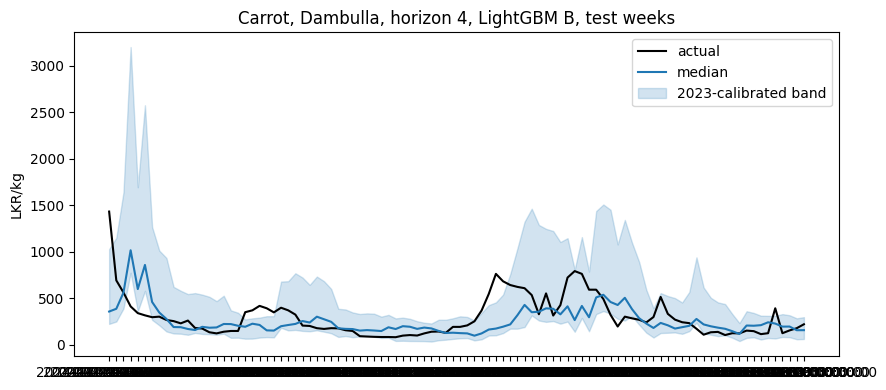

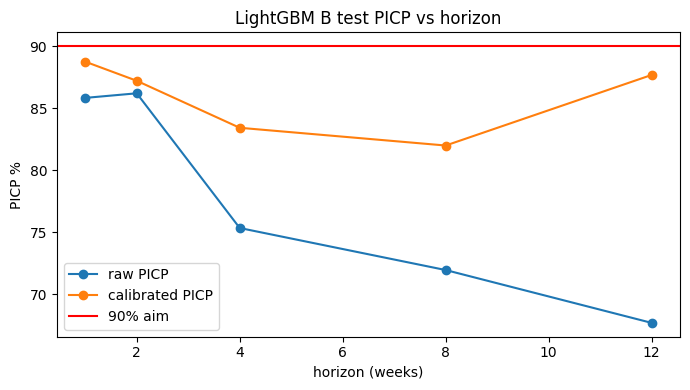

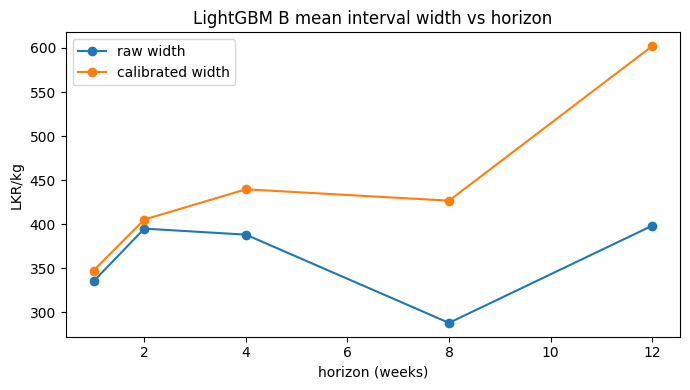

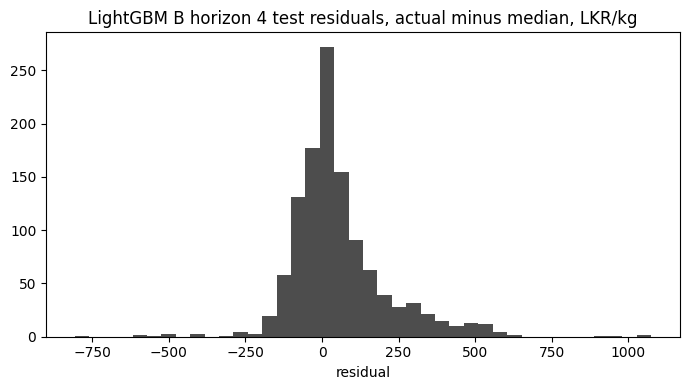

SUMMARY read from metrics_with_cqr.csv
LightGBM B horizon 4 test MAE 110.14 RMSE 172.73 MAPE 43.96
pinball 55.07 raw PICP 75.34 calibrated PICP 83.42 raw width 387.99 calibrated width 439.5 qhat 25.5959
n_scored 1164
coverage_level aim is 0.9. The measured coverage is the calibrated PICP printed above, not a number from the earlier laptop run.

EXPERIMENT C — REAL NOVELTY TEST
   model  horizon  n_scored_b_star  mae_b_star  rmse_b_star  mape_b_star  pinball_q05_b_star  pinball_q50_b_star  pinball_q95_b_star  pinball_mean_3q_b_star  picp_raw_b_star  interval_width_raw_b_star  raw_quantile_crossing_count_b_star  raw_quantile_crossing_rate_pct_b_star  reported_interval_order_violation_count_b_star  qhat_b_star  picp_cqr_b_star  interval_width_cqr_b_star  n_scored_c  mae_c  rmse_c  mape_c  pinball_q05_c  pinball_q50_c  pinball_q95_c  pinball_mean_3q_c  picp_raw_c  interval_width_raw_c  raw_quantile_crossing_count_c  raw_quantile_crossing_rate_pct_c  reported_interval_order_violation_count_

In [25]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 72)
print("FINAL HELD-OUT RESULTS — THIS COLAB RUN")
print("Test issue years: 2024-2025")
print("Hyperparameters: FIXED DEFAULTS")
print("Optuna used in this run: NO")
c_status_path = DRIVE / "01_from_notebook1" / "experiment_c" / "status.json"
c_status = json.loads(c_status_path.read_text()) if c_status_path.is_file() else {"experiment_c_trained": False, "status": "missing"}
print("Experiment C trained:", "YES" if c_status.get("experiment_c_trained") else "NO")
print("=" * 72)

common_bench_path = DRIVE / "01_from_notebook1" / "evaluation" / "common_key_benchmark.csv"
if common_bench_path.is_file():
    print("\nHEADLINE FAIR BENCHMARK — IDENTICAL TEST KEYS")
    print(pd.read_csv(common_bench_path).to_string(index=False))
    print("\nThe uncertainty tables below use each quantile model's complete held-out prediction set.")

pred_path = DRIVE / "01_from_notebook1" / "experiment_b" / "predictions.csv"
metric_path = DRIVE / "01_from_notebook1" / "experiment_b" / "metrics_with_cqr.csv"
compare_path = DRIVE / "01_from_notebook1" / "experiment_b" / "a_vs_b.csv"
cqr = json.loads((DRIVE / "01_from_notebook1" / "experiment_b" / "cqr.json").read_text())
predictions = pd.read_csv(pred_path, parse_dates=["forecast_issue_week", "target_week"])
metrics = pd.read_csv(metric_path)
compared = pd.read_csv(compare_path)
test = predictions[predictions["split"].eq("test")].copy()

def pooled(frame):
    y_true = frame["y_true"].to_numpy(dtype=float)
    y_pred = frame["y_pred"].to_numpy(dtype=float)
    low = frame["y_pred_q05"].to_numpy(dtype=float)
    high = frame["y_pred_q95"].to_numpy(dtype=float)
    error = y_pred - y_true
    residual = y_true - y_pred
    finite = np.isfinite(low) & np.isfinite(high)
    return {
        "n_scored": int(len(frame)),
        "mae": round(float(np.mean(np.abs(error))), 2),
        "rmse": round(float(np.sqrt(np.mean(error ** 2))), 2),
        "mape": round(float(np.mean(np.abs(error) / np.clip(y_true, 1e-6, None)) * 100), 2),
        "pinball": round(float(np.mean(np.where(residual >= 0, 0.5 * residual, -0.5 * residual))), 2) if finite.any() else None,
        "picp_raw": round(float(np.mean((y_true[finite] >= low[finite]) & (y_true[finite] <= high[finite])) * 100), 2) if finite.any() else None,
        "mean_width_raw": round(float(np.mean(high[finite] - low[finite])), 2) if finite.any() else None,
    }

overall_rows = []
for model, group in test.groupby("model"):
    row = {"model": model, "slice": "test_pooled_horizons", **pooled(group)}
    if model in cqr["qhat_by_model"]:
        parts = []
        for horizon, part in group.groupby("horizon"):
            qhat = float(cqr["qhat_by_model"][model][str(int(horizon))])
            shifted = part.copy()
            shifted["y_pred_q05"] = shifted["y_pred_q05"] - qhat
            shifted["y_pred_q95"] = shifted["y_pred_q95"] + qhat
            parts.append(shifted)
        calibrated = pd.concat(parts, ignore_index=True)
        cal = pooled(calibrated)
        row["picp_cqr"] = cal["picp_raw"]
        row["mean_width_cqr"] = cal["mean_width_raw"]
    overall_rows.append(row)
overall = pd.DataFrame(overall_rows)
print("OVERALL from the saved prediction file, pooled over horizons")
print(overall.to_string(index=False))
print("BY HORIZON from metrics_with_cqr.csv")
show = metrics[metrics["slice"].eq("test")][["model", "horizon", "n_scored", "mae", "rmse", "mape", "pinball", "picp", "interval_width", "picp_cqr", "interval_width_cqr", "qhat"]]
print(show.to_string(index=False))

lgb4 = test[test["model"].eq("lightgbm") & test["horizon"].eq(4) & test["feature_set"].eq("B")]

def grouped_metrics(frame, key):
    rows = []
    for name, part in frame.groupby(key):
        rows.append({key: name, **pooled(part)})
    return pd.DataFrame(rows)

by_crop = grouped_metrics(lgb4, "crop")
by_market = grouped_metrics(lgb4, "market")
print("LightGBM B, horizon 4, by crop")
print(by_crop.to_string(index=False))
print("LightGBM B, horizon 4, by market")
print(by_market.to_string(index=False))
shock = test[test["is_shock"].astype(bool)]
shock_rows = []
for model, group in shock.groupby("model"):
    shock_rows.append({"model": model, "slice": "shock_2024q1_pooled", **pooled(group)})
print("SHOCK slice, issue weeks 2024-01-01 to 2024-03-31")
print(pd.DataFrame(shock_rows).to_string(index=False))
print("A TO B from a_vs_b.csv")
print(compared[["model", "horizon", "mae_a", "mae_b", "mae_change_pct", "picp_a", "picp_b", "picp_cqr_a", "picp_cqr_b"]].to_string(index=False))

qhat4 = float(cqr["qhat_by_model"]["lightgbm"]["4"])
series = lgb4[lgb4["crop"].eq("carrot") & lgb4["market"].eq("Dambulla")].sort_values("target_week")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(series["target_week"], series["y_true"], color="black", label="actual")
ax.plot(series["target_week"], series["y_pred"], color="tab:blue", label="median")
ax.fill_between(series["target_week"], series["y_pred_q05"] - qhat4, series["y_pred_q95"] + qhat4, color="tab:blue", alpha=0.2, label="2023-calibrated band")
ax.set_title("Carrot, Dambulla, horizon 4, LightGBM B, test weeks")
ax.set_ylabel("LKR/kg")
ax.legend()
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "carrot_dambulla_h4_band.png", dpi=120)
plt.show()

lgb_metrics = show[show["model"].eq("lightgbm")].sort_values("horizon")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lgb_metrics["horizon"], lgb_metrics["picp"], marker="o", label="raw PICP")
ax.plot(lgb_metrics["horizon"], lgb_metrics["picp_cqr"], marker="o", label="calibrated PICP")
ax.axhline(90, color="red", label="90% aim")
ax.set_title("LightGBM B test PICP vs horizon")
ax.set_xlabel("horizon (weeks)")
ax.set_ylabel("PICP %")
ax.legend()
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "picp_vs_horizon.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lgb_metrics["horizon"], lgb_metrics["interval_width"], marker="o", label="raw width")
ax.plot(lgb_metrics["horizon"], lgb_metrics["interval_width_cqr"], marker="o", label="calibrated width")
ax.set_title("LightGBM B mean interval width vs horizon")
ax.set_xlabel("horizon (weeks)")
ax.set_ylabel("LKR/kg")
ax.legend()
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "width_vs_horizon.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lgb4["y_true"] - lgb4["y_pred"], bins=40, color="0.3")
ax.set_title("LightGBM B horizon 4 test residuals, actual minus median, LKR/kg")
ax.set_xlabel("residual")
fig.tight_layout()
fig.savefig(DRIVE / "01_from_notebook1" / "plots" / "h4_residuals.png", dpi=120)
plt.show()

h4 = lgb_metrics[lgb_metrics["horizon"].eq(4)].iloc[0]
print("SUMMARY read from metrics_with_cqr.csv")
print(f"LightGBM B horizon 4 test MAE {h4['mae']} RMSE {h4['rmse']} MAPE {h4['mape']}")
print(f"pinball {h4['pinball']} raw PICP {h4['picp']} calibrated PICP {h4['picp_cqr']} raw width {h4['interval_width']} calibrated width {h4['interval_width_cqr']} qhat {h4['qhat']}")
print(f"n_scored {int(h4['n_scored'])}")
print("coverage_level aim is 0.9. The measured coverage is the calibrated PICP printed above, not a number from the earlier laptop run.")
if c_status.get("experiment_c_trained"):
    c_comp_path = DRIVE / "01_from_notebook1" / "experiment_c" / "b_star_vs_c.csv"
    print("\nEXPERIMENT C — REAL NOVELTY TEST")
    c_comp = pd.read_csv(c_comp_path)
    print(c_comp.to_string(index=False))
    print("Interpretation: negative mae_change_pct means C reduced error versus B* on identical rows.")
else:
    print("EXPERIMENT C NOT RUN:", c_status.get("status"))

eval_dir = DRIVE / "01_from_notebook1" / "evaluation"
overall.to_csv(eval_dir / "overall_pooled.csv", index=False)
by_crop.to_csv(eval_dir / "lightgbm_b_h4_by_crop.csv", index=False)
by_market.to_csv(eval_dir / "lightgbm_b_h4_by_market.csv", index=False)
pd.DataFrame(shock_rows).to_csv(eval_dir / "shock_pooled.csv", index=False)
show.to_csv(eval_dir / "metrics_test_by_horizon.csv", index=False)
print("saved", eval_dir)

c_status_path = DRIVE / "01_from_notebook1" / "experiment_c" / "status.json"
if c_status_path.is_file():
    c_status_final = json.loads(c_status_path.read_text())
    print("\nEXPERIMENT C LIMITS")
    print("- Scored C spatial scope: national")
    print("- 2023 national reports: 15 April and 15 May only")
    print("- 2019 national report: 15 December only")
    print("- District rows are not used in scored C")
    print("- Weeks with no valid exact-season national report are excluded")
    print("- No arbitrary report-age cutoff is used; latest known report persists only inside its exact season")


## Cell 18 — Final forecasting benchmark and model selection

This section keeps the approved research design and adds only supplementary forecasting diagnostics.

The task is continuous weekly price forecasting, so no classification accuracy is reported.

Primary point metrics:
- MAE
- RMSE
- MAPE
- sMAPE
- WAPE
- mean bias
- supplementary R²

Additional best-practice checks:
- persistence-naive benchmark;
- seasonal-naive (52-week) benchmark on the exact rows where a real 52-week lag exists;
- MASE using a 52-week seasonal scale estimated only from the pre-2023 training history;
- MAE skill versus persistence;
- paired moving-block bootstrap uncertainty for each fitted model versus persistence.

The best fitted point model is reported by horizon. This does not replace the LightGBM C research model used for the cultivation-progress novelty experiment.


FINAL HELD-OUT POINT-FORECAST BENCHMARK
     model  horizon  n_scored      mae     rmse     mape   smape    wape  mean_bias      r2  mase_52w  mae_skill_vs_naive_pct
   sarimax        1      1200  60.9553 107.8068  22.9384 21.7649 22.7646     2.2262  0.7198    0.8136                 28.8535
  lightgbm        1      1200  77.4046 131.4168  29.1950 27.9641 28.9078   -13.3349  0.5836    1.0309                  9.6540
   xgboost        1      1200  81.3255 136.6006  30.9677 29.0445 30.3722    -3.9164  0.5501    1.0845                  5.0776
naive_last        1      1200  85.6758 142.2248  32.7750 30.2243 31.9968     2.2746  0.5123    1.1427                  0.0000
   sarimax        2      1188  83.4489 139.3201  32.4427 29.7071 31.4303     3.0231  0.5226    1.1131                 23.8604
   xgboost        2      1188  89.5078 157.2468  32.4545 32.2287 33.7124   -37.4528  0.3918    1.1916                 18.3322
  lightgbm        2      1188  93.4800 161.5656  32.4565 33.9093 35.2085   -55

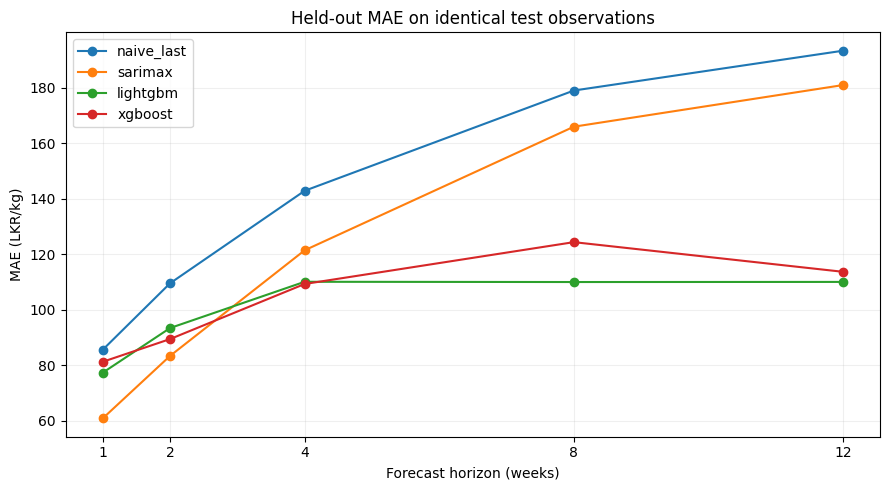

saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/final_point_forecast_benchmark.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/best_point_model_by_horizon.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/seasonal_naive_common_subset.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/mase_scale_52w_by_series.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/model_vs_naive_block_bootstrap.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/final_model_benchmark_mae.png


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EVAL_DIR = DRIVE / "01_from_notebook1" / "evaluation"
PLOT_DIR = DRIVE / "01_from_notebook1" / "plots"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

pred = pd.read_csv(
    DRIVE / "01_from_notebook1" / "experiment_b" / "predictions.csv"
)

training = pd.read_parquet(
    DRIVE / "01_from_notebook1" / "panel" / "training_table.parquet"
)

panel = pd.read_parquet(
    DRIVE / "01_from_notebook1" / "panel" / "analysis_ready_panel.parquet"
)

for col in ["forecast_issue_week", "target_week"]:
    pred[col] = pd.to_datetime(
        pred[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

training["forecast_date"] = pd.to_datetime(
    training["forecast_date"],
    format="mixed",
    errors="raise",
).dt.normalize()

panel["week_start"] = pd.to_datetime(
    panel["week_start"],
    format="mixed",
    errors="raise",
).dt.normalize()

pred["horizon"] = pd.to_numeric(
    pred["horizon"],
    errors="raise",
).astype(int)

pred["model"] = (
    pred["model"]
    .astype(str)
    .str.strip()
    .str.lower()
)

pred["split"] = (
    pred["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

def normalize_key(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[\s\-]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
    )

pred["crop_key"] = normalize_key(pred["crop"])
pred["market_key"] = normalize_key(pred["market"])
training["crop_key"] = normalize_key(training["crop_id"])
training["market_key"] = normalize_key(training["market_id"])
panel["crop_key"] = normalize_key(panel["crop"])
panel["market_key"] = normalize_key(panel["market"])

KEY = [
    "crop_key",
    "market_key",
    "forecast_issue_week",
    "target_week",
    "horizon",
]

CORE_MODELS = [
    "lightgbm",
    "xgboost",
    "sarimax",
]

def extended_point_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    error = y_pred - y_true
    abs_error = np.abs(error)

    mae = float(np.mean(abs_error))
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mape = float(
        np.mean(
            abs_error
            / np.clip(np.abs(y_true), 1e-6, None)
        )
        * 100
    )

    denominator = np.abs(y_true) + np.abs(y_pred)

    smape = float(
        np.mean(
            2 * abs_error
            / np.clip(denominator, 1e-6, None)
        )
        * 100
    )

    wape = float(
        np.sum(abs_error)
        / np.clip(np.sum(np.abs(y_true)), 1e-6, None)
        * 100
    )

    mean_bias = float(np.mean(error))

    sst = float(
        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )
    )

    r2 = (
        float(
            1
            - np.sum(error ** 2) / sst
        )
        if sst > 0
        else np.nan
    )

    return {
        "n_scored": int(len(y_true)),
        "mae": mae,
        "rmse": rmse,
        "mape": mape,
        "smape": smape,
        "wape": wape,
        "mean_bias": mean_bias,
        "r2": r2,
    }

# ============================================================
# Seasonal MASE scale estimated only from pre-2023 history.
# ============================================================

panel = panel.sort_values(
    ["crop_key", "market_key", "week_start"]
).copy()

panel["observed_price"] = pd.to_numeric(
    panel["price"],
    errors="coerce",
).where(
    panel["is_observed"].astype(bool)
)

panel["seasonal_lag_52_train"] = (
    panel.groupby(
        ["crop_key", "market_key"],
        sort=False,
    )["observed_price"]
    .shift(52)
)

scale_source = panel[
    panel["week_start"].le(
        pd.Timestamp("2022-12-31")
    )
    & panel["observed_price"].notna()
    & panel["seasonal_lag_52_train"].notna()
].copy()

scale_source["seasonal_abs_difference"] = np.abs(
    scale_source["observed_price"]
    - scale_source["seasonal_lag_52_train"]
)

mase_scale = (
    scale_source.groupby(
        ["crop_key", "market_key"],
        as_index=False,
    )["seasonal_abs_difference"]
    .mean()
    .rename(
        columns={
            "seasonal_abs_difference": "mase_scale_52w"
        }
    )
)

if (
    mase_scale["mase_scale_52w"].isna().any()
    or mase_scale["mase_scale_52w"].le(0).any()
):
    raise SystemExit(
        "Invalid 52-week MASE scale. Inspect the pre-2023 price history."
    )

mase_scale.to_csv(
    EVAL_DIR / "mase_scale_52w_by_series.csv",
    index=False,
)

# ============================================================
# Held-out test only.
# ============================================================

test = pred[
    pred["split"].eq("test")
].copy()

if not set(
    test["forecast_issue_week"].dt.year.unique()
).issubset({2024, 2025}):
    raise SystemExit(
        "Held-out rows contain issue years outside 2024-2025."
    )

rows = []
seasonal_subset_rows = []
bootstrap_rows = []

def moving_block_mean_ci(
    values,
    block_length=4,
    reps=2000,
    seed=42,
):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    n = len(values)

    if n == 0:
        return np.nan, np.nan

    block_length = int(
        max(
            1,
            min(block_length, n),
        )
    )

    blocks_needed = int(
        np.ceil(n / block_length)
    )

    rng = np.random.default_rng(seed)
    means = np.empty(reps, dtype=float)

    for rep in range(reps):
        starts = rng.integers(
            0,
            n,
            size=blocks_needed,
        )

        idx = []

        for start in starts:
            idx.extend(
                (
                    start
                    + np.arange(block_length)
                )
                % n
            )

        idx = np.asarray(
            idx[:n],
            dtype=int,
        )

        means[rep] = float(
            np.mean(values[idx])
        )

    return (
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975)),
    )

for horizon in sorted(
    test["horizon"].unique()
):
    h = test[
        test["horizon"].eq(horizon)
    ].copy()

    key_sets = {}

    for model in CORE_MODELS:
        part = h[
            h["model"].eq(model)
        ].copy()

        if part.duplicated(KEY).any():
            raise SystemExit(
                f"Duplicate test keys for {model}, h={horizon}."
            )

        key_sets[model] = set(
            map(
                tuple,
                part[KEY].itertuples(
                    index=False,
                    name=None,
                ),
            )
        )

    common = (
        key_sets["lightgbm"]
        & key_sets["xgboost"]
        & key_sets["sarimax"]
    )

    if not common:
        raise SystemExit(
            f"No common held-out keys at horizon {horizon}."
        )

    common_df = pd.DataFrame(
        list(common),
        columns=KEY,
    )

    truth = (
        h[
            h["model"].eq("lightgbm")
        ]
        .merge(
            common_df,
            on=KEY,
            how="inner",
        )
        .copy()
    )

    truth["forecast_date"] = (
        truth["forecast_issue_week"]
    )

    reference = (
        training[
            training[
                "forecast_horizon_weeks"
            ].eq(horizon)
        ][
            [
                "crop_key",
                "market_key",
                "forecast_date",
                "last_observed_price_lkr_kg",
                "price_lag_52w",
            ]
        ]
        .drop_duplicates(
            [
                "crop_key",
                "market_key",
                "forecast_date",
            ]
        )
    )

    baseline = truth.merge(
        reference,
        on=[
            "crop_key",
            "market_key",
            "forecast_date",
        ],
        how="left",
        validate="many_to_one",
    ).merge(
        mase_scale,
        on=[
            "crop_key",
            "market_key",
        ],
        how="left",
        validate="many_to_one",
    )

    if baseline[
        "last_observed_price_lkr_kg"
    ].isna().any():
        raise SystemExit(
            f"Persistence baseline is incomplete at h={horizon}."
        )

    if baseline[
        "mase_scale_52w"
    ].isna().any():
        raise SystemExit(
            f"MASE scale is incomplete on common keys at h={horizon}."
        )

    model_parts = {}

    for model in CORE_MODELS:
        part = (
            h[
                h["model"].eq(model)
            ]
            .merge(
                common_df,
                on=KEY,
                how="inner",
            )
            .merge(
                mase_scale,
                on=[
                    "crop_key",
                    "market_key",
                ],
                how="left",
                validate="many_to_one",
            )
        )

        model_parts[model] = part.copy()

        metrics = extended_point_metrics(
            part["y_true"],
            part["y_pred"],
        )

        mase = float(
            np.mean(
                np.abs(
                    part["y_pred"]
                    - part["y_true"]
                )
                / part["mase_scale_52w"]
            )
        )

        rows.append(
            {
                "model": model,
                "horizon": int(horizon),
                **metrics,
                "mase_52w": mase,
            }
        )

    naive_metrics = extended_point_metrics(
        baseline["y_true"],
        baseline[
            "last_observed_price_lkr_kg"
        ],
    )

    naive_mase = float(
        np.mean(
            np.abs(
                baseline[
                    "last_observed_price_lkr_kg"
                ]
                - baseline["y_true"]
            )
            / baseline["mase_scale_52w"]
        )
    )

    rows.append(
        {
            "model": "naive_last",
            "horizon": int(horizon),
            **naive_metrics,
            "mase_52w": naive_mase,
        }
    )

    # --------------------------------------------------------
    # Seasonal-naive comparison on identical seasonal-eligible rows.
    # --------------------------------------------------------

    seasonal_truth = baseline[
        baseline["price_lag_52w"].notna()
    ].copy()

    seasonal_keys = seasonal_truth[
        KEY
    ].drop_duplicates()

    if len(seasonal_truth):
        seasonal_metrics = extended_point_metrics(
            seasonal_truth["y_true"],
            seasonal_truth["price_lag_52w"],
        )

        seasonal_mase = float(
            np.mean(
                np.abs(
                    seasonal_truth["price_lag_52w"]
                    - seasonal_truth["y_true"]
                )
                / seasonal_truth["mase_scale_52w"]
            )
        )

        seasonal_subset_rows.append(
            {
                "model": "seasonal_naive_52",
                "horizon": int(horizon),
                **seasonal_metrics,
                "mase_52w": seasonal_mase,
                "seasonal_eligible_share_pct": (
                    len(seasonal_truth)
                    / len(baseline)
                    * 100
                ),
            }
        )

        for model in CORE_MODELS:
            part = (
                h[
                    h["model"].eq(model)
                ]
                .merge(
                    seasonal_keys,
                    on=KEY,
                    how="inner",
                )
                .merge(
                    mase_scale,
                    on=[
                        "crop_key",
                        "market_key",
                    ],
                    how="left",
                    validate="many_to_one",
                )
            )

            metrics = extended_point_metrics(
                part["y_true"],
                part["y_pred"],
            )

            model_mase = float(
                np.mean(
                    np.abs(
                        part["y_pred"]
                        - part["y_true"]
                    )
                    / part["mase_scale_52w"]
                )
            )

            seasonal_subset_rows.append(
                {
                    "model": model,
                    "horizon": int(horizon),
                    **metrics,
                    "mase_52w": model_mase,
                    "seasonal_eligible_share_pct": (
                        len(part)
                        / len(baseline)
                        * 100
                    ),
                }
            )

    # --------------------------------------------------------
    # Paired model-vs-persistence uncertainty.
    # Weekly aggregation reduces repeated same-week dependence.
    # Negative mean difference favors the fitted model.
    # --------------------------------------------------------

    naive_for_pair = baseline[
        KEY + [
            "y_true",
            "last_observed_price_lkr_kg",
        ]
    ].copy()

    naive_for_pair[
        "ae_naive"
    ] = np.abs(
        naive_for_pair[
            "last_observed_price_lkr_kg"
        ]
        - naive_for_pair["y_true"]
    )

    for model in CORE_MODELS:
        part = model_parts[model][
            KEY + [
                "y_true",
                "y_pred",
            ]
        ].copy()

        paired = part.merge(
            naive_for_pair[
                KEY + ["ae_naive"]
            ],
            on=KEY,
            how="inner",
            validate="one_to_one",
        )

        paired["ae_model"] = np.abs(
            paired["y_pred"]
            - paired["y_true"]
        )

        paired[
            "ae_difference_model_minus_naive"
        ] = (
            paired["ae_model"]
            - paired["ae_naive"]
        )

        weekly = (
            paired.groupby(
                "target_week",
                as_index=False,
            )[
                "ae_difference_model_minus_naive"
            ]
            .mean()
            .sort_values("target_week")
        )

        ci_low, ci_high = moving_block_mean_ci(
            weekly[
                "ae_difference_model_minus_naive"
            ],
            block_length=4,
            reps=2000,
            seed=1000
            + int(horizon)
            + CORE_MODELS.index(model) * 100,
        )

        mean_diff = float(
            paired[
                "ae_difference_model_minus_naive"
            ].mean()
        )

        bootstrap_rows.append(
            {
                "model": model,
                "horizon": int(horizon),
                "n_matched_rows": int(
                    len(paired)
                ),
                "n_target_weeks": int(
                    len(weekly)
                ),
                "mean_mae_difference_model_minus_naive": mean_diff,
                "bootstrap_95_ci_low": ci_low,
                "bootstrap_95_ci_high": ci_high,
                "ci_entirely_below_zero": bool(
                    ci_high < 0
                ),
                "ci_entirely_above_zero": bool(
                    ci_low > 0
                ),
            }
        )

benchmark = pd.DataFrame(rows)

naive_mae = (
    benchmark[
        benchmark["model"].eq("naive_last")
    ][
        ["horizon", "mae"]
    ]
    .rename(
        columns={
            "mae": "naive_mae",
        }
    )
)

benchmark = benchmark.merge(
    naive_mae,
    on="horizon",
    how="left",
    validate="many_to_one",
)

benchmark["mae_skill_vs_naive_pct"] = (
    1
    - benchmark["mae"]
    / benchmark["naive_mae"]
) * 100

benchmark = (
    benchmark.drop(
        columns=["naive_mae"]
    )
    .sort_values(
        ["horizon", "mae", "model"]
    )
    .reset_index(drop=True)
)

seasonal_subset = (
    pd.DataFrame(
        seasonal_subset_rows
    )
    .sort_values(
        ["horizon", "mae", "model"]
    )
    .reset_index(drop=True)
)

model_vs_naive_bootstrap = (
    pd.DataFrame(
        bootstrap_rows
    )
    .sort_values(
        ["horizon", "model"]
    )
    .reset_index(drop=True)
)

best_point = (
    benchmark[
        benchmark["model"].isin(
            CORE_MODELS
        )
    ]
    .sort_values(
        [
            "horizon",
            "mae",
            "rmse",
            "model",
        ]
    )
    .groupby(
        "horizon",
        as_index=False,
    )
    .first()
)

benchmark.to_csv(
    EVAL_DIR
    / "final_point_forecast_benchmark.csv",
    index=False,
)

best_point.to_csv(
    EVAL_DIR
    / "best_point_model_by_horizon.csv",
    index=False,
)

seasonal_subset.to_csv(
    EVAL_DIR
    / "seasonal_naive_common_subset.csv",
    index=False,
)

model_vs_naive_bootstrap.to_csv(
    EVAL_DIR
    / "model_vs_naive_block_bootstrap.csv",
    index=False,
)

print("FINAL HELD-OUT POINT-FORECAST BENCHMARK")
print(
    benchmark.round(4).to_string(
        index=False
    )
)

print("\nBEST POINT MODEL BY HORIZON")
print(
    best_point[
        [
            "horizon",
            "model",
            "n_scored",
            "mae",
            "rmse",
            "mape",
            "smape",
            "wape",
            "mase_52w",
            "mae_skill_vs_naive_pct",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print(
    "\nSEASONAL-NAIVE FAIR SUBSET"
)
print(
    seasonal_subset.round(4).to_string(
        index=False
    )
)

print(
    "\nPAIRED MODEL VS PERSISTENCE — MOVING-BLOCK BOOTSTRAP"
)
print(
    model_vs_naive_bootstrap.round(4).to_string(
        index=False
    )
)

print(
    "\nMASE uses a 52-week seasonal scale estimated only from "
    "pre-2023 observed price history."
)

models_to_plot = [
    "naive_last",
    "sarimax",
    "lightgbm",
    "xgboost",
]

plot_frame = benchmark[
    benchmark["model"].isin(
        models_to_plot
    )
].copy()

fig, ax = plt.subplots(
    figsize=(9, 5)
)

for model in models_to_plot:
    part = (
        plot_frame[
            plot_frame["model"].eq(model)
        ]
        .sort_values("horizon")
    )

    ax.plot(
        part["horizon"],
        part["mae"],
        marker="o",
        label=model,
    )

ax.set_title(
    "Held-out MAE on identical test observations"
)
ax.set_xlabel(
    "Forecast horizon (weeks)"
)
ax.set_ylabel(
    "MAE (LKR/kg)"
)
ax.set_xticks(
    sorted(
        benchmark["horizon"].unique()
    )
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()

benchmark_plot = (
    PLOT_DIR
    / "final_model_benchmark_mae.png"
)

fig.savefig(
    benchmark_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

print("saved", EVAL_DIR / "final_point_forecast_benchmark.csv")
print("saved", EVAL_DIR / "best_point_model_by_horizon.csv")
print("saved", EVAL_DIR / "seasonal_naive_common_subset.csv")
print("saved", EVAL_DIR / "mase_scale_52w_by_series.csv")
print("saved", EVAL_DIR / "model_vs_naive_block_bootstrap.csv")
print("saved", benchmark_plot)


## Cell 19 — Probabilistic quality, raw crossing audit, ordered intervals and conditional coverage

The approved uncertainty evaluation remains pinball loss, PICP and interval width. Raw independently trained quantile crossings are retained as an audit diagnostic. Before CQR, the reported interval is projected so that `lower <= q50 <= upper` while the q50 point forecast stays unchanged.

Conditional PICP, interval width and interval score are reported by crop, market, official cultivation-season family and year-quarter. No `unknown` season bucket is allowed.


EXPERIMENT C — PROBABILISTIC HELD-OUT EVALUATION
   model  horizon  n_scored    mae  pinball_mean_3q  median_pinball_q50  picp_cqr_pct  coverage_gap_from_90_pp  interval_width_cqr  interval_score_90
lightgbm        1       462  59.75           15.907             29.8767       85.7143                   4.2857            258.9308           356.3586
 xgboost        1       462  56.11           14.854             28.0542       82.9004                   7.0996            227.6262           339.0867
lightgbm        2       459  64.94           16.988             32.4691       91.2854                   1.2854            303.0173           369.8118
 xgboost        2       459  57.78           16.131             28.8876       89.7603                   0.2397            298.8621           385.9772
lightgbm        4       453  80.04           20.791             40.0186       91.1700                   1.1700            286.2896           430.0042
 xgboost        4       453  69.88           19.617

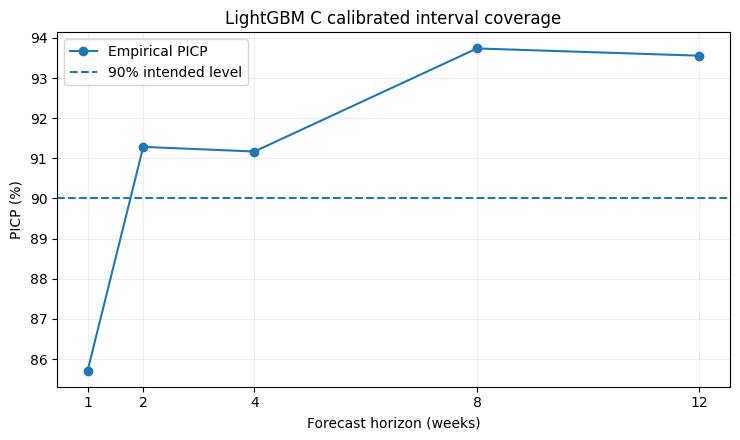

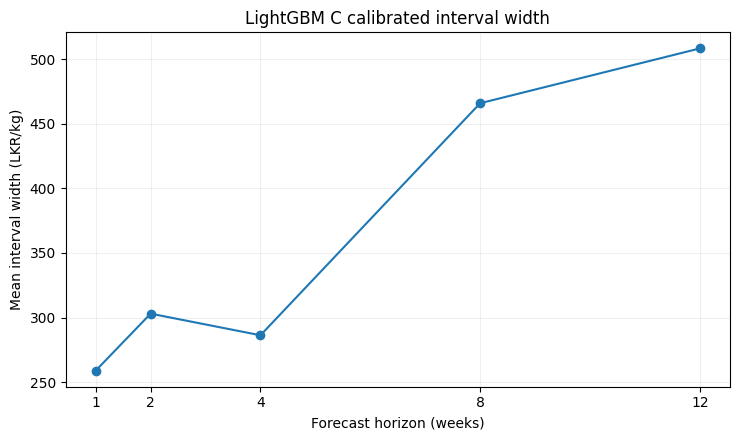

saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/final_probabilistic_evaluation_c.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/quantile_crossing_diagnostic_c.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/conditional_interval_evaluation_c.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/final_c_picp_by_horizon.png
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/final_c_interval_width_by_horizon.png


In [27]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

C_DIR = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
)

c_predictions = pd.read_csv(
    C_DIR / "predictions_c.csv"
)

c_eligible = pd.read_parquet(
    C_DIR / "c_eligible_table.parquet"
)

for frame in [
    c_predictions,
    c_eligible,
]:
    for col in [
        "forecast_issue_week",
        "target_week",
    ]:
        if col in frame.columns:
            frame[col] = pd.to_datetime(
                frame[col],
                format="mixed",
                errors="raise",
            ).dt.normalize()

c_cqr = json.loads(
    (C_DIR / "cqr.json").read_text()
)

saved_metrics = pd.read_csv(
    C_DIR / "metrics_c.csv"
)

def normalize_key(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[\s\-]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
    )

def interval_score_90(
    y,
    lower,
    upper,
):
    y = np.asarray(y, dtype=float)
    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)

    alpha = 0.10

    score = (
        upper - lower
        + (2 / alpha)
        * (lower - y)
        * (y < lower)
        + (2 / alpha)
        * (y - upper)
        * (y > upper)
    )

    return float(
        np.mean(score)
    )

def interval_group_summary(
    frame,
    group_column,
    group_label,
):
    rows = []

    for (
        model,
        horizon,
        group_value,
    ), part in frame.groupby(
        [
            "model",
            "horizon",
            group_column,
        ],
        dropna=False,
    ):
        if len(part) < 10:
            continue

        y = part[
            "y_true"
        ].to_numpy(
            dtype=float
        )

        lower = part[
            "lower_cqr"
        ].to_numpy(
            dtype=float
        )

        upper = part[
            "upper_cqr"
        ].to_numpy(
            dtype=float
        )

        coverage = float(
            np.mean(
                (y >= lower)
                & (y <= upper)
            )
            * 100
        )

        rows.append(
            {
                "dimension": group_label,
                "group": str(
                    group_value
                ),
                "model": str(model),
                "horizon": int(horizon),
                "n": int(len(part)),
                "picp_cqr_pct": coverage,
                "coverage_gap_from_90_pp": abs(
                    coverage - 90.0
                ),
                "interval_width_cqr": float(
                    np.mean(
                        upper - lower
                    )
                ),
                "interval_score_90": interval_score_90(
                    y,
                    lower,
                    upper,
                ),
            }
        )

    return rows

prob_rows = []
crossing_rows = []
scored_parts = []

for model in [
    "lightgbm",
    "xgboost",
]:
    model_rows = c_predictions[
        c_predictions["model"]
        .astype(str)
        .str.lower()
        .eq(model)
        & c_predictions["split"]
        .astype(str)
        .str.lower()
        .eq("test")
    ].copy()

    model_rows["model"] = model

    for horizon, part in model_rows.groupby(
        "horizon"
    ):
        horizon = int(horizon)
        part = part.copy()

        qhat = float(
            c_cqr[
                "qhat_by_model"
            ][model][str(horizon)]
        )

        raw_q05 = part[
            "y_pred_q05"
        ].to_numpy(
            dtype=float
        )

        q50 = part[
            "y_pred"
        ].to_numpy(
            dtype=float
        )

        raw_q95 = part[
            "y_pred_q95"
        ].to_numpy(
            dtype=float
        )

        raw_cross = (
            (raw_q05 > q50)
            | (q50 > raw_q95)
        )

        q05, _, q95 = project_interval_around_median(
            raw_q05,
            q50,
            raw_q95,
        )

        projected_cross = (
            (q05 > q50)
            | (q50 > q95)
        )

        lower = q05 - qhat
        upper = q95 + qhat

        calibrated_cross = (
            (lower > q50)
            | (q50 > upper)
        )

        actual = part[
            "y_true"
        ].to_numpy(
            dtype=float
        )

        coverage = float(
            np.mean(
                (actual >= lower)
                & (actual <= upper)
            )
            * 100
        )

        width = float(
            np.mean(
                upper - lower
            )
        )

        residual = (
            actual - q50
        )

        pinball_q50 = float(
            np.mean(
                np.maximum(
                    0.50 * residual,
                    -0.50 * residual,
                )
            )
        )

        saved_row = saved_metrics[
            saved_metrics["model"]
            .astype(str)
            .str.lower()
            .eq(model)
            & saved_metrics[
                "horizon"
            ].eq(horizon)
        ]

        if len(saved_row) != 1:
            raise SystemExit(
                f"Expected one C metric row for {model}, h={horizon}."
            )

        saved_row = saved_row.iloc[0]

        prob_rows.append(
            {
                "model": model,
                "horizon": horizon,
                "n_scored": int(
                    len(part)
                ),
                "mae": float(
                    saved_row["mae"]
                ),
                "pinball_mean_3q": float(
                    saved_row[
                        "pinball_mean_3q"
                    ]
                ),
                "median_pinball_q50": pinball_q50,
                "picp_cqr_pct": coverage,
                "coverage_gap_from_90_pp": abs(
                    coverage - 90.0
                ),
                "interval_width_cqr": width,
                "interval_score_90": interval_score_90(
                    actual,
                    lower,
                    upper,
                ),
            }
        )

        crossing_rows.append(
            {
                "model": model,
                "horizon": horizon,
                "n_scored": int(
                    len(part)
                ),
                "raw_crossing_count": int(
                    raw_cross.sum()
                ),
                "raw_crossing_rate_pct": float(
                    raw_cross.mean() * 100
                ),
                "projected_order_violation_count": int(
                    projected_cross.sum()
                ),
                "projected_order_violation_rate_pct": float(
                    projected_cross.mean() * 100
                ),
                "calibrated_order_violation_count": int(
                    calibrated_cross.sum()
                ),
                "calibrated_order_violation_rate_pct": float(
                    calibrated_cross.mean() * 100
                ),
                "status": (
                    "CORRECTED_FROM_RAW_CROSSING"
                    if int(raw_cross.sum()) > 0
                    else "PASS_NO_RAW_CROSSING"
                ),
            }
        )

        part[
            "lower_cqr"
        ] = lower

        part[
            "upper_cqr"
        ] = upper

        scored_parts.append(
            part
        )

probabilistic = (
    pd.DataFrame(prob_rows)
    .sort_values(
        ["horizon", "model"]
    )
    .reset_index(drop=True)
)

crossing = (
    pd.DataFrame(crossing_rows)
    .sort_values(
        ["horizon", "model"]
    )
    .reset_index(drop=True)
)

scored = pd.concat(
    scored_parts,
    ignore_index=True,
)

# ============================================================
# Attach season from the exact C-eligible rows.
# ============================================================

scored["crop_key"] = normalize_key(
    scored["crop"]
)

scored["market_key"] = normalize_key(
    scored["market"]
)

c_eligible["crop_key"] = normalize_key(
    c_eligible["crop_id"]
)

c_eligible["market_key"] = normalize_key(
    c_eligible["market_id"]
)

required_context_columns = [
    "crop_key",
    "market_key",
    "forecast_issue_week",
    "target_week",
    "forecast_horizon_weeks",
    "cultivation_exact_season_id",
]

missing_context_columns = [
    name
    for name in required_context_columns
    if name not in c_eligible.columns
]

if missing_context_columns:
    raise SystemExit(
        "C eligible table is missing official source-season context: "
        f"{missing_context_columns}"
    )

context = (
    c_eligible[
        required_context_columns
    ]
    .drop_duplicates(
        [
            "crop_key",
            "market_key",
            "forecast_issue_week",
            "target_week",
            "forecast_horizon_weeks",
        ]
    )
    .rename(
        columns={
            "forecast_horizon_weeks": "horizon",
        }
    )
)

scored = scored.merge(
    context,
    on=[
        "crop_key",
        "market_key",
        "forecast_issue_week",
        "target_week",
        "horizon",
    ],
    how="left",
    validate="many_to_one",
)

scored["season"] = (
    scored[
        "cultivation_exact_season_id"
    ]
    .astype("string")
    .str.extract(
        r"^(Maha|Yala)\b",
        expand=False,
    )
)

if scored["season"].isna().any():
    raise SystemExit(
        "Conditional interval season context is missing. "
        "Do not report an unknown season bucket."
    )

scored[
    "year_quarter"
] = scored[
    "forecast_issue_week"
].dt.to_period("Q").astype(str)

conditional_rows = []

for column, label in [
    ("crop", "crop"),
    ("market", "market"),
    ("season", "season"),
    ("year_quarter", "year_quarter"),
]:
    conditional_rows.extend(
        interval_group_summary(
            scored,
            column,
            label,
        )
    )

conditional = (
    pd.DataFrame(
        conditional_rows
    )
    .sort_values(
        [
            "dimension",
            "horizon",
            "model",
            "group",
        ]
    )
    .reset_index(drop=True)
)

probabilistic.to_csv(
    EVAL_DIR
    / "final_probabilistic_evaluation_c.csv",
    index=False,
)

crossing.to_csv(
    EVAL_DIR
    / "quantile_crossing_diagnostic_c.csv",
    index=False,
)

conditional.to_csv(
    EVAL_DIR
    / "conditional_interval_evaluation_c.csv",
    index=False,
)

print("EXPERIMENT C — PROBABILISTIC HELD-OUT EVALUATION")
print(
    probabilistic.round(4).to_string(
        index=False
    )
)

print("\nQUANTILE CONSISTENCY CHECK")
print(
    crossing.round(4).to_string(
        index=False
    )
)

if crossing[
    "projected_order_violation_count"
].sum() != 0:
    raise SystemExit(
        "Projected intervals are still unordered."
    )

print(
    "PASS: every reported interval is ordered around q50. "
    "Raw crossing rates remain visible as an audit diagnostic."
)

print("\nCONDITIONAL C INTERVAL EVALUATION")
print(
    conditional.round(4).to_string(
        index=False
    )
)

lgb_prob = probabilistic[
    probabilistic["model"].eq("lightgbm")
].sort_values("horizon")

fig, ax = plt.subplots(
    figsize=(7.5, 4.5)
)

ax.plot(
    lgb_prob["horizon"],
    lgb_prob["picp_cqr_pct"],
    marker="o",
    label="Empirical PICP",
)

ax.axhline(
    90,
    linestyle="--",
    label="90% intended level",
)

ax.set_title(
    "LightGBM C calibrated interval coverage"
)
ax.set_xlabel(
    "Forecast horizon (weeks)"
)
ax.set_ylabel(
    "PICP (%)"
)
ax.set_xticks(
    lgb_prob["horizon"]
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()

coverage_plot = (
    PLOT_DIR
    / "final_c_picp_by_horizon.png"
)

fig.savefig(
    coverage_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

fig, ax = plt.subplots(
    figsize=(7.5, 4.5)
)

ax.plot(
    lgb_prob["horizon"],
    lgb_prob[
        "interval_width_cqr"
    ],
    marker="o",
)

ax.set_title(
    "LightGBM C calibrated interval width"
)
ax.set_xlabel(
    "Forecast horizon (weeks)"
)
ax.set_ylabel(
    "Mean interval width (LKR/kg)"
)
ax.set_xticks(
    lgb_prob["horizon"]
)
ax.grid(alpha=0.2)
fig.tight_layout()

width_plot = (
    PLOT_DIR
    / "final_c_interval_width_by_horizon.png"
)

fig.savefig(
    width_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

print("saved", EVAL_DIR / "final_probabilistic_evaluation_c.csv")
print("saved", EVAL_DIR / "quantile_crossing_diagnostic_c.csv")
print("saved", EVAL_DIR / "conditional_interval_evaluation_c.csv")
print("saved", coverage_plot)
print("saved", width_plot)


## Cell 20 — Robustness and residual diagnostics

The primary four-week LightGBM C result is checked across crops, markets, seasons and the 2024 Q1 disruption slice.

Residual diagnostics are also included to reveal systematic bias or error structure that is not visible from MAE alone.


LIGHTGBM C H4 — BY CROP
  crop   n     mae     rmse    mape  mean_bias
carrot 151 98.4866 121.8879 48.5807    60.7511
 leeks 151 46.7680  60.2389 27.8327    40.6987
tomato 151 94.8567 136.1534 56.3886   -17.3601

LIGHTGBM C H4 — BY MARKET
      market   n     mae     rmse    mape  mean_bias
     Colombo 117 83.4005 121.5660 45.3081    24.5384
    Dambulla 117 79.6661 107.8146 46.8427    25.3148
     Meegoda 114 80.0908 111.7191 39.5658    28.0235
Nuwara Eliya 105 76.6444 101.3515 45.3424    34.9528

LIGHTGBM C H4 — BY SEASON
season   n      mae     rmse    mape  mean_bias
  Maha  78 124.1655 166.0352 38.6969   -20.1701
  Yala 375  70.8584  95.7805 45.4260    38.0555

LIGHTGBM C H4 — SHOCK ROBUSTNESS
                           shock_status  n  mae  rmse  mape  mean_bias
not_evaluable_no_real_C_rows_in_2024_Q1  0  NaN   NaN   NaN        NaN
C shock evaluation is not available because no eligible real national cultivation-progress rows exist in 2024 Q1.

LIGHTGBM B H4 — SHOCK ROBUSTNESS
 

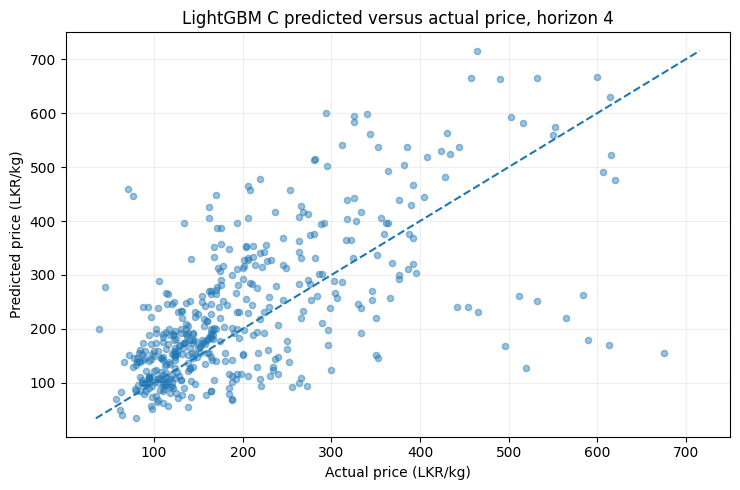

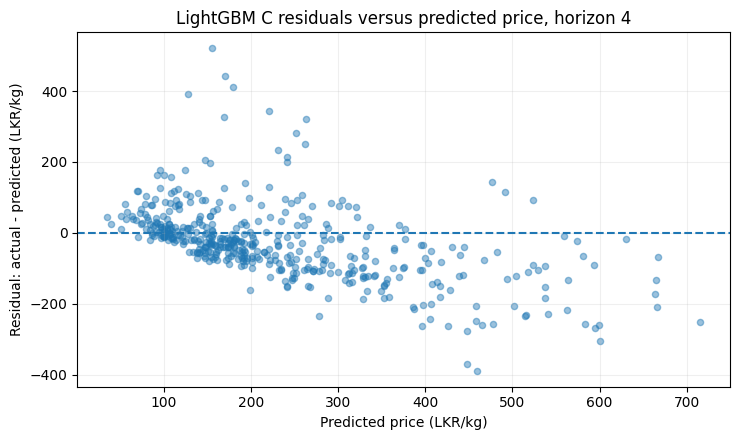

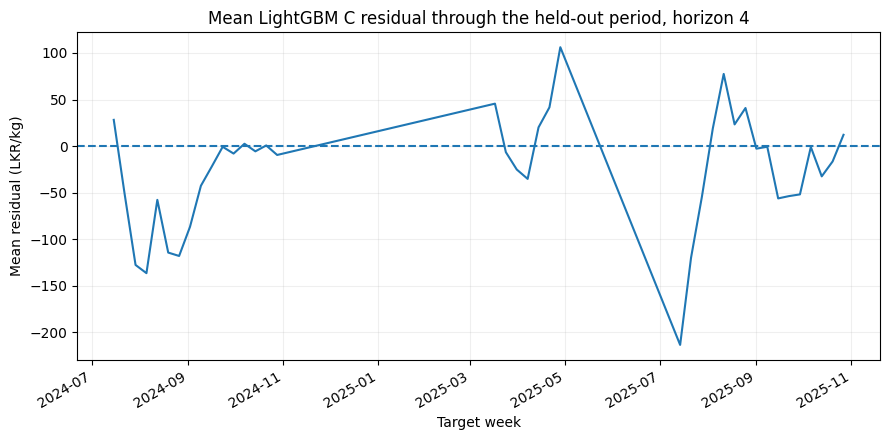

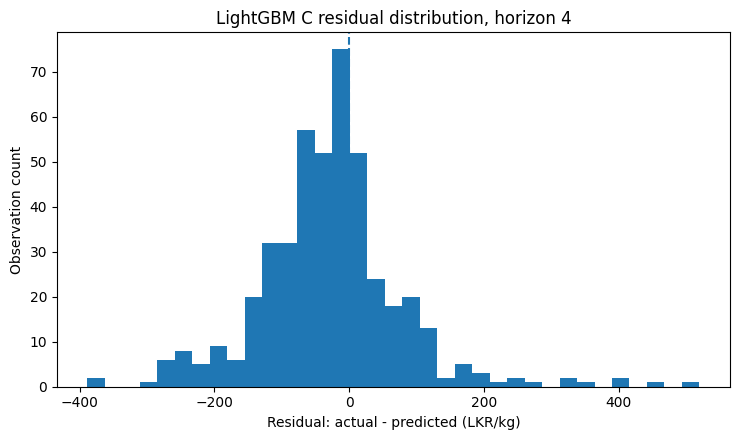


RESIDUAL SUMMARY
   model feature_set  horizon   n  mean_residual_actual_minus_predicted  median_residual  residual_std
lightgbm           C        4 453                              -28.0299         -27.7485      107.6147
saved robustness and residual artifacts


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

C_DIR = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
)

c_predictions = pd.read_csv(
    C_DIR / "predictions_c.csv"
)

for col in [
    "forecast_issue_week",
    "target_week",
]:
    c_predictions[col] = pd.to_datetime(
        c_predictions[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

c_eligible = pd.read_parquet(
    C_DIR / "c_eligible_table.parquet"
)

for col in [
    "forecast_issue_week",
    "target_week",
]:
    c_eligible[col] = pd.to_datetime(
        c_eligible[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

def normalize_key(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[\s\-]+", "_", regex=True)
        .str.replace(r"_+", "_", regex=True)
    )

c_h4 = c_predictions[
    c_predictions["model"]
    .astype(str)
    .str.lower()
    .eq("lightgbm")
    & c_predictions["split"]
    .astype(str)
    .str.lower()
    .eq("test")
    & c_predictions["horizon"].eq(4)
].copy()

c_h4["crop_key"] = normalize_key(
    c_h4["crop"]
)
c_h4["market_key"] = normalize_key(
    c_h4["market"]
)

context = c_eligible[
    c_eligible[
        "forecast_horizon_weeks"
    ].eq(4)
    & c_eligible["split"].eq("test")
].copy()

context["crop_key"] = normalize_key(
    context["crop_id"]
)
context["market_key"] = normalize_key(
    context["market_id"]
)

context_cols = [
    "crop_key",
    "market_key",
    "forecast_issue_week",
    "target_week",
    "cultivation_exact_season_id",
]

context = context[
    context_cols
].drop_duplicates(
    [
        "crop_key",
        "market_key",
        "forecast_issue_week",
        "target_week",
    ]
)

c_h4 = c_h4.merge(
    context,
    on=[
        "crop_key",
        "market_key",
        "forecast_issue_week",
        "target_week",
    ],
    how="left",
    validate="many_to_one",
)

c_h4["season"] = (
    c_h4[
        "cultivation_exact_season_id"
    ]
    .astype("string")
    .str.extract(
        r"^(Maha|Yala)\b",
        expand=False,
    )
)

if c_h4["season"].isna().any():
    raise SystemExit(
        "Official source-season family is missing in h4 robustness."
    )

c_h4["shock_status"] = np.where(
    c_h4[
        "forecast_issue_week"
    ].between(
        pd.Timestamp("2024-01-01"),
        pd.Timestamp("2024-03-31"),
        inclusive="both",
    ),
    "2024_Q1_shock",
    "outside_shock",
)

def group_metrics(frame, key):
    rows = []

    for value, part in frame.groupby(
        key,
        dropna=False,
    ):
        y_true = part[
            "y_true"
        ].to_numpy(
            dtype=float
        )
        y_pred = part[
            "y_pred"
        ].to_numpy(
            dtype=float
        )

        error = (
            y_pred - y_true
        )
        abs_error = np.abs(
            error
        )

        rows.append(
            {
                key: value,
                "n": int(
                    len(part)
                ),
                "mae": float(
                    np.mean(abs_error)
                ),
                "rmse": float(
                    np.sqrt(
                        np.mean(
                            error ** 2
                        )
                    )
                ),
                "mape": float(
                    np.mean(
                        abs_error
                        / np.clip(
                            np.abs(y_true),
                            1e-6,
                            None,
                        )
                    )
                    * 100
                ),
                "mean_bias": float(
                    np.mean(error)
                ),
            }
        )

    return pd.DataFrame(
        rows
    )

by_crop = group_metrics(
    c_h4,
    "crop",
)
by_market = group_metrics(
    c_h4,
    "market",
)
by_season = group_metrics(
    c_h4,
    "season",
)
shock_rows_c = c_h4[
    c_h4["shock_status"].eq(
        "2024_Q1_shock"
    )
]

if shock_rows_c.empty:
    by_shock = pd.DataFrame(
        [
            {
                "shock_status": "not_evaluable_no_real_C_rows_in_2024_Q1",
                "n": 0,
                "mae": np.nan,
                "rmse": np.nan,
                "mape": np.nan,
                "mean_bias": np.nan,
            }
        ]
    )
else:
    by_shock = group_metrics(
        c_h4,
        "shock_status",
    )

# Experiment B supplies the disruption-period benchmark when C has no
# real cultivation-progress coverage in the 2024 Q1 shock slice.
b_predictions = pd.read_csv(
    DRIVE
    / "01_from_notebook1"
    / "experiment_b"
    / "predictions.csv"
)

b_predictions["forecast_issue_week"] = pd.to_datetime(
    b_predictions["forecast_issue_week"],
    format="mixed",
    errors="raise",
).dt.normalize()

b_h4 = b_predictions[
    b_predictions["model"]
    .astype(str)
    .str.lower()
    .eq("lightgbm")
    & b_predictions["feature_set"]
    .astype(str)
    .eq("B")
    & b_predictions["split"]
    .astype(str)
    .str.lower()
    .eq("test")
    & b_predictions["horizon"].eq(4)
].copy()

b_h4["shock_status"] = np.where(
    b_h4["forecast_issue_week"].between(
        pd.Timestamp("2024-01-01"),
        pd.Timestamp("2024-03-31"),
        inclusive="both",
    ),
    "2024_Q1_shock",
    "outside_shock",
)

b_shock = group_metrics(
    b_h4,
    "shock_status",
)

by_crop.to_csv(
    EVAL_DIR
    / "robustness_c_h4_by_crop.csv",
    index=False,
)
by_market.to_csv(
    EVAL_DIR
    / "robustness_c_h4_by_market.csv",
    index=False,
)
by_season.to_csv(
    EVAL_DIR
    / "robustness_c_h4_by_season.csv",
    index=False,
)
by_shock.to_csv(
    EVAL_DIR
    / "robustness_c_h4_shock_vs_nonshock.csv",
    index=False,
)

b_shock.to_csv(
    EVAL_DIR
    / "robustness_b_h4_shock_vs_nonshock.csv",
    index=False,
)

print("LIGHTGBM C H4 — BY CROP")
print(
    by_crop.round(4).to_string(
        index=False
    )
)

print("\nLIGHTGBM C H4 — BY MARKET")
print(
    by_market.round(4).to_string(
        index=False
    )
)

print("\nLIGHTGBM C H4 — BY SEASON")
print(
    by_season.round(4).to_string(
        index=False
    )
)

print("\nLIGHTGBM C H4 — SHOCK ROBUSTNESS")
print(
    by_shock.round(4).to_string(
        index=False
    )
)

if shock_rows_c.empty:
    print(
        "C shock evaluation is not available because no eligible "
        "real national cultivation-progress rows exist in 2024 Q1."
    )

print("\nLIGHTGBM B H4 — SHOCK ROBUSTNESS")
print(
    b_shock.round(4).to_string(
        index=False
    )
)

c_h4["residual"] = (
    c_h4["y_true"]
    - c_h4["y_pred"]
)

residual_summary = pd.DataFrame(
    [
        {
            "model": "lightgbm",
            "feature_set": "C",
            "horizon": 4,
            "n": int(
                len(c_h4)
            ),
            "mean_residual_actual_minus_predicted": float(
                c_h4[
                    "residual"
                ].mean()
            ),
            "median_residual": float(
                c_h4[
                    "residual"
                ].median()
            ),
            "residual_std": float(
                c_h4[
                    "residual"
                ].std(
                    ddof=1
                )
            ),
        }
    ]
)

residual_summary.to_csv(
    EVAL_DIR
    / "residual_summary_c_h4.csv",
    index=False,
)

fig, ax = plt.subplots(
    figsize=(7.5, 5)
)

ax.scatter(
    c_h4["y_true"],
    c_h4["y_pred"],
    alpha=0.45,
    s=20,
)

lower = float(
    min(
        c_h4["y_true"].min(),
        c_h4["y_pred"].min(),
    )
)
upper = float(
    max(
        c_h4["y_true"].max(),
        c_h4["y_pred"].max(),
    )
)

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
)

ax.set_title(
    "LightGBM C predicted versus actual price, horizon 4"
)
ax.set_xlabel(
    "Actual price (LKR/kg)"
)
ax.set_ylabel(
    "Predicted price (LKR/kg)"
)
ax.grid(alpha=0.2)
fig.tight_layout()

actual_pred_plot = (
    PLOT_DIR
    / "final_c_h4_predicted_vs_actual.png"
)

fig.savefig(
    actual_pred_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

fig, ax = plt.subplots(
    figsize=(7.5, 4.5)
)

ax.scatter(
    c_h4["y_pred"],
    c_h4["residual"],
    alpha=0.45,
    s=20,
)

ax.axhline(
    0,
    linestyle="--",
)

ax.set_title(
    "LightGBM C residuals versus predicted price, horizon 4"
)
ax.set_xlabel(
    "Predicted price (LKR/kg)"
)
ax.set_ylabel(
    "Residual: actual - predicted (LKR/kg)"
)
ax.grid(alpha=0.2)
fig.tight_layout()

resid_plot = (
    PLOT_DIR
    / "final_c_h4_residual_vs_predicted.png"
)

fig.savefig(
    resid_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

time_residual = (
    c_h4.groupby(
        "target_week",
        as_index=False,
    )["residual"]
    .mean()
    .sort_values(
        "target_week"
    )
)

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

ax.plot(
    time_residual["target_week"],
    time_residual["residual"],
)

ax.axhline(
    0,
    linestyle="--",
)

ax.set_title(
    "Mean LightGBM C residual through the held-out period, horizon 4"
)
ax.set_xlabel(
    "Target week"
)
ax.set_ylabel(
    "Mean residual (LKR/kg)"
)
ax.grid(alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()

resid_time_plot = (
    PLOT_DIR
    / "final_c_h4_residual_over_time.png"
)

fig.savefig(
    resid_time_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

fig, ax = plt.subplots(
    figsize=(7.5, 4.5)
)

ax.hist(
    c_h4["residual"],
    bins=35,
)

ax.axvline(
    0,
    linestyle="--",
)

ax.set_title(
    "LightGBM C residual distribution, horizon 4"
)
ax.set_xlabel(
    "Residual: actual - predicted (LKR/kg)"
)
ax.set_ylabel(
    "Observation count"
)
fig.tight_layout()

resid_hist_plot = (
    PLOT_DIR
    / "final_c_h4_residual_histogram.png"
)

fig.savefig(
    resid_hist_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

print("\nRESIDUAL SUMMARY")
print(
    residual_summary.round(4).to_string(
        index=False
    )
)

print("saved robustness and residual artifacts")


## Cell 21 — Feature-set evolution and uncertainty around the novelty result

The feature experiments answer two different questions:

- **A → B:** do weather, macroeconomic variables and finished-season extent add value beyond price lags and seasonality?
- **B* → C:** on exactly the same real-progress eligible observations, does current national cultivation progress add predictive value?

The B*→C effect is also summarized with a moving-block bootstrap over target weeks. This gives an uncertainty interval around the mean absolute-error difference while preserving short local runs of weekly observations.

A negative B*→C error difference favors Experiment C.


FEATURE-SET EVOLUTION — LIGHTGBM
 comparison  horizon  baseline_mae  extended_mae  mae_change_pct
     A_to_B        1         82.28         77.40           -5.93
     A_to_B        2        100.86         93.48           -7.32
     A_to_B        4        126.60        110.14          -13.00
     A_to_B        8        153.99        110.05          -28.53
     A_to_B       12        159.26        110.09          -30.87
B_star_to_C        1         57.88         59.75            3.23
B_star_to_C        2         65.90         64.94           -1.46
B_star_to_C        4         83.58         80.04           -4.24
B_star_to_C        8        131.02        118.40           -9.63
B_star_to_C       12        171.62        166.88           -2.76

B* → C PAIRED MOVING-BLOCK BOOTSTRAP
 horizon  n_matched_rows  n_target_weeks  mean_mae_difference_c_minus_b_star  bootstrap_95_ci_low  bootstrap_95_ci_high  ci_entirely_below_zero  ci_entirely_above_zero
       1             462              39      

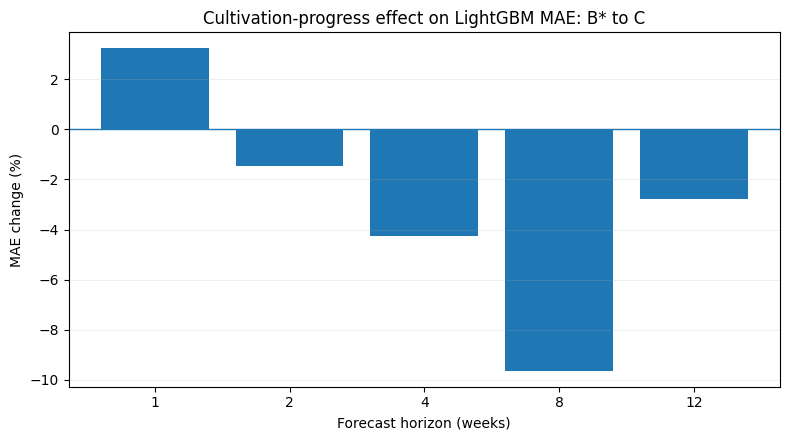

saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/feature_set_evolution.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/bstar_vs_c_block_bootstrap.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/final_bstar_to_c_mae_change.png
Bootstrap intervals describe uncertainty in the observed paired MAE difference; they are not a causal test.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A_VS_B_PATH = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_b"
    / "a_vs_b.csv"
)

C_DIR = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
)

a_vs_b = pd.read_csv(
    A_VS_B_PATH
)

b_star_vs_c = pd.read_csv(
    C_DIR / "b_star_vs_c.csv"
)

ab_lgb = (
    a_vs_b[
        a_vs_b["model"]
        .astype(str)
        .str.lower()
        .eq("lightgbm")
    ][
        [
            "horizon",
            "mae_a",
            "mae_b",
            "mae_change_pct",
        ]
    ]
    .copy()
)

ab_lgb["comparison"] = "A_to_B"
ab_lgb = ab_lgb.rename(
    columns={
        "mae_a": "baseline_mae",
        "mae_b": "extended_mae",
    }
)

bc_lgb = (
    b_star_vs_c[
        b_star_vs_c["model"]
        .astype(str)
        .str.lower()
        .eq("lightgbm")
    ][
        [
            "horizon",
            "mae_b_star",
            "mae_c",
            "mae_change_pct",
        ]
    ]
    .copy()
)

bc_lgb["comparison"] = "B_star_to_C"
bc_lgb = bc_lgb.rename(
    columns={
        "mae_b_star": "baseline_mae",
        "mae_c": "extended_mae",
    }
)

feature_evolution = pd.concat(
    [
        ab_lgb[
            [
                "comparison",
                "horizon",
                "baseline_mae",
                "extended_mae",
                "mae_change_pct",
            ]
        ],
        bc_lgb[
            [
                "comparison",
                "horizon",
                "baseline_mae",
                "extended_mae",
                "mae_change_pct",
            ]
        ],
    ],
    ignore_index=True,
)

feature_evolution.to_csv(
    EVAL_DIR
    / "feature_set_evolution.csv",
    index=False,
)

print("FEATURE-SET EVOLUTION — LIGHTGBM")
print(
    feature_evolution.round(4).to_string(
        index=False
    )
)

b_pred = pd.read_csv(
    C_DIR / "predictions_b_star.csv"
)
c_pred = pd.read_csv(
    C_DIR / "predictions_c.csv"
)

for frame in [
    b_pred,
    c_pred,
]:
    for col in [
        "forecast_issue_week",
        "target_week",
    ]:
        frame[col] = pd.to_datetime(
            frame[col],
            format="mixed",
            errors="raise",
        ).dt.normalize()

KEY = [
    "crop",
    "market",
    "forecast_issue_week",
    "target_week",
    "horizon",
]

def moving_block_ci(values, block_length=4, reps=2000, seed=42):
    values = np.asarray(
        values,
        dtype=float,
    )

    n = len(values)

    if n == 0:
        return (
            np.nan,
            np.nan,
        )

    block_length = int(
        max(
            1,
            min(
                block_length,
                n,
            ),
        )
    )

    rng = np.random.default_rng(
        seed
    )

    samples = np.empty(
        reps,
        dtype=float,
    )

    blocks_needed = int(
        np.ceil(
            n / block_length
        )
    )

    for rep in range(reps):
        starts = rng.integers(
            0,
            n,
            size=blocks_needed,
        )

        indices = []

        for start in starts:
            indices.extend(
                (
                    start
                    + np.arange(
                        block_length
                    )
                )
                % n
            )

        indices = np.asarray(
            indices[:n],
            dtype=int,
        )

        samples[rep] = float(
            np.mean(
                values[indices]
            )
        )

    return (
        float(
            np.quantile(
                samples,
                0.025,
            )
        ),
        float(
            np.quantile(
                samples,
                0.975,
            )
        ),
    )

bootstrap_rows = []

for horizon in sorted(
    c_pred["horizon"].unique()
):
    b = b_pred[
        b_pred["model"]
        .astype(str)
        .str.lower()
        .eq("lightgbm")
        & b_pred["split"]
        .astype(str)
        .str.lower()
        .eq("test")
        & b_pred["horizon"].eq(horizon)
    ][
        KEY + ["y_true", "y_pred"]
    ].copy()

    c = c_pred[
        c_pred["model"]
        .astype(str)
        .str.lower()
        .eq("lightgbm")
        & c_pred["split"]
        .astype(str)
        .str.lower()
        .eq("test")
        & c_pred["horizon"].eq(horizon)
    ][
        KEY + ["y_true", "y_pred"]
    ].copy()

    pair = b.merge(
        c,
        on=KEY,
        how="inner",
        suffixes=(
            "_b_star",
            "_c",
        ),
        validate="one_to_one",
    )

    if not np.allclose(
        pair["y_true_b_star"],
        pair["y_true_c"],
        rtol=0,
        atol=1e-8,
    ):
        raise SystemExit(
            f"B* and C truth values differ at h={horizon}."
        )

    pair["ae_b_star"] = np.abs(
        pair["y_pred_b_star"]
        - pair["y_true_b_star"]
    )

    pair["ae_c"] = np.abs(
        pair["y_pred_c"]
        - pair["y_true_c"]
    )

    pair["ae_difference_c_minus_b_star"] = (
        pair["ae_c"]
        - pair["ae_b_star"]
    )

    weekly_difference = (
        pair.groupby(
            "target_week",
            as_index=False,
        )[
            "ae_difference_c_minus_b_star"
        ]
        .mean()
        .sort_values(
            "target_week"
        )
    )

    ci_low, ci_high = moving_block_ci(
        weekly_difference[
            "ae_difference_c_minus_b_star"
        ],
        block_length=4,
        reps=2000,
        seed=42 + int(horizon),
    )

    mean_difference = float(
        pair[
            "ae_difference_c_minus_b_star"
        ].mean()
    )

    bootstrap_rows.append(
        {
            "horizon": int(
                horizon
            ),
            "n_matched_rows": int(
                len(pair)
            ),
            "n_target_weeks": int(
                len(
                    weekly_difference
                )
            ),
            "mean_mae_difference_c_minus_b_star": mean_difference,
            "bootstrap_95_ci_low": ci_low,
            "bootstrap_95_ci_high": ci_high,
            "ci_entirely_below_zero": bool(
                ci_high < 0
            ),
            "ci_entirely_above_zero": bool(
                ci_low > 0
            ),
        }
    )

bootstrap = pd.DataFrame(
    bootstrap_rows
)

bootstrap.to_csv(
    EVAL_DIR
    / "bstar_vs_c_block_bootstrap.csv",
    index=False,
)

print(
    "\nB* → C PAIRED MOVING-BLOCK BOOTSTRAP"
)
print(
    bootstrap.round(4).to_string(
        index=False
    )
)

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

bc_plot = bc_lgb.sort_values(
    "horizon"
)

ax.bar(
    bc_plot[
        "horizon"
    ].astype(str),
    bc_plot[
        "mae_change_pct"
    ],
)

ax.axhline(
    0,
    linewidth=1,
)

ax.set_title(
    "Cultivation-progress effect on LightGBM MAE: B* to C"
)
ax.set_xlabel(
    "Forecast horizon (weeks)"
)
ax.set_ylabel(
    "MAE change (%)"
)
ax.grid(
    axis="y",
    alpha=0.2,
)
fig.tight_layout()

novelty_plot = (
    PLOT_DIR
    / "final_bstar_to_c_mae_change.png"
)

fig.savefig(
    novelty_plot,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

print("saved", EVAL_DIR / "feature_set_evolution.csv")
print("saved", EVAL_DIR / "bstar_vs_c_block_bootstrap.csv")
print("saved", novelty_plot)
print(
    "Bootstrap intervals describe uncertainty in the observed "
    "paired MAE difference; they are not a causal test."
)


## Cell 22 — SHAP explainability for the primary four-week C model

SHAP is used as supporting evidence to show which inputs influence the fitted LightGBM median model.

The controlled B*→C ablation remains the direct test of whether cultivation progress adds predictive information. SHAP values describe model behaviour; they do not establish causality.


LIGHTGBM C HORIZON-4 SHAP IMPORTANCE
                      feature  mean_abs_shap
                 usd_lkr_rate       0.008455
        forecast_week_of_year       0.007177
          price_change_4w_pct       0.004011
           week_within_season       0.003219
                price_mean_8w       0.002555
                price_lag_52w       0.002496
                 price_lag_8w       0.002238
           inflation_rate_pct       0.001806
                      crop_id       0.001769
                 price_lag_2w       0.001318
                 price_lag_1w       0.000658
    origin_rainfall_sum_8w_mm       0.000633
                price_mean_4w       0.000499
origin_rainfall_anomaly_4w_mm       0.000011
                 price_lag_4w       0.000000
            season_transition       0.000000
        origin_rainfall_1w_mm       0.000000
        origin_mean_temp_4w_c       0.000000
       diesel_price_lkr_litre       0.000000
    origin_rainfall_sum_4w_mm       0.000000


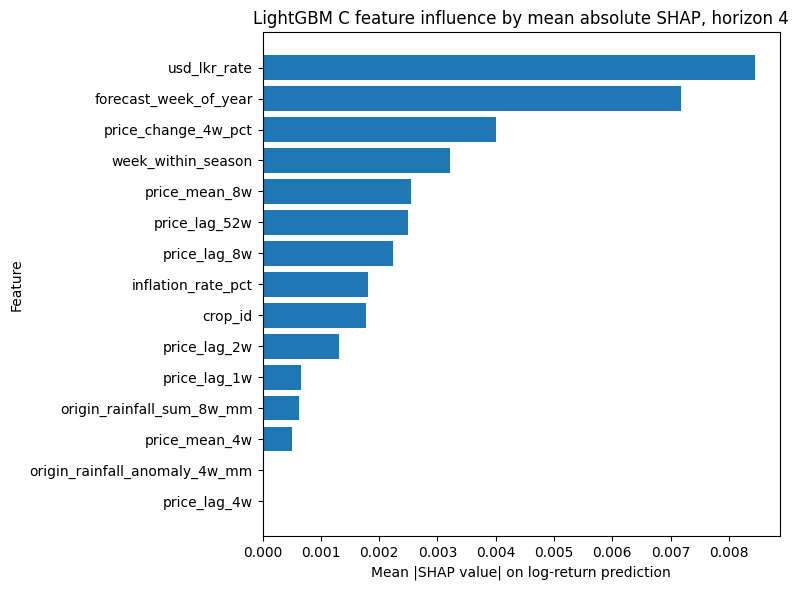

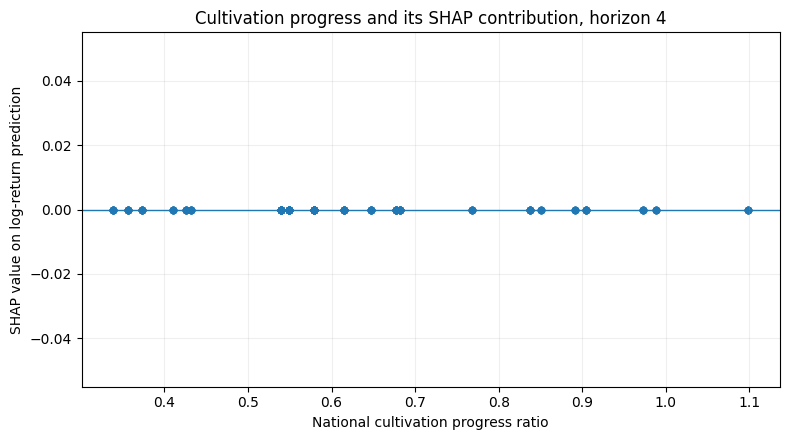

saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/shap_cultivation_progress_h4.png
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/evaluation/shap_lightgbm_c_h4.csv
saved /content/drive/MyDrive/DS322-member2/01_from_notebook1/plots/shap_lightgbm_c_h4_top_features.png
SHAP is explanatory support; the B* versus C ablation is the novelty test.


In [30]:
import importlib.util
import subprocess
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if importlib.util.find_spec("shap") is None:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "shap",
        ]
    )

import shap

C_DIR = (
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
)

bundle = joblib.load(
    C_DIR
    / "models"
    / "lightgbm_C_h4_q50.joblib"
)

model = bundle["model"]
model_columns = list(
    bundle["columns"]
)

c_eligible = pd.read_parquet(
    C_DIR
    / "c_eligible_table.parquet"
)

FEATURES_C_FINAL = FEATURES_B + [
    "cultivation_progress_ratio_real",
    "cultivation_target_exceeded_real",
]

subset = eligible(
    c_eligible,
    4,
)

matrix, _ = design_matrix(
    subset,
    FEATURES_C_FINAL,
)

missing_columns = [
    name
    for name in model_columns
    if name not in matrix.columns
]

if missing_columns:
    raise SystemExit(
        "SHAP matrix is missing saved model columns: "
        f"{missing_columns}"
    )

score_mask = (
    subset["split"].eq("test")
    & subset["market_id"].isin(
        EVAL_IDS
    )
)

X_test = (
    matrix.loc[
        score_mask,
        model_columns,
    ]
    .astype("float64")
)

if X_test.empty:
    raise SystemExit(
        "No held-out horizon-4 C rows are available for SHAP."
    )

MAX_SHAP_ROWS = 600

if len(X_test) > MAX_SHAP_ROWS:
    X_shap = X_test.sample(
        n=MAX_SHAP_ROWS,
        random_state=42,
    )
else:
    X_shap = X_test.copy()

explainer = shap.TreeExplainer(
    model
)

shap_values = explainer.shap_values(
    X_shap
)

if isinstance(
    shap_values,
    list,
):
    shap_values = shap_values[0]

shap_values = np.asarray(
    shap_values,
    dtype=float,
)

if shap_values.ndim != 2:
    raise SystemExit(
        f"Unexpected SHAP array shape: {shap_values.shape}"
    )

mean_abs = np.mean(
    np.abs(
        shap_values
    ),
    axis=0,
)

importance = pd.DataFrame(
    {
        "feature": model_columns,
        "mean_abs_shap": mean_abs,
    }
).sort_values(
    "mean_abs_shap",
    ascending=False,
)

importance.to_csv(
    EVAL_DIR
    / "shap_lightgbm_c_h4.csv",
    index=False,
)

print("LIGHTGBM C HORIZON-4 SHAP IMPORTANCE")
print(
    importance.head(20).to_string(
        index=False
    )
)

top = (
    importance.head(15)
    .sort_values(
        "mean_abs_shap"
    )
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.barh(
    top["feature"],
    top["mean_abs_shap"],
)

ax.set_title(
    "LightGBM C feature influence by mean absolute SHAP, horizon 4"
)
ax.set_xlabel(
    "Mean |SHAP value| on log-return prediction"
)
ax.set_ylabel(
    "Feature"
)
fig.tight_layout()

shap_bar_path = (
    PLOT_DIR
    / "shap_lightgbm_c_h4_top_features.png"
)

fig.savefig(
    shap_bar_path,
    dpi=140,
    bbox_inches="tight",
)

plt.show()

progress_feature = (
    "cultivation_progress_ratio_real"
)

if progress_feature in model_columns:
    feature_position = model_columns.index(
        progress_feature
    )

    fig, ax = plt.subplots(
        figsize=(8, 4.5)
    )

    ax.scatter(
        X_shap[
            progress_feature
        ],
        shap_values[
            :,
            feature_position
        ],
        alpha=0.5,
        s=20,
    )

    ax.axhline(
        0,
        linewidth=1,
    )

    ax.set_title(
        "Cultivation progress and its SHAP contribution, horizon 4"
    )
    ax.set_xlabel(
        "National cultivation progress ratio"
    )
    ax.set_ylabel(
        "SHAP value on log-return prediction"
    )
    ax.grid(
        alpha=0.2,
    )
    fig.tight_layout()

    shap_progress_path = (
        PLOT_DIR
        / "shap_cultivation_progress_h4.png"
    )

    fig.savefig(
        shap_progress_path,
        dpi=140,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "saved",
        shap_progress_path,
    )

print(
    "saved",
    EVAL_DIR
    / "shap_lightgbm_c_h4.csv",
)
print(
    "saved",
    shap_bar_path,
)
print(
    "SHAP is explanatory support; "
    "the B* versus C ablation is the novelty test."
)


## Cell 23 — Final model-selection and evaluation report

This report keeps the approved proposal as the core methodology and adds supplementary evidence expected in strong forecasting work:

- common-key benchmark;
- persistence and seasonal-naive baselines;
- MASE and persistence-relative skill;
- paired block-bootstrap uncertainty versus persistence;
- probabilistic calibration;
- quantile-consistency diagnostics;
- conditional coverage by crop, market, season and quarter;
- A→B and B*→C ablation;
- robustness and residual diagnostics;
- SHAP explainability.

The report makes comparative claims only against the models and baselines actually evaluated. It does not claim universal superiority over every forecasting system.


In [31]:
import pandas as pd

def markdown_table(frame):
    if frame is None or frame.empty:
        return "_No rows available._"

    cols = list(
        frame.columns
    )

    lines = [
        "| "
        + " | ".join(
            cols
        )
        + " |",
        "| "
        + " | ".join(
            "---"
            for _ in cols
        )
        + " |",
    ]

    for row in frame.itertuples(
        index=False,
        name=None,
    ):
        values = []

        for value in row:
            if isinstance(
                value,
                float,
            ):
                text = (
                    ""
                    if pd.isna(value)
                    else f"{value:.4f}"
                )
            else:
                text = str(value)

            values.append(
                text.replace(
                    "|",
                    "\\|",
                )
            )

        lines.append(
            "| "
            + " | ".join(
                values
            )
            + " |"
        )

    return "\n".join(
        lines
    )

benchmark_final = pd.read_csv(
    EVAL_DIR
    / "final_point_forecast_benchmark.csv"
)

best_final = pd.read_csv(
    EVAL_DIR
    / "best_point_model_by_horizon.csv"
)

seasonal_final = pd.read_csv(
    EVAL_DIR
    / "seasonal_naive_common_subset.csv"
)

model_vs_naive_final = pd.read_csv(
    EVAL_DIR
    / "model_vs_naive_block_bootstrap.csv"
)

quantile_crossing_final = pd.read_csv(
    EVAL_DIR
    / "quantile_crossing_diagnostic_c.csv"
)

conditional_interval_final = pd.read_csv(
    EVAL_DIR
    / "conditional_interval_evaluation_c.csv"
)

prob_final = pd.read_csv(
    EVAL_DIR
    / "final_probabilistic_evaluation_c.csv"
)

feature_final = pd.read_csv(
    EVAL_DIR
    / "feature_set_evolution.csv"
)

bootstrap_final = pd.read_csv(
    EVAL_DIR
    / "bstar_vs_c_block_bootstrap.csv"
)

crop_final = pd.read_csv(
    EVAL_DIR
    / "robustness_c_h4_by_crop.csv"
)

market_final = pd.read_csv(
    EVAL_DIR
    / "robustness_c_h4_by_market.csv"
)

season_final = pd.read_csv(
    EVAL_DIR
    / "robustness_c_h4_by_season.csv"
)

shock_final = pd.read_csv(
    EVAL_DIR
    / "robustness_c_h4_shock_vs_nonshock.csv"
)

shock_b_final = pd.read_csv(
    EVAL_DIR
    / "robustness_b_h4_shock_vs_nonshock.csv"
)

residual_final = pd.read_csv(
    EVAL_DIR
    / "residual_summary_c_h4.csv"
)

shap_final = pd.read_csv(
    EVAL_DIR
    / "shap_lightgbm_c_h4.csv"
)

c_compare_final = pd.read_csv(
    DRIVE
    / "01_from_notebook1"
    / "experiment_c"
    / "b_star_vs_c.csv"
)

primary_c = (
    c_compare_final[
        c_compare_final["model"]
        .astype(str)
        .str.lower()
        .eq("lightgbm")
    ]
    .sort_values("horizon")
)

h4 = primary_c[
    primary_c["horizon"].eq(4)
].iloc[0]

best_lines = []

for row in best_final.sort_values(
    "horizon"
).itertuples():
    best_lines.append(
        f"- {int(row.horizon)} week(s): "
        f"{row.model} — MAE {row.mae:.2f} LKR/kg, "
        f"MAE skill vs persistence {row.mae_skill_vs_naive_pct:.2f}%."
    )

best_text = "\n".join(
    best_lines
)

report = f"""# Final model evaluation — Member 2

## Evaluation design

The task is continuous weekly wholesale-price forecasting.

Chronology:
- model-selection training: eligible targets through 2021-12-31;
- internal early-stopping validation: eligible target weeks in 2022;
- final tree refit: all eligible training rows through 2022-12-31;
- conformal calibration: untouched 2023 block;
- held-out test: 2024–2025.

No random train/test split is used. The 2023 conformal-calibration block is never used for early stopping or model selection.

Forecast accuracy is evaluated with MAE, RMSE, MAPE, sMAPE, WAPE, MASE, mean bias and persistence-relative skill. R² is included as a supplementary regression statistic. A persistence baseline is scored on every common test row, while a 52-week seasonal-naive benchmark is reported on the identical subset where a genuine 52-week lag exists. Probabilistic quality is evaluated with pinball loss, empirical PICP, interval width and 90% interval score.

## Fair common-key benchmark

{markdown_table(benchmark_final)}

## Best point-forecast model by horizon

{markdown_table(best_final)}

{best_text}

There is no single point model that dominates every horizon.

## Seasonal-naive benchmark on identical eligible rows

{markdown_table(seasonal_final)}

The seasonal-naive comparison is kept separate because not every held-out row has a valid observed 52-week lag.

## Paired fitted-model versus persistence uncertainty

{markdown_table(model_vs_naive_final)}

Negative mean MAE differences favor the fitted model. The moving-block bootstrap is supplementary uncertainty analysis and does not create a universal superiority claim.

## Model-selection interpretation

For pure point accuracy, the horizon-specific winners above are the appropriate benchmark result.

For the research component, LightGBM remains the primary probabilistic model because it supports the controlled A/B/C feature experiment, quantile forecasts, conformal calibration and SHAP analysis. Experiment C is therefore evaluated as the cultivation-aware extension of that primary model rather than being described as the universal lowest-error model.

## Experiment C probabilistic evaluation

{markdown_table(prob_final)}

The intended interval level is 90%. Empirical PICP is reported rather than treated as a mathematical guarantee for future dependent observations. CQR is implemented directly from the split-conformal quantile score calculation, with 2023 reserved exclusively for calibration.

## Quantile-consistency diagnostic

{markdown_table(quantile_crossing_final)}

Raw independently trained quantile heads are audited for crossing. The reported interval uses a documented ordered projection around the unchanged q50 point forecast, so every published lower/median/upper triplet is ordered. Raw crossing rates remain visible rather than hidden.

## Conditional interval evaluation

{markdown_table(conditional_interval_final)}

Conditional PICP and width are diagnostic checks by crop, market, official cultivation-season family and year-quarter. Overall horizon-level coverage remains the primary calibration result. No unknown season bucket is permitted.

## Feature-set evolution

{markdown_table(feature_final)}

A→B and B*→C answer different questions and are not combined into one absolute-MAE ranking.

## Cultivation-progress novelty

At the four-week horizon, the primary LightGBM B* MAE was {h4['mae_b_star']:.2f} LKR/kg and C MAE was {h4['mae_c']:.2f} LKR/kg, a relative change of {h4['mae_change_pct']:.2f}%.

The result is interpreted by horizon. Cultivation progress is not claimed to improve every forecast horizon.

## Uncertainty around B*→C MAE difference

{markdown_table(bootstrap_final)}

The moving-block bootstrap is supplementary uncertainty analysis around the observed paired MAE difference. It is not a causal test.

## Four-week robustness

### By crop

{markdown_table(crop_final)}

### By market

{markdown_table(market_final)}

### By season

{markdown_table(season_final)}

### 2024 Q1 disruption analysis

Experiment C:

{markdown_table(shock_final)}

If the C table reports `not_evaluable_no_real_C_rows_in_2024_Q1`, the predefined disruption slice cannot be scored for C because no eligible real national cultivation-progress observations exist in that period.

Experiment B disruption benchmark:

{markdown_table(shock_b_final)}

## Residual diagnostics

{markdown_table(residual_final)}

Residual plots are saved with the notebook artifacts to inspect bias, dispersion and time structure beyond aggregate metrics.

## Explainability

Top SHAP features for the four-week LightGBM C median model:

{markdown_table(shap_final.head(15))}

SHAP describes fitted-model behaviour. The controlled B*→C experiment remains the direct test of the cultivation-progress contribution.

## Final conclusion

The forecasting engine is evaluated with chronological held-out testing, statistical and machine-learning baselines, persistence and seasonal-naive references, multiple point-forecast metrics including MASE, paired uncertainty versus persistence, probabilistic calibration metrics, quantile-consistency checks, conditional coverage diagnostics, controlled feature ablation, robustness slices, residual diagnostics and explainability.

The point-forecast winner depends on horizon. The cultivation-aware LightGBM C model is retained as the primary research model for the novelty and probabilistic forecasting objectives, while its contribution is reported as horizon-dependent rather than universally beneficial.

The evidence supports comparative claims only against the baselines and fitted models evaluated here. It does not support a claim that this system is universally better than every published forecasting method.
"""

report_path = (
    EVAL_DIR
    / "model_evaluation_summary.md"
)

report_path.write_text(
    report,
    encoding="utf-8",
)

print(report)
print("\nsaved", report_path)


# Final model evaluation — Member 2

## Evaluation design

The task is continuous weekly wholesale-price forecasting.

Chronology:
- model-selection training: eligible targets through 2021-12-31;
- internal early-stopping validation: eligible target weeks in 2022;
- final tree refit: all eligible training rows through 2022-12-31;
- conformal calibration: untouched 2023 block;
- held-out test: 2024–2025.

No random train/test split is used. The 2023 conformal-calibration block is never used for early stopping or model selection.

Forecast accuracy is evaluated with MAE, RMSE, MAPE, sMAPE, WAPE, MASE, mean bias and persistence-relative skill. R² is included as a supplementary regression statistic. A persistence baseline is scored on every common test row, while a 52-week seasonal-naive benchmark is reported on the identical subset where a genuine 52-week lag exists. Probabilistic quality is evaluated with pinball loss, empirical PICP, interval width and 90% interval score.

## Fair commo

## Cell 24 — Final artifact manifest

The manifest confirms that the training, benchmark, uncertainty, robustness, novelty and explainability artifacts required by Notebook 2 are present.


In [32]:
from pathlib import Path
import pandas as pd

root = DRIVE / "01_from_notebook1"

required = [
    "audit/leakage_checks.csv",
    "audit/decisions.csv",
    "audit/doa_source_vs_observation_season_mismatch.csv",
    "panel/analysis_ready_panel.parquet",
    "panel/training_table.parquet",
    "experiment_a/predictions.csv",
    "experiment_a/metrics_by_model_horizon.csv",
    "experiment_a/sarimax_order.json",
    "experiment_a/models/lightgbm_A_h4_q50.joblib",
    "experiment_a/models/training_protocol.json",
    "experiment_a/models/xgboost_A_h4_q50.joblib",
    "experiment_b/predictions.csv",
    "experiment_b/metrics_with_cqr.csv",
    "experiment_b/a_vs_b.csv",
    "experiment_b/cqr.json",
    "experiment_b/live_vectors.json",
    "experiment_b/models/lightgbm_B_h1_q50.joblib",
    "experiment_b/models/lightgbm_B_h4_q05.joblib",
    "experiment_b/models/lightgbm_B_h4_q50.joblib",
    "experiment_b/models/lightgbm_B_h4_q95.joblib",
    "experiment_b/models/training_protocol.json",
    "experiment_c/status.json",
    "experiment_c/b_star_vs_c.csv",
    "experiment_c/metrics_b_star.csv",
    "experiment_c/metrics_c.csv",
    "experiment_c/predictions_b_star.csv",
    "experiment_c/predictions_c.csv",
    "experiment_c/c_eligible_table.parquet",
    "experiment_c/live_vectors.json",
    "experiment_c/models/lightgbm_C_h4_q50.joblib",
    "experiment_c/models/training_protocol.json",
    "experiment_c/models_b_star/training_protocol.json",
    "evaluation/final_point_forecast_benchmark.csv",
    "evaluation/best_point_model_by_horizon.csv",
    "evaluation/seasonal_naive_common_subset.csv",
    "evaluation/mase_scale_52w_by_series.csv",
    "evaluation/model_vs_naive_block_bootstrap.csv",
    "evaluation/final_probabilistic_evaluation_c.csv",
    "evaluation/quantile_crossing_diagnostic_c.csv",
    "evaluation/conditional_interval_evaluation_c.csv",
    "evaluation/feature_set_evolution.csv",
    "evaluation/bstar_vs_c_block_bootstrap.csv",
    "evaluation/robustness_c_h4_by_crop.csv",
    "evaluation/robustness_c_h4_by_market.csv",
    "evaluation/robustness_c_h4_by_season.csv",
    "evaluation/robustness_c_h4_shock_vs_nonshock.csv",
    "evaluation/robustness_b_h4_shock_vs_nonshock.csv",
    "evaluation/residual_summary_c_h4.csv",
    "evaluation/shap_lightgbm_c_h4.csv",
    "evaluation/model_evaluation_summary.md",
    "notes/hyperparameters.txt",
    "notes/validation_protocol.json",
    "notes/environment_versions.json",
]

missing = [
    name
    for name in required
    if not (
        root / name
    ).is_file()
]

if missing:
    print("Missing final artifacts:")
    for name in missing:
        print(" -", name)

    raise SystemExit(
        "Notebook 1 is not complete."
    )

rows = []

for path in sorted(
    root.rglob("*")
):
    if (
        path.is_file()
        and path.name
        != "manifest.csv"
    ):
        rows.append(
            {
                "path": str(
                    path.relative_to(
                        root
                    )
                ),
                "bytes": path.stat().st_size,
            }
        )

manifest = pd.DataFrame(
    rows
)

manifest_path = (
    root / "manifest.csv"
)

manifest.to_csv(
    manifest_path,
    index=False,
)

print(
    manifest.to_string(
        index=False
    )
)

print("\nNOTEBOOK 1 COMPLETE")
print(
    "Training, held-out benchmarking, uncertainty evaluation, "
    "robustness, novelty analysis and explainability are complete."
)
print(
    "Notebook 2 must use these saved artifacts and must not retrain."
)
print("saved", manifest_path)


                                                     path   bytes
                             audit/c_readiness_counts.csv     235
                                 audit/cleaning_rules.csv     852
                               audit/coverage_by_crop.csv     143
                             audit/coverage_by_market.csv     278
                                 audit/coverage_focus.csv    2436
                                      audit/decisions.csv    1077
               audit/doa_cultivation_progress_audited.csv   84992
              audit/doa_cultivation_progress_coverage.csv     797
     audit/doa_cultivation_progress_national_coverage.csv     737
        audit/doa_progress_asof_exact_season_coverage.csv     219
                audit/doa_progress_asof_year_coverage.csv     229
      audit/doa_source_vs_observation_season_mismatch.csv     125
                           audit/doa_zero_target_rows.csv   33411
                                 audit/leakage_checks.csv    1529
          